<center><h1>1-cd: Convolutional Neural Networks (ConvNets)</h1></center>

<center><h2><a href="https://rdfia.github.io/">Course link</a></h2></center>

# Warning :
# Do "File -> Save a copy in Drive" before you start modifying the notebook, otherwise your modifications will not be saved.


In [1]:
#!git clone https://github.com/cdancette/deep-learning-polytech-tp6-7.git
! wget https://github.com/rdfia/rdfia.github.io/raw/master/code/2-cd/utils.py

--2026-11-14 14:56:27--  https://github.com/rdfia/rdfia.github.io/raw/master/code/2-cd/utils.py
Resolving github.com (github.com)... 48.200.82.112
Connecting to github.com (github.com)|48.200.82.112|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/code/2-cd/utils.py [following]
--2026-11-14 14:56:27--  https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/code/2-cd/utils.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2627 (2.6K) [text/plain]
Saving to: ‘utils.py’

utils.py            100%[===================>]   2.57K  --.-KB/s    in 0s      

2026-11-14 14:56:27 (46.1 MB/s) - ‘utils.py’ saved [2627/2627]



In [2]:
%run 'utils.py'

In [3]:
import argparse
import os
import time

import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim
import torch.utils.data
import torchvision.transforms as transforms
import torchvision.datasets as datasets

from utils import *

PRINT_INTERVAL = 200
PATH="datasets"

In [4]:
class ConvNet(nn.Module):
    """
    This class defines the structure of the neural network
    """

    def __init__(self):
        super(ConvNet, self).__init__()
        # We first define the convolution and pooling layers as a features extractor
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, (5, 5), stride=1, padding=2),
            nn.Tanh(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),
            nn.Conv2d(6, 16, (5, 5), stride=1, padding=0),
            nn.Tanh(),
            nn.MaxPool2d((2, 2), stride=2, padding=0),
        )
        # We then define fully connected layers as a classifier
        self.classifier = nn.Sequential(
            nn.Linear(400, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
            # Reminder: The softmax is included in the loss, do not put it here
        )

    # Method called when we apply the network to an input batch
    def forward(self, input):
        bsize = input.size(0) # batch size
        output = self.features(input) # output of the conv layers
        output = output.view(bsize, -1) # we flatten the 2D feature maps into one 1D vector for each input
        output = self.classifier(output) # we compute the output of the fc layers
        return output



def get_dataset(batch_size, cuda=False):
    """
    This function loads the dataset and performs transformations on each
    image (listed in `transform = ...`).
    """
    train_dataset = datasets.MNIST(PATH, train=True, download=True,
        transform=transforms.Compose([
            transforms.ToTensor()
        ]))
    val_dataset = datasets.MNIST(PATH, train=False, download=True,
        transform=transforms.Compose([
            transforms.ToTensor()
        ]))

    train_loader = torch.utils.data.DataLoader(train_dataset,
                        batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,
                        batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader



def epoch(data, model, criterion, optimizer=None, cuda=False):
    """
    Make a pass (called epoch in English) on the data `data` with the
     model `model`. Evaluates `criterion` as loss.
     If `optimizer` is given, perform a training epoch using
     the given optimizer, otherwise, perform an evaluation epoch (no backward)
     of the model.
    """

    # indicates whether the model is in eval or train mode (some layers behave differently in train and eval)
    model.eval() if optimizer is None else model.train()

    # objects to store metric averages
    avg_loss = AverageMeter()
    avg_top1_acc = AverageMeter()
    avg_top5_acc = AverageMeter()
    avg_batch_time = AverageMeter()
    global loss_plot

    # we iterate on the batches
    tic = time.time()
    for i, (input, target) in enumerate(data):

        if cuda: # only with GPU, and not with CPU
            input = input.cuda()
            target = target.cuda()

        # forward
        output = model(input)
        loss = criterion(output, target)

        # backward if we are training
        if optimizer:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # compute metrics
        prec1, prec5 = accuracy(output, target, topk=(1, 5))
        batch_time = time.time() - tic
        tic = time.time()

        # update
        avg_loss.update(loss.item())
        avg_top1_acc.update(prec1.item())
        avg_top5_acc.update(prec5.item())
        avg_batch_time.update(batch_time)
        if optimizer:
            loss_plot.update(avg_loss.val)
        # print info
        if i % PRINT_INTERVAL == 0:
            print('[{0:s} Batch {1:03d}/{2:03d}]\t'
                  'Time {batch_time.val:.3f}s ({batch_time.avg:.3f}s)\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec@1 {top1.val:5.1f} ({top1.avg:5.1f})\t'
                  'Prec@5 {top5.val:5.1f} ({top5.avg:5.1f})'.format(
                   "EVAL" if optimizer is None else "TRAIN", i, len(data), batch_time=avg_batch_time, loss=avg_loss,
                   top1=avg_top1_acc, top5=avg_top5_acc))
            if optimizer:
                loss_plot.plot()

    # Print summary
    print('\n===============> Total time {batch_time:d}s\t'
          'Avg loss {loss.avg:.4f}\t'
          'Avg Prec@1 {top1.avg:5.2f} %\t'
          'Avg Prec@5 {top5.avg:5.2f} %\n'.format(
           batch_time=int(avg_batch_time.sum), loss=avg_loss,
           top1=avg_top1_acc, top5=avg_top5_acc))

    return avg_top1_acc, avg_top5_acc, avg_loss


def main(batch_size=128, lr=0.1, epochs=5, cuda=False):

    # ex :
    #   {"batch_size": 128, "epochs": 5, "lr": 0.1}

    # define model, loss, optim
    model = ConvNet()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda: # only with GPU, and not with CPU
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    # Get the data
    train, test = get_dataset(batch_size, cuda)

    # init plots
    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    # We iterate on the epochs
    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        # Train phase
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        # Test phase
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        # plot
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)



class ConvNetCIFAR(nn.Module):

    def __init__(self, batchnorm=False, dropout=0.0):
        super(ConvNetCIFAR, self).__init__()
        layers = []
        for c_in, c_out, ceil in [(3, 32, False), (32, 64, False), (64, 64, True)]:
            layers.append(nn.Conv2d(c_in, c_out, (5, 5), stride=1, padding=2))
            if batchnorm:
                layers.append(nn.BatchNorm2d(c_out))
            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d((2, 2), stride=2, padding=0, ceil_mode=ceil))
        self.features = nn.Sequential(*layers)
        fc_layers = [nn.Linear(64 * 4 * 4, 1000), nn.ReLU()]
        if dropout > 0.0:
            fc_layers.append(nn.Dropout(dropout))
        fc_layers.append(nn.Linear(1000, 10))
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, input):
        bsize = input.size(0)
        output = self.features(input)
        output = output.view(bsize, -1)
        output = self.classifier(output)
        return output



def get_dataset_cifar(batch_size, cuda=False, normalize=False, augment=False):
    train_transform = [transforms.ToTensor()]
    test_transform = [transforms.ToTensor()]
    if augment:
        train_transform = [transforms.RandomCrop(28), transforms.RandomHorizontalFlip()] + train_transform
        test_transform = [transforms.CenterCrop(28)] + test_transform
    if normalize:
        norm = transforms.Normalize(mean=[0.491, 0.482, 0.447], std=[0.202, 0.199, 0.201])
        train_transform.append(norm)
        test_transform.append(norm)

    train_dataset = datasets.CIFAR10(PATH, train=True, download=True,
        transform=transforms.Compose(train_transform))
    val_dataset = datasets.CIFAR10(PATH, train=False, download=True,
        transform=transforms.Compose(test_transform))

    train_loader = torch.utils.data.DataLoader(train_dataset,
                        batch_size=batch_size, shuffle=True, pin_memory=cuda, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,
                        batch_size=batch_size, shuffle=False, pin_memory=cuda, num_workers=2)

    return train_loader, val_loader



def main_cifar(batch_size=128, lr=0.1, epochs=20, cuda=False, normalize=False, augment=False, batchnorm=False, dropout=0.0):

    model = ConvNetCIFAR(batchnorm, dropout)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr)

    if cuda:
        cudnn.benchmark = True
        model = model.cuda()
        criterion = criterion.cuda()

    train, test = get_dataset_cifar(batch_size, cuda, normalize, augment)

    plot = AccLossPlot()
    global loss_plot
    loss_plot = TrainLossPlot()

    for i in range(epochs):
        print("=================\n=== EPOCH "+str(i+1)+" =====\n=================\n")
        top1_acc, avg_top5_acc, loss = epoch(train, model, criterion, optimizer, cuda)
        top1_acc_test, top5_acc_test, loss_test = epoch(test, model, criterion, cuda=cuda)
        plot.update(loss.avg, loss_test.avg, top1_acc.avg, top1_acc_test.avg)

    return top1_acc_test.avg

100%|██████████| 9.91M/9.91M [00:07<00:00, 1.30MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 404kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.76MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.00MB/s]

=== EPOCH 1 =====



[TRAIN Batch 000/469]	Time 2.082s (2.082s)	Loss 2.3043 (2.3043)	Prec@1  15.6 ( 15.6)	Prec@5  50.8 ( 50.8)


<Figure size 640x480 with 0 Axes>

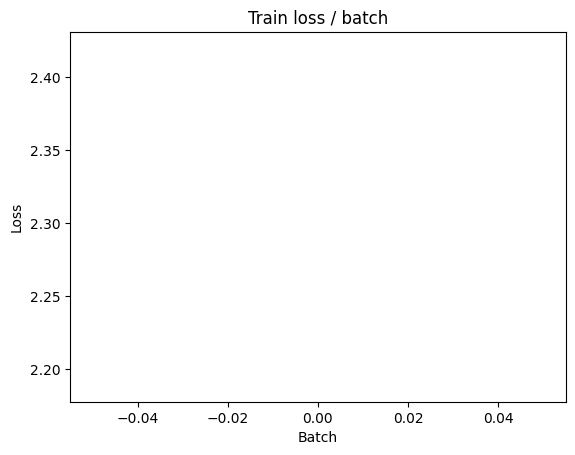

[TRAIN Batch 200/469]	Time 0.018s (0.025s)	Loss 0.4087 (1.1978)	Prec@1  87.5 ( 66.2)	Prec@5  99.2 ( 91.5)


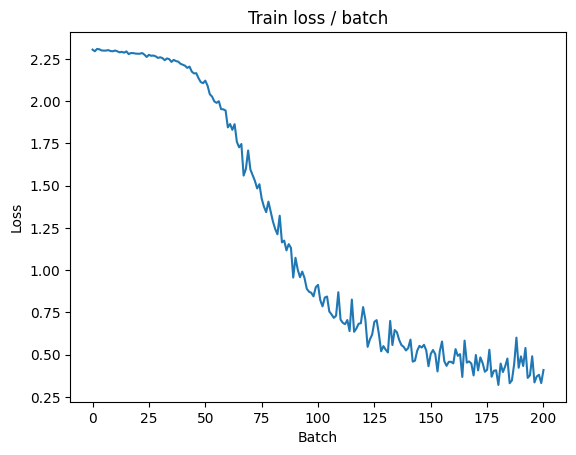

[TRAIN Batch 400/469]	Time 0.020s (0.023s)	Loss 0.3415 (0.7393)	Prec@1  89.1 ( 79.2)	Prec@5 100.0 ( 95.5)


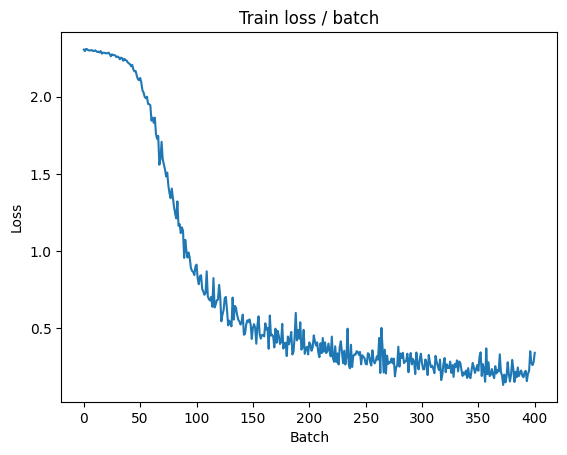


===============> Total time 11s	Avg loss 0.6580	Avg Prec@1 81.48 %	Avg Prec@5 96.13 %

[EVAL Batch 000/079]	Time 0.148s (0.148s)	Loss 0.1006 (0.1006)	Prec@1  98.4 ( 98.4)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.1566	Avg Prec@1 95.39 %	Avg Prec@5 99.91 %



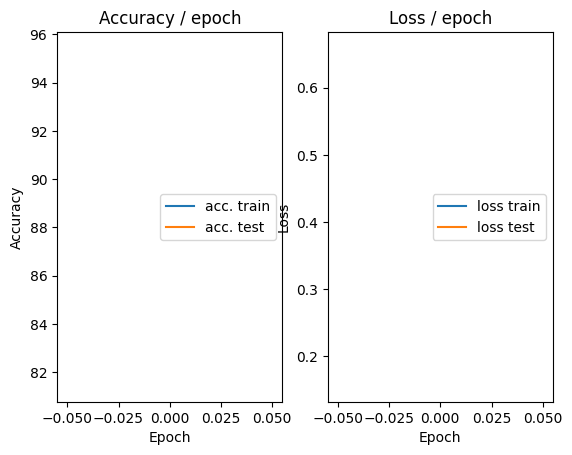

=== EPOCH 2 =====

[TRAIN Batch 000/469]	Time 0.110s (0.110s)	Loss 0.1519 (0.1519)	Prec@1  96.1 ( 96.1)	Prec@5 100.0 (100.0)


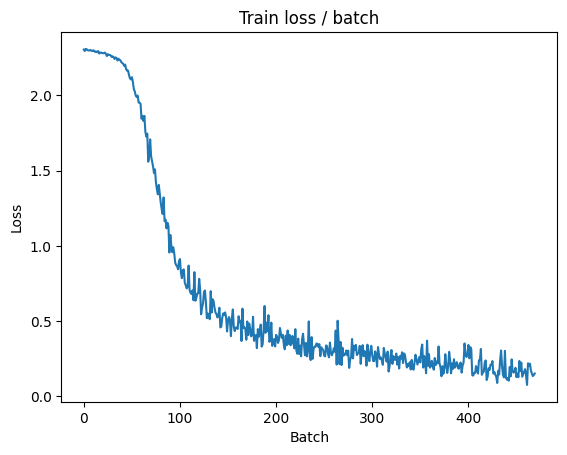

[TRAIN Batch 200/469]	Time 0.003s (0.015s)	Loss 0.2060 (0.1412)	Prec@1  92.2 ( 96.0)	Prec@5 100.0 ( 99.9)


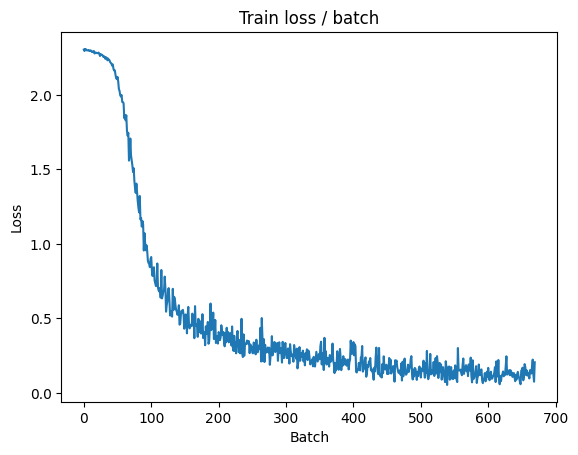

[TRAIN Batch 400/469]	Time 0.013s (0.016s)	Loss 0.1286 (0.1274)	Prec@1  97.7 ( 96.3)	Prec@5 100.0 ( 99.9)


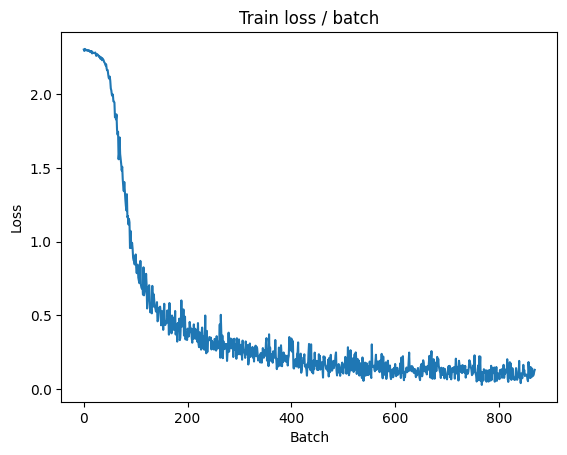


===============> Total time 7s	Avg loss 0.1238	Avg Prec@1 96.41 %	Avg Prec@5 99.90 %

[EVAL Batch 000/079]	Time 0.096s (0.096s)	Loss 0.0493 (0.0493)	Prec@1  98.4 ( 98.4)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.0856	Avg Prec@1 97.40 %	Avg Prec@5 99.99 %



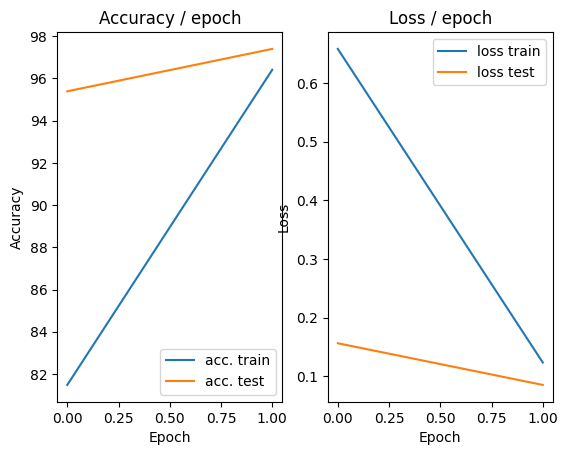

=== EPOCH 3 =====

[TRAIN Batch 000/469]	Time 0.138s (0.138s)	Loss 0.0997 (0.0997)	Prec@1  96.9 ( 96.9)	Prec@5 100.0 (100.0)


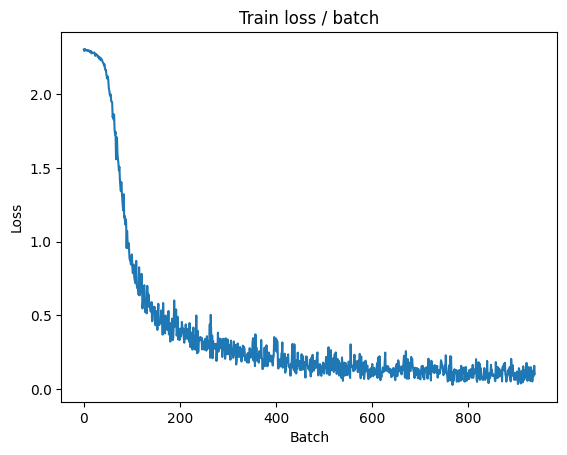

[TRAIN Batch 200/469]	Time 0.013s (0.023s)	Loss 0.0229 (0.0838)	Prec@1 100.0 ( 97.6)	Prec@5 100.0 ( 99.9)


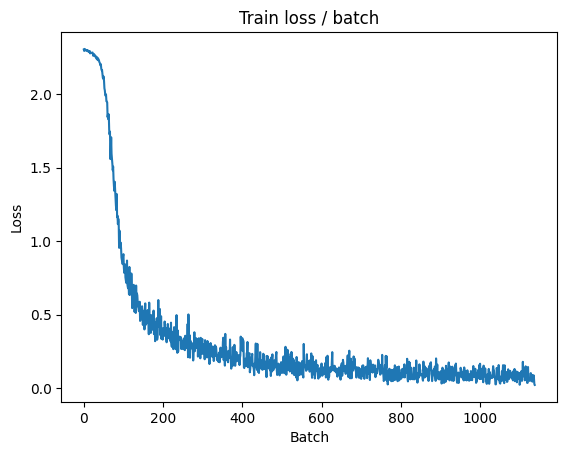

[TRAIN Batch 400/469]	Time 0.022s (0.020s)	Loss 0.0804 (0.0831)	Prec@1  97.7 ( 97.6)	Prec@5 100.0 ( 99.9)


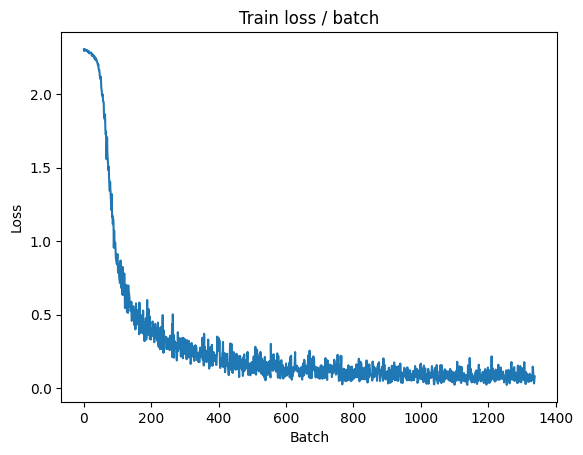


===============> Total time 9s	Avg loss 0.0821	Avg Prec@1 97.62 %	Avg Prec@5 99.95 %

[EVAL Batch 000/079]	Time 0.094s (0.094s)	Loss 0.0373 (0.0373)	Prec@1  99.2 ( 99.2)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.0644	Avg Prec@1 98.02 %	Avg Prec@5 99.99 %



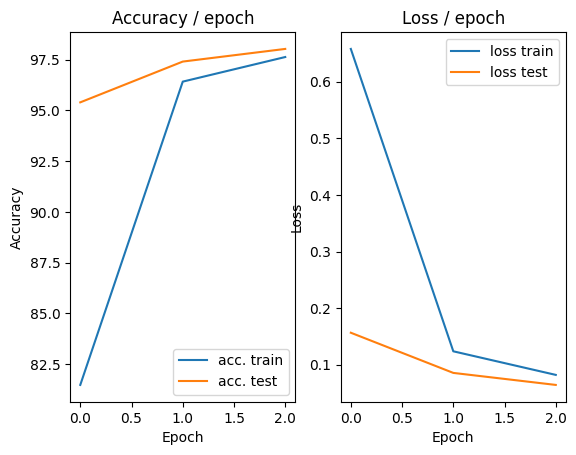

=== EPOCH 4 =====

[TRAIN Batch 000/469]	Time 0.124s (0.124s)	Loss 0.0228 (0.0228)	Prec@1 100.0 (100.0)	Prec@5 100.0 (100.0)


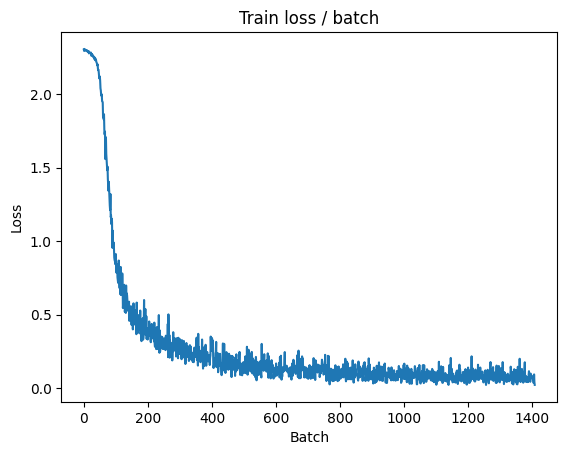

[TRAIN Batch 200/469]	Time 0.007s (0.018s)	Loss 0.0801 (0.0655)	Prec@1  97.7 ( 98.1)	Prec@5 100.0 (100.0)


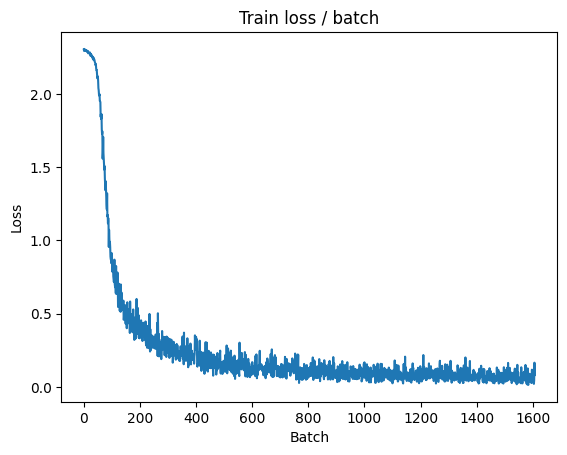

[TRAIN Batch 400/469]	Time 0.015s (0.019s)	Loss 0.0528 (0.0655)	Prec@1  98.4 ( 98.1)	Prec@5 100.0 (100.0)


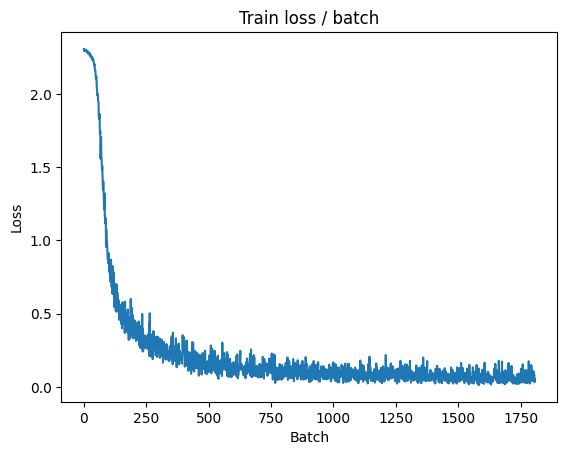


===============> Total time 8s	Avg loss 0.0644	Avg Prec@1 98.07 %	Avg Prec@5 99.98 %

[EVAL Batch 000/079]	Time 0.102s (0.102s)	Loss 0.0217 (0.0217)	Prec@1 100.0 (100.0)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.0514	Avg Prec@1 98.39 %	Avg Prec@5 100.00 %



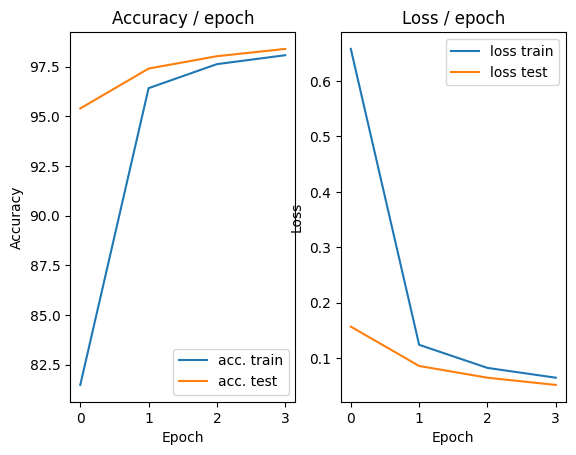

=== EPOCH 5 =====

[TRAIN Batch 000/469]	Time 0.122s (0.122s)	Loss 0.0554 (0.0554)	Prec@1  99.2 ( 99.2)	Prec@5 100.0 (100.0)


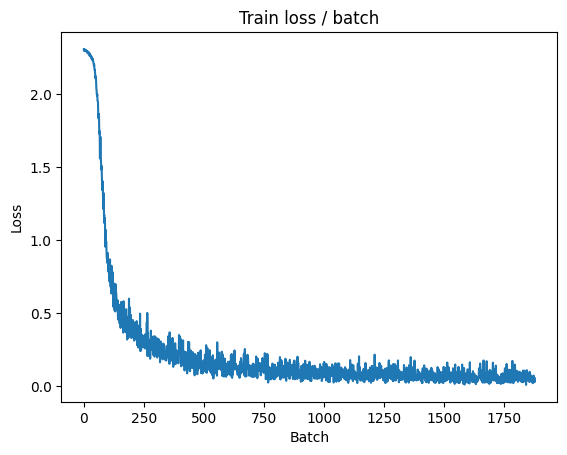

[TRAIN Batch 200/469]	Time 0.015s (0.017s)	Loss 0.0497 (0.0549)	Prec@1  99.2 ( 98.4)	Prec@5 100.0 (100.0)


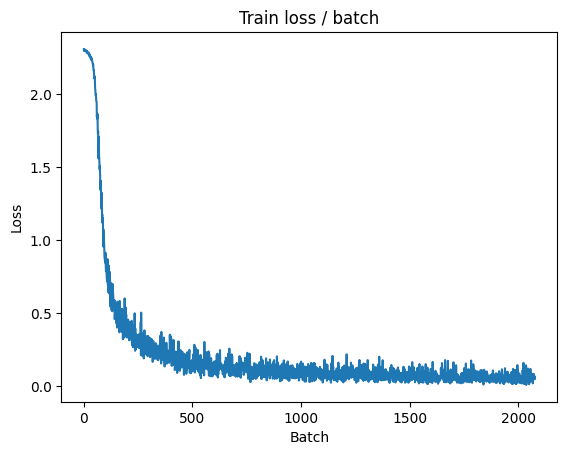

[TRAIN Batch 400/469]	Time 0.039s (0.017s)	Loss 0.0911 (0.0549)	Prec@1  96.9 ( 98.4)	Prec@5 100.0 (100.0)


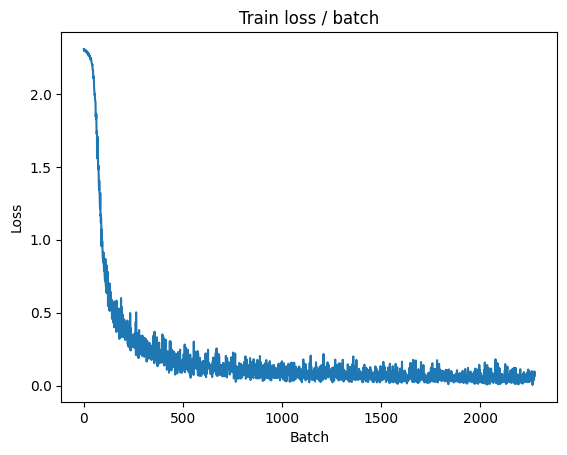


===============> Total time 8s	Avg loss 0.0545	Avg Prec@1 98.40 %	Avg Prec@5 99.98 %

[EVAL Batch 000/079]	Time 0.202s (0.202s)	Loss 0.0155 (0.0155)	Prec@1 100.0 (100.0)	Prec@5 100.0 (100.0)

===============> Total time 1s	Avg loss 0.0482	Avg Prec@1 98.44 %	Avg Prec@5 100.00 %



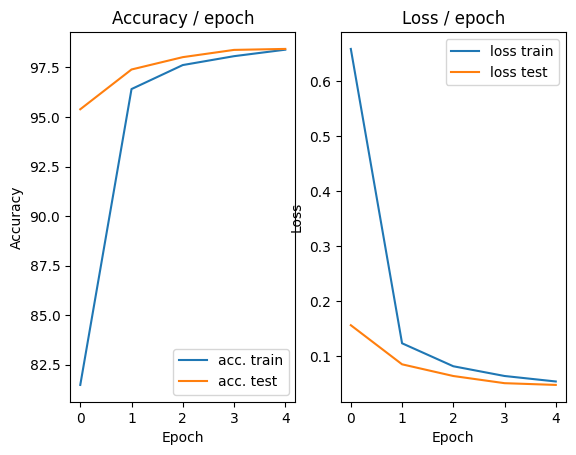

100%|██████████| 170M/170M [01:56<00:00, 1.46MB/s]


=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.552s (0.552s)	Loss 2.3016 (2.3016)	Prec@1   7.8 (  7.8)	Prec@5  48.4 ( 48.4)


<Figure size 640x480 with 0 Axes>

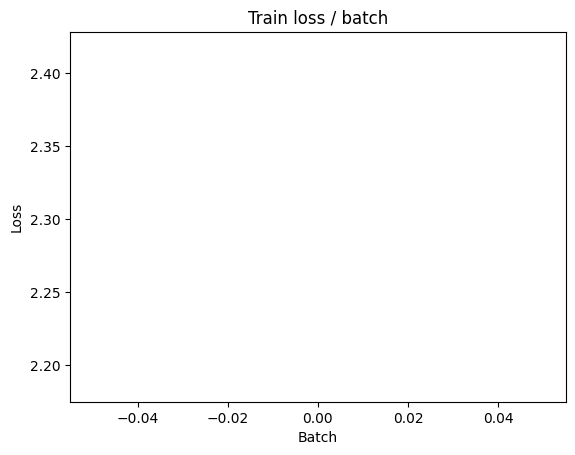

[TRAIN Batch 200/391]	Time 0.022s (0.020s)	Loss 2.0882 (2.2210)	Prec@1  26.6 ( 16.7)	Prec@5  78.9 ( 64.3)


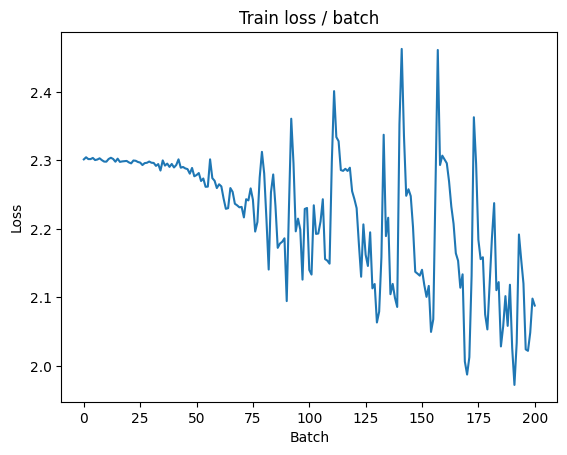


===============> Total time 7s	Avg loss 2.1078	Avg Prec@1 22.29 %	Avg Prec@5 71.42 %

[EVAL Batch 000/079]	Time 0.159s (0.159s)	Loss 1.7082 (1.7082)	Prec@1  36.7 ( 36.7)	Prec@5  89.1 ( 89.1)

===============> Total time 2s	Avg loss 1.7598	Avg Prec@1 36.60 %	Avg Prec@5 86.41 %



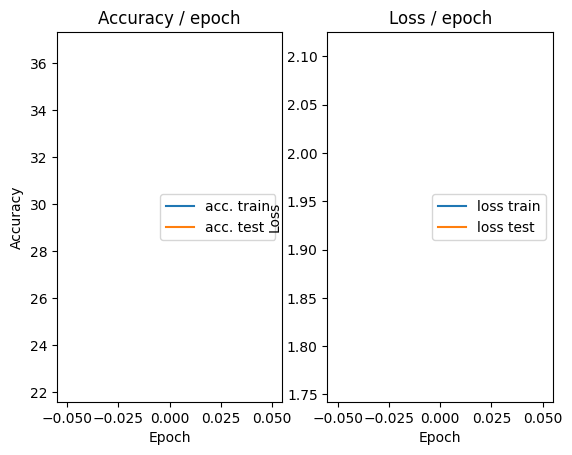

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.125s (0.125s)	Loss 1.7783 (1.7783)	Prec@1  39.1 ( 39.1)	Prec@5  83.6 ( 83.6)


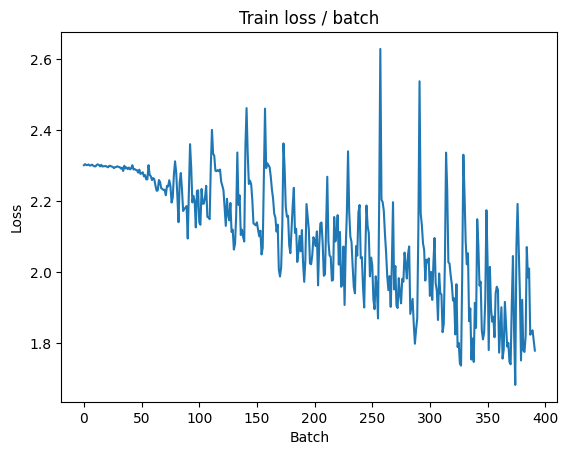

[TRAIN Batch 200/391]	Time 0.013s (0.018s)	Loss 1.6447 (1.7405)	Prec@1  39.1 ( 37.5)	Prec@5  86.7 ( 86.5)


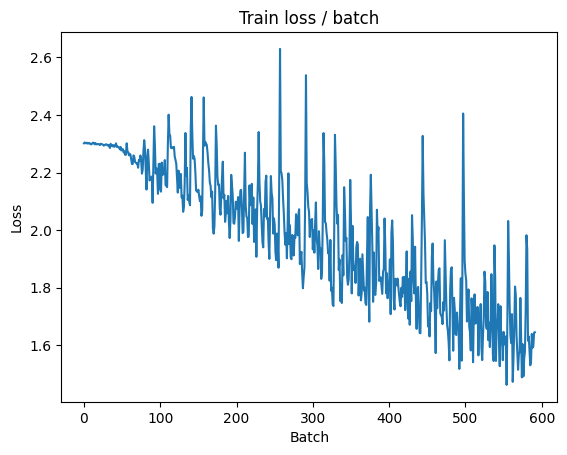


===============> Total time 6s	Avg loss 1.6528	Avg Prec@1 40.74 %	Avg Prec@5 88.48 %

[EVAL Batch 000/079]	Time 0.104s (0.104s)	Loss 1.4550 (1.4550)	Prec@1  46.1 ( 46.1)	Prec@5  90.6 ( 90.6)

===============> Total time 1s	Avg loss 1.5019	Avg Prec@1 46.18 %	Avg Prec@5 91.56 %



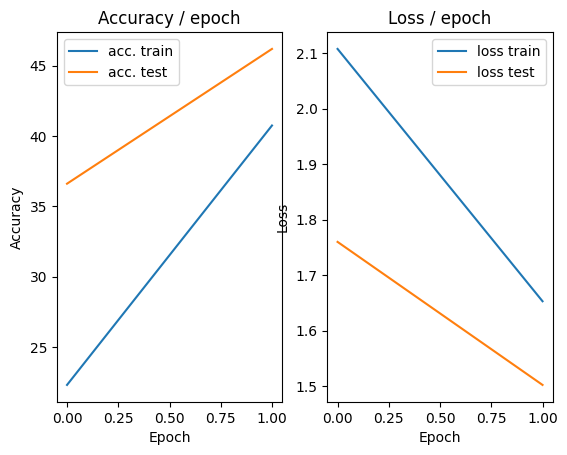

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.122s (0.122s)	Loss 1.5345 (1.5345)	Prec@1  49.2 ( 49.2)	Prec@5  89.1 ( 89.1)


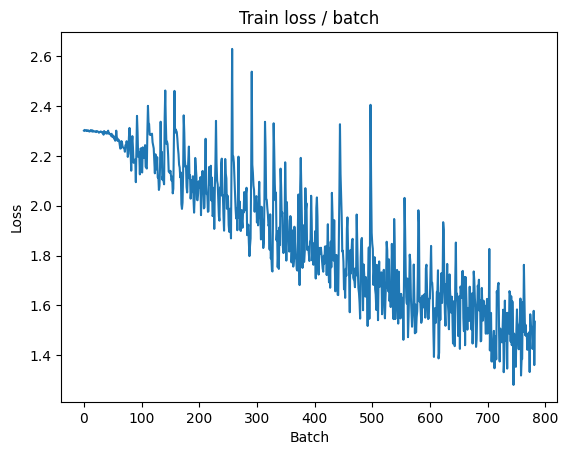

[TRAIN Batch 200/391]	Time 0.013s (0.024s)	Loss 1.4630 (1.4477)	Prec@1  47.7 ( 48.5)	Prec@5  91.4 ( 92.2)


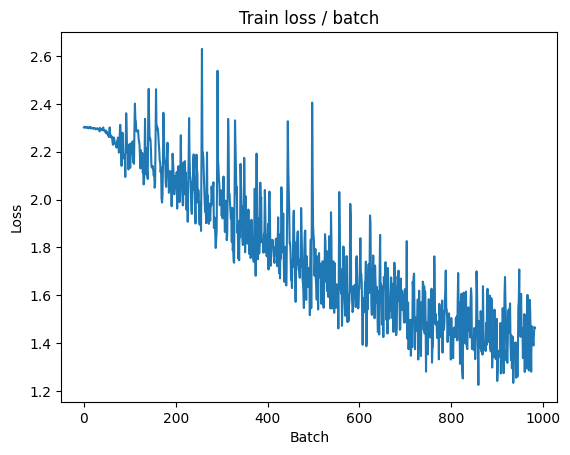


===============> Total time 8s	Avg loss 1.4057	Avg Prec@1 50.00 %	Avg Prec@5 92.79 %

[EVAL Batch 000/079]	Time 0.106s (0.106s)	Loss 1.2351 (1.2351)	Prec@1  60.2 ( 60.2)	Prec@5  93.8 ( 93.8)

===============> Total time 1s	Avg loss 1.2938	Avg Prec@1 53.28 %	Avg Prec@5 94.35 %



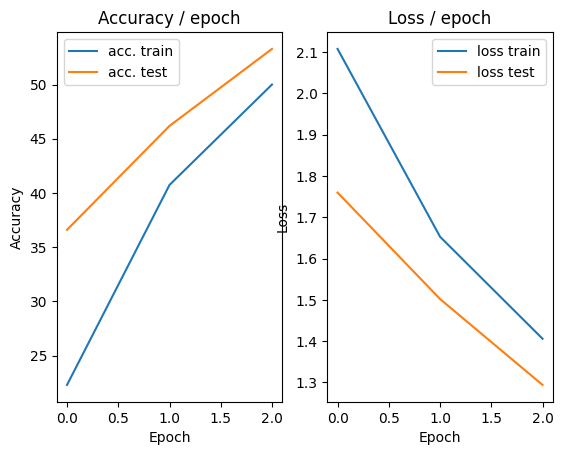

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.145s (0.145s)	Loss 1.3191 (1.3191)	Prec@1  56.2 ( 56.2)	Prec@5  93.8 ( 93.8)


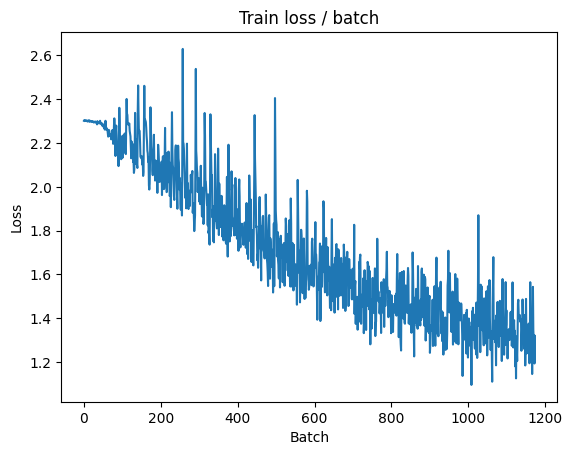

[TRAIN Batch 200/391]	Time 0.012s (0.018s)	Loss 1.2018 (1.2768)	Prec@1  58.6 ( 54.7)	Prec@5  95.3 ( 94.4)


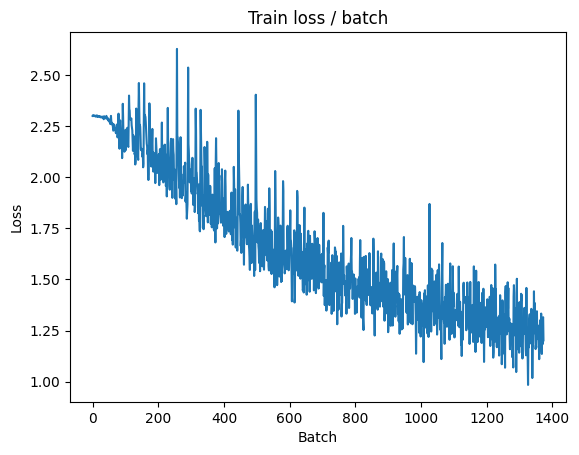


===============> Total time 8s	Avg loss 1.2510	Avg Prec@1 55.80 %	Avg Prec@5 94.57 %

[EVAL Batch 000/079]	Time 0.107s (0.107s)	Loss 1.0496 (1.0496)	Prec@1  63.3 ( 63.3)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.2191	Avg Prec@1 56.64 %	Avg Prec@5 94.43 %



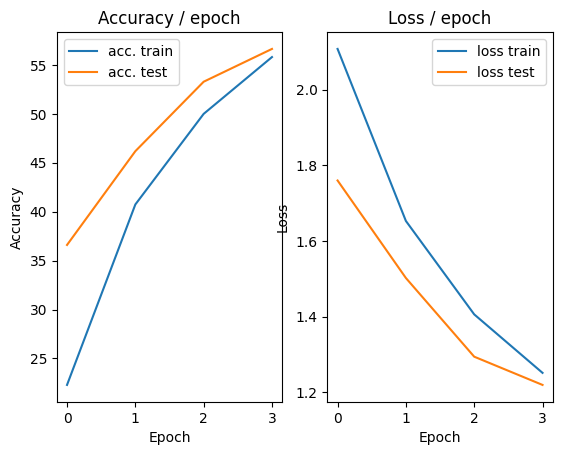

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.145s (0.145s)	Loss 1.0285 (1.0285)	Prec@1  61.7 ( 61.7)	Prec@5  98.4 ( 98.4)


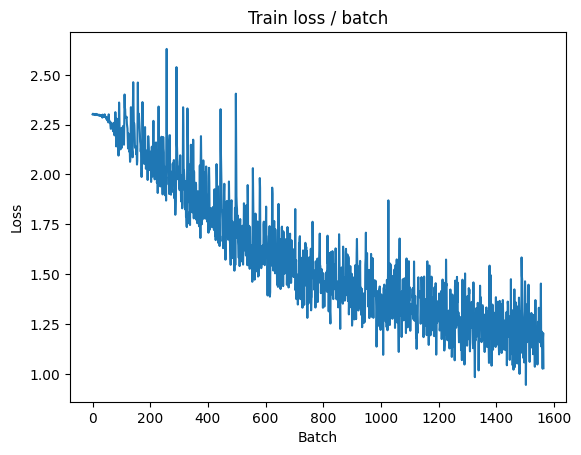

[TRAIN Batch 200/391]	Time 0.010s (0.018s)	Loss 1.1814 (1.1295)	Prec@1  59.4 ( 60.1)	Prec@5  96.1 ( 95.7)


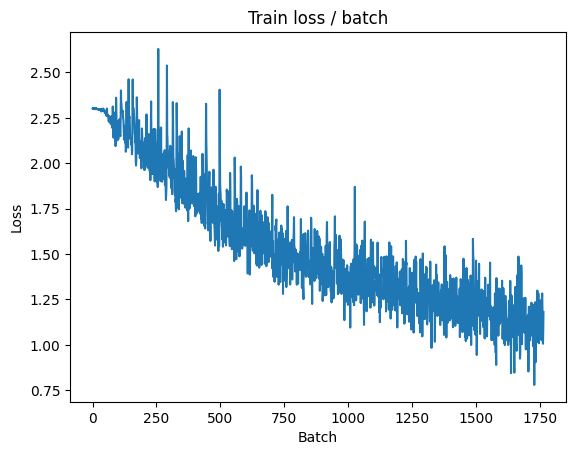


===============> Total time 7s	Avg loss 1.1129	Avg Prec@1 60.76 %	Avg Prec@5 95.82 %

[EVAL Batch 000/079]	Time 0.110s (0.110s)	Loss 1.1132 (1.1132)	Prec@1  64.1 ( 64.1)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.1551	Avg Prec@1 58.71 %	Avg Prec@5 95.71 %



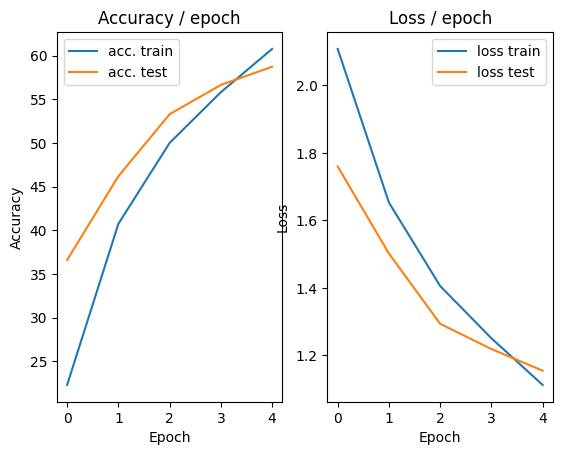

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.204s (0.204s)	Loss 0.9807 (0.9807)	Prec@1  67.2 ( 67.2)	Prec@5  96.9 ( 96.9)


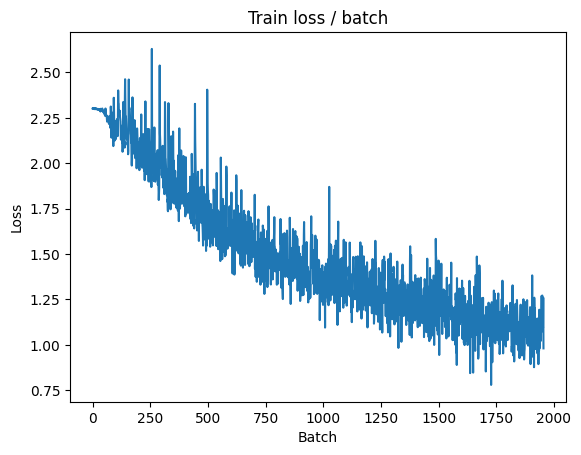

[TRAIN Batch 200/391]	Time 0.012s (0.023s)	Loss 0.9557 (0.9914)	Prec@1  64.8 ( 65.3)	Prec@5  97.7 ( 96.9)


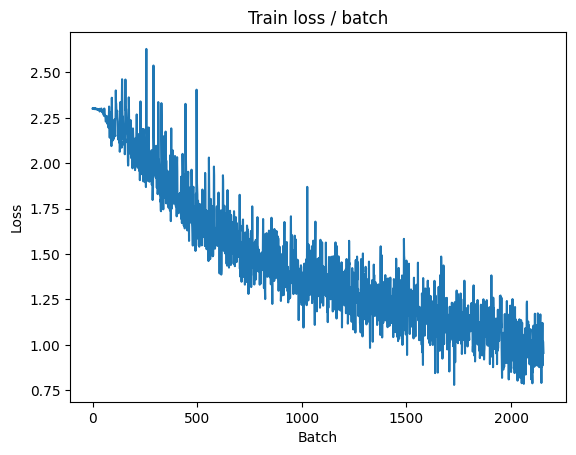


===============> Total time 7s	Avg loss 0.9878	Avg Prec@1 65.40 %	Avg Prec@5 96.90 %

[EVAL Batch 000/079]	Time 0.112s (0.112s)	Loss 1.0619 (1.0619)	Prec@1  65.6 ( 65.6)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.0797	Avg Prec@1 61.64 %	Avg Prec@5 95.92 %



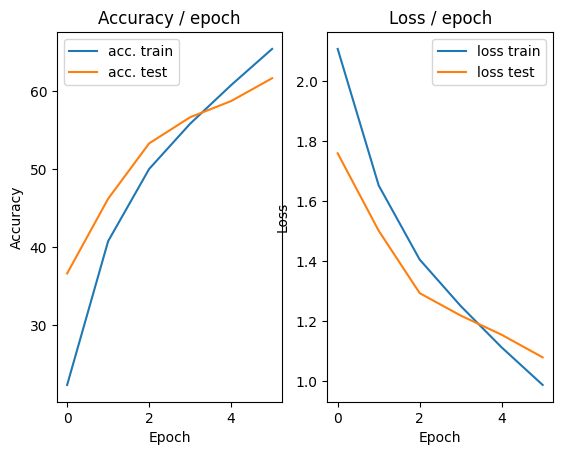

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.147s (0.147s)	Loss 0.7771 (0.7771)	Prec@1  72.7 ( 72.7)	Prec@5  98.4 ( 98.4)


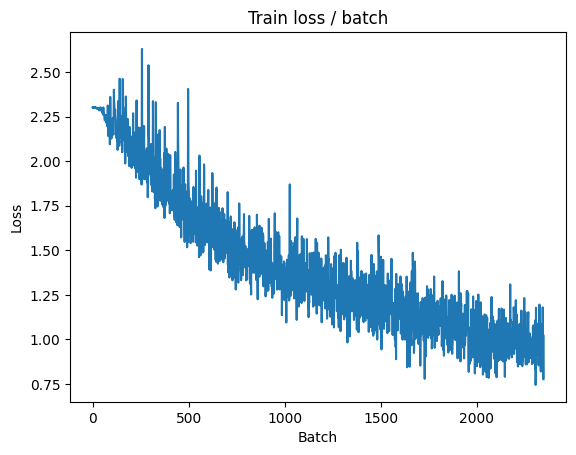

[TRAIN Batch 200/391]	Time 0.014s (0.019s)	Loss 0.8543 (0.8888)	Prec@1  68.0 ( 69.0)	Prec@5  98.4 ( 97.8)


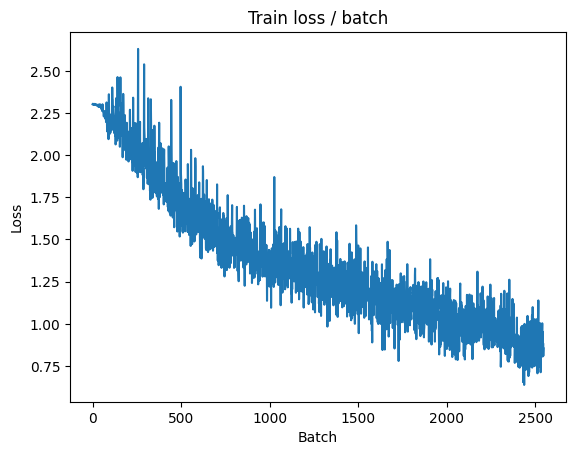


===============> Total time 8s	Avg loss 0.8821	Avg Prec@1 69.25 %	Avg Prec@5 97.63 %

[EVAL Batch 000/079]	Time 0.111s (0.111s)	Loss 0.9683 (0.9683)	Prec@1  70.3 ( 70.3)	Prec@5  96.1 ( 96.1)

===============> Total time 1s	Avg loss 1.0169	Avg Prec@1 65.08 %	Avg Prec@5 96.55 %



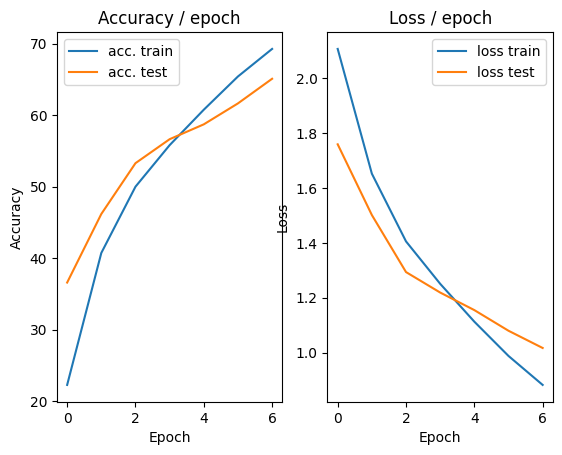

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.141s (0.141s)	Loss 0.8366 (0.8366)	Prec@1  67.2 ( 67.2)	Prec@5  98.4 ( 98.4)


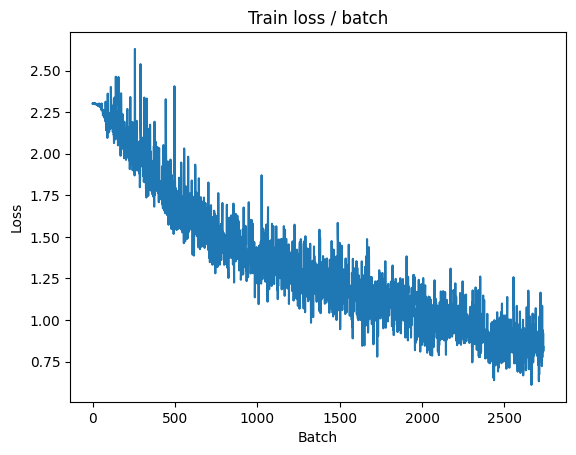

[TRAIN Batch 200/391]	Time 0.008s (0.019s)	Loss 0.8209 (0.7854)	Prec@1  71.9 ( 72.4)	Prec@5  98.4 ( 98.2)


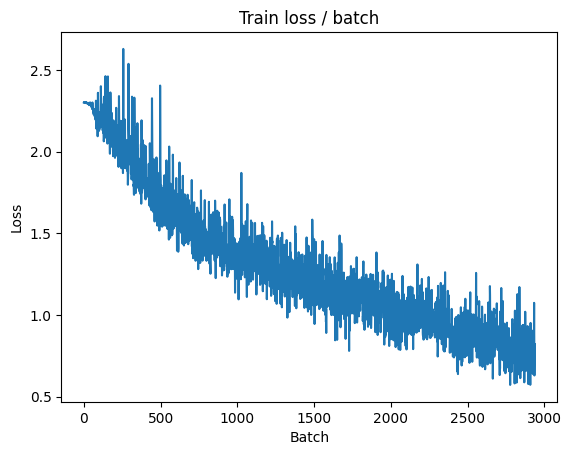


===============> Total time 7s	Avg loss 0.7795	Avg Prec@1 72.65 %	Avg Prec@5 98.26 %

[EVAL Batch 000/079]	Time 0.200s (0.200s)	Loss 0.9568 (0.9568)	Prec@1  69.5 ( 69.5)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.9705	Avg Prec@1 66.67 %	Avg Prec@5 96.67 %



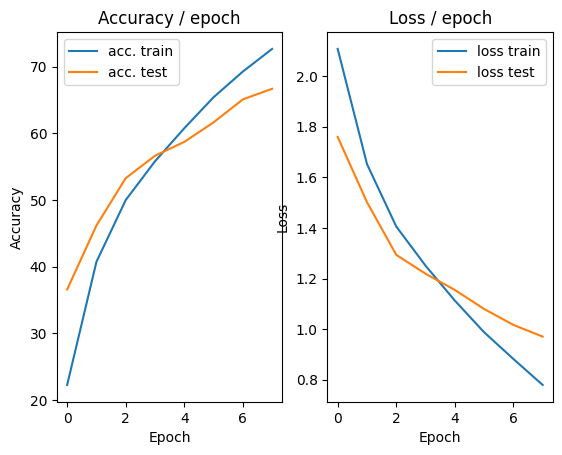

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.200s (0.200s)	Loss 0.6158 (0.6158)	Prec@1  75.8 ( 75.8)	Prec@5  99.2 ( 99.2)


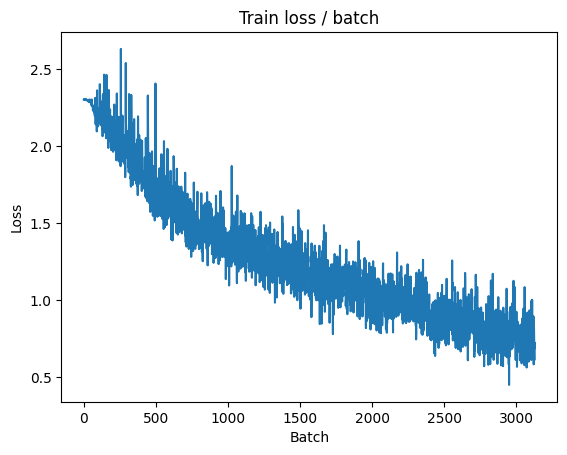

[TRAIN Batch 200/391]	Time 0.030s (0.020s)	Loss 0.5923 (0.6848)	Prec@1  76.6 ( 76.0)	Prec@5 100.0 ( 98.7)


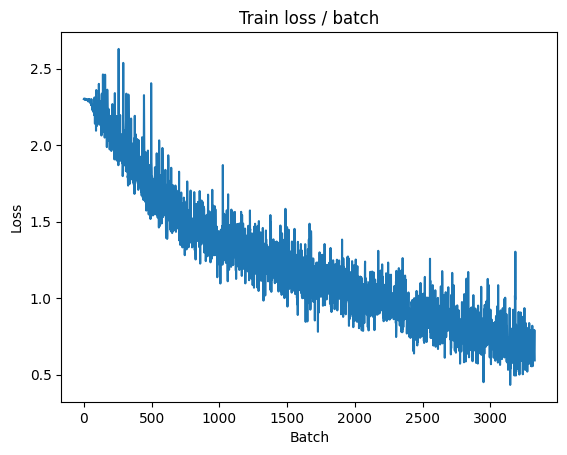


===============> Total time 7s	Avg loss 0.6829	Avg Prec@1 76.16 %	Avg Prec@5 98.64 %

[EVAL Batch 000/079]	Time 0.118s (0.118s)	Loss 1.1030 (1.1030)	Prec@1  62.5 ( 62.5)	Prec@5  94.5 ( 94.5)

===============> Total time 1s	Avg loss 0.9844	Avg Prec@1 66.99 %	Avg Prec@5 96.95 %



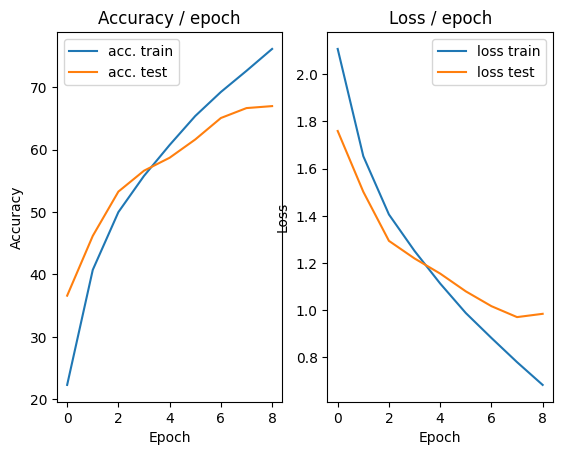

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.149s (0.149s)	Loss 0.6773 (0.6773)	Prec@1  72.7 ( 72.7)	Prec@5 100.0 (100.0)


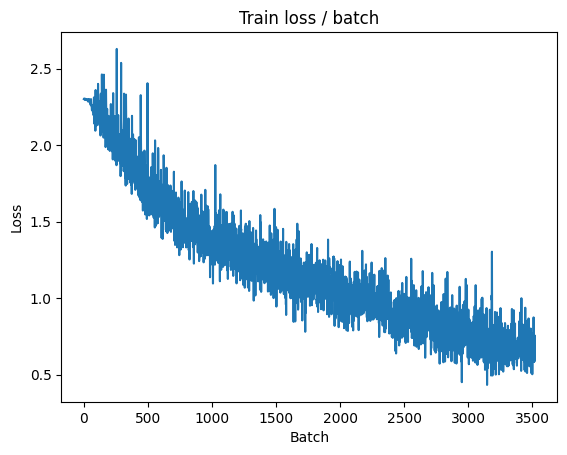

[TRAIN Batch 200/391]	Time 0.016s (0.024s)	Loss 0.5341 (0.5808)	Prec@1  78.9 ( 79.6)	Prec@5  97.7 ( 99.2)


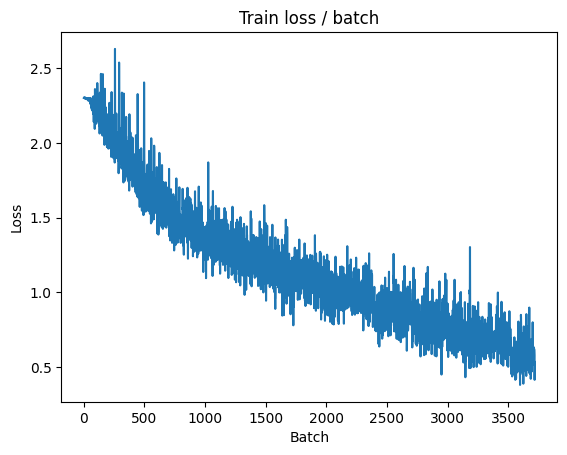


===============> Total time 8s	Avg loss 0.5860	Avg Prec@1 79.53 %	Avg Prec@5 99.09 %

[EVAL Batch 000/079]	Time 0.117s (0.117s)	Loss 1.0155 (1.0155)	Prec@1  64.1 ( 64.1)	Prec@5  98.4 ( 98.4)

===============> Total time 1s	Avg loss 1.0076	Avg Prec@1 67.11 %	Avg Prec@5 96.79 %



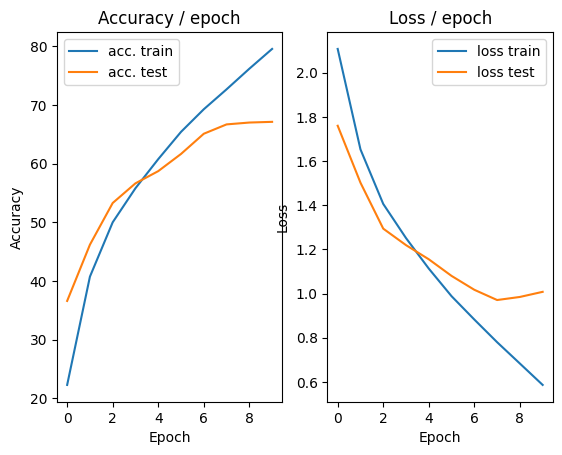

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.149s (0.149s)	Loss 0.5074 (0.5074)	Prec@1  78.9 ( 78.9)	Prec@5 100.0 (100.0)


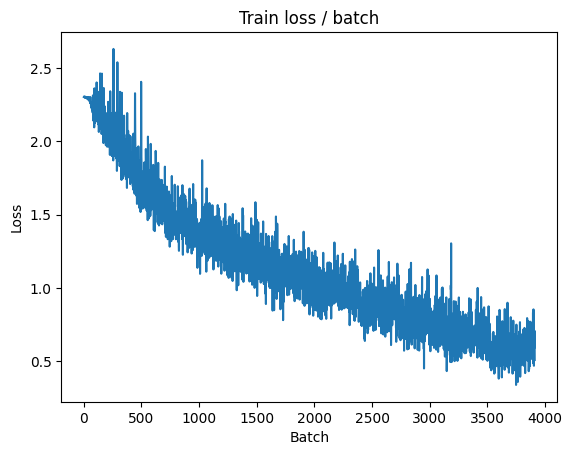

[TRAIN Batch 200/391]	Time 0.006s (0.019s)	Loss 0.6597 (0.4689)	Prec@1  75.8 ( 83.4)	Prec@5  99.2 ( 99.5)


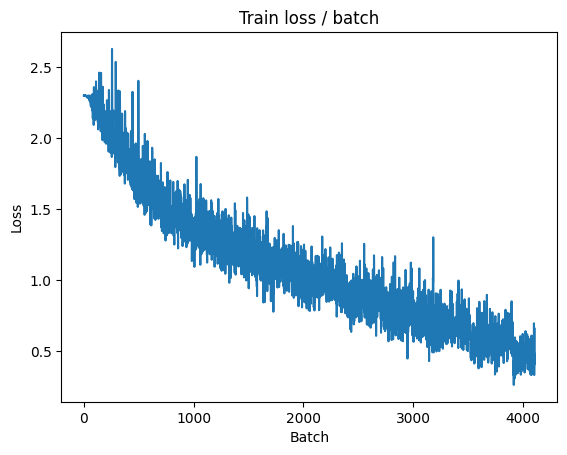


===============> Total time 8s	Avg loss 0.4874	Avg Prec@1 82.89 %	Avg Prec@5 99.41 %

[EVAL Batch 000/079]	Time 0.132s (0.132s)	Loss 1.1460 (1.1460)	Prec@1  68.0 ( 68.0)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.0421	Avg Prec@1 66.27 %	Avg Prec@5 96.94 %



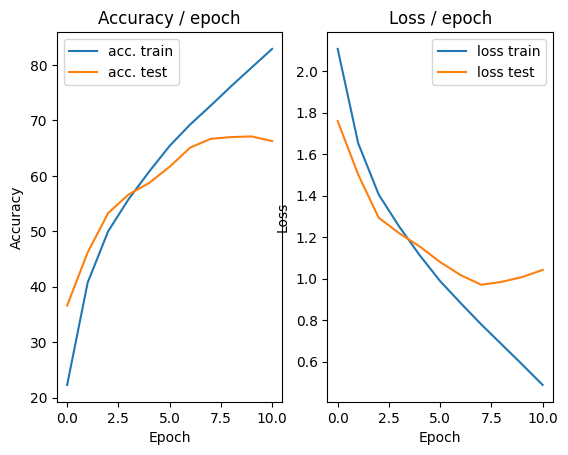

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.144s (0.144s)	Loss 0.5187 (0.5187)	Prec@1  85.2 ( 85.2)	Prec@5  98.4 ( 98.4)


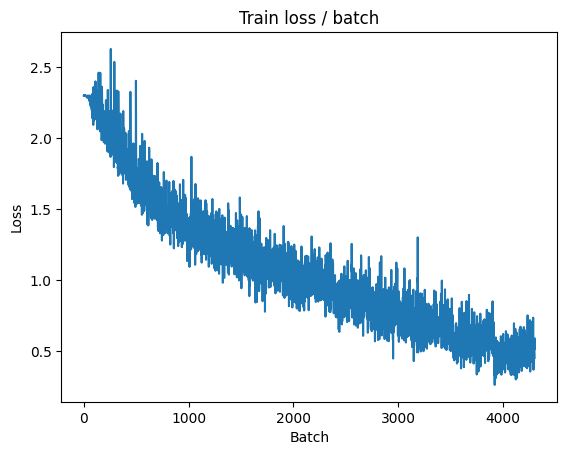

[TRAIN Batch 200/391]	Time 0.013s (0.019s)	Loss 0.3418 (0.3721)	Prec@1  90.6 ( 87.1)	Prec@5 100.0 ( 99.7)


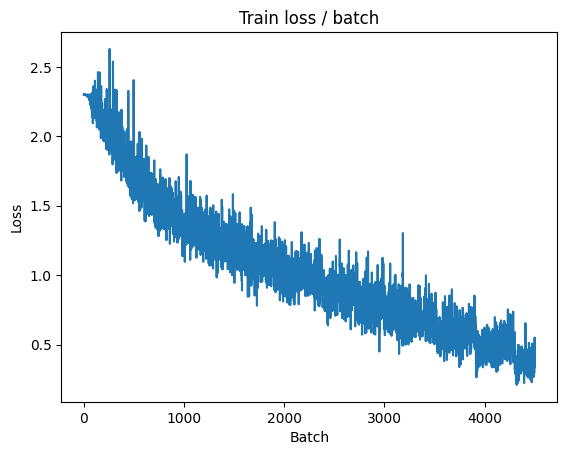


===============> Total time 7s	Avg loss 0.3995	Avg Prec@1 86.11 %	Avg Prec@5 99.64 %

[EVAL Batch 000/079]	Time 0.127s (0.127s)	Loss 1.2130 (1.2130)	Prec@1  66.4 ( 66.4)	Prec@5  95.3 ( 95.3)

===============> Total time 1s	Avg loss 1.0928	Avg Prec@1 67.41 %	Avg Prec@5 96.72 %



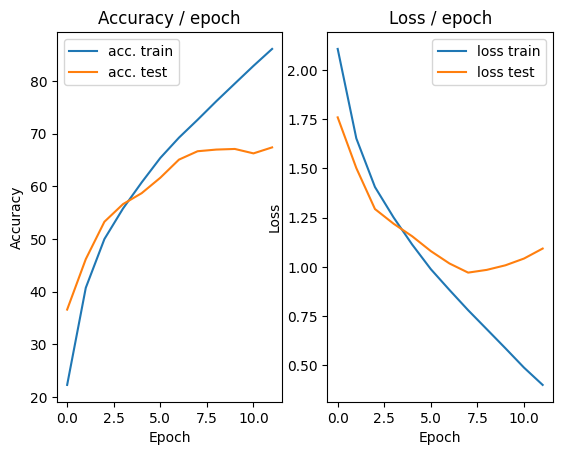

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.245s (0.245s)	Loss 0.2534 (0.2534)	Prec@1  93.0 ( 93.0)	Prec@5 100.0 (100.0)


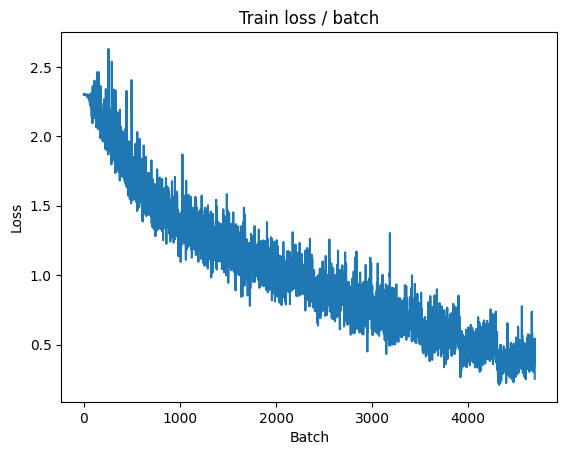

[TRAIN Batch 200/391]	Time 0.008s (0.022s)	Loss 0.3800 (0.2837)	Prec@1  88.3 ( 90.3)	Prec@5  99.2 ( 99.8)


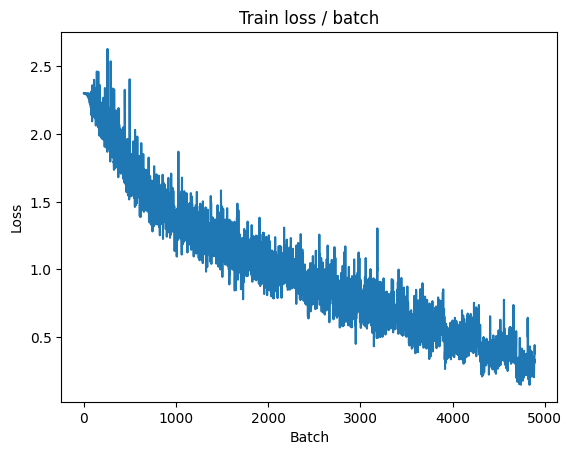


===============> Total time 7s	Avg loss 0.3101	Avg Prec@1 89.11 %	Avg Prec@5 99.82 %

[EVAL Batch 000/079]	Time 0.120s (0.120s)	Loss 1.2192 (1.2192)	Prec@1  66.4 ( 66.4)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.1017	Avg Prec@1 69.20 %	Avg Prec@5 97.28 %



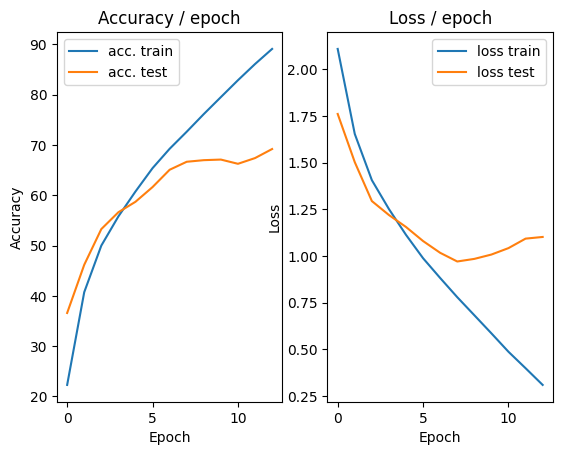

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.165s (0.165s)	Loss 0.1581 (0.1581)	Prec@1  93.8 ( 93.8)	Prec@5 100.0 (100.0)


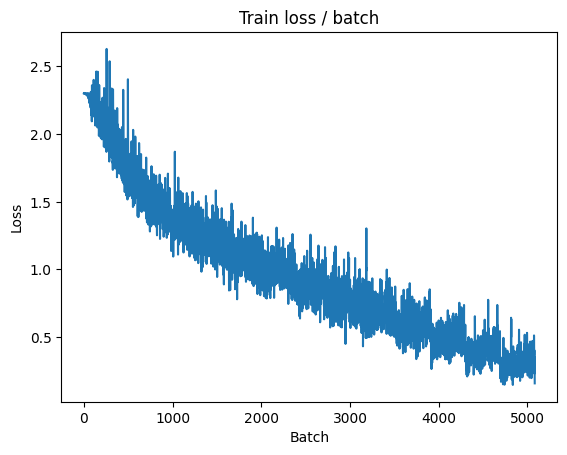

[TRAIN Batch 200/391]	Time 0.037s (0.021s)	Loss 0.1620 (0.2085)	Prec@1  94.5 ( 93.1)	Prec@5 100.0 ( 99.9)


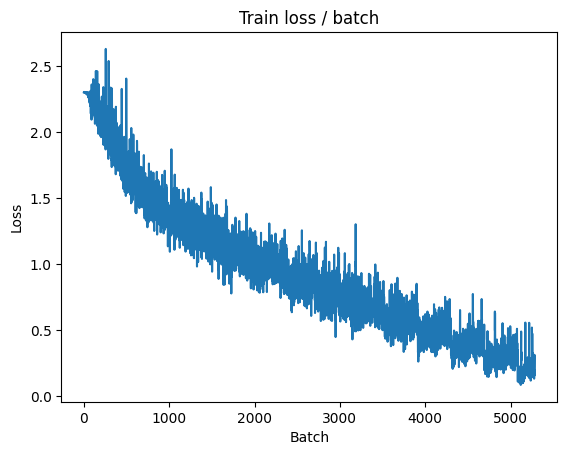


===============> Total time 8s	Avg loss 0.2318	Avg Prec@1 92.12 %	Avg Prec@5 99.92 %

[EVAL Batch 000/079]	Time 0.116s (0.116s)	Loss 1.2851 (1.2851)	Prec@1  71.9 ( 71.9)	Prec@5  94.5 ( 94.5)

===============> Total time 1s	Avg loss 1.2006	Avg Prec@1 68.30 %	Avg Prec@5 96.98 %



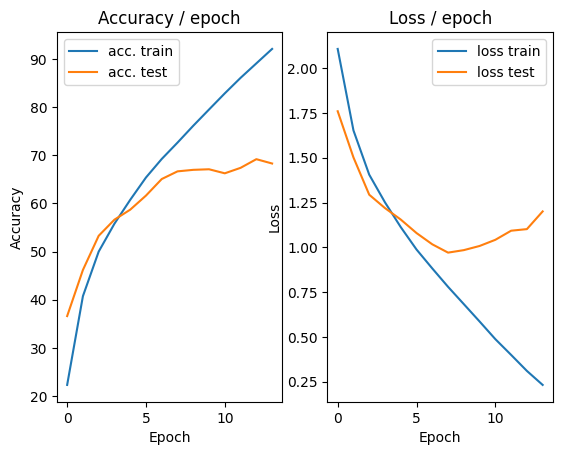

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.142s (0.142s)	Loss 0.1096 (0.1096)	Prec@1  97.7 ( 97.7)	Prec@5 100.0 (100.0)


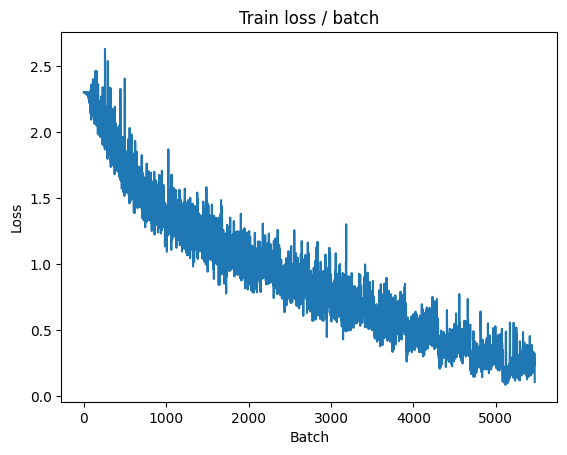

[TRAIN Batch 200/391]	Time 0.022s (0.019s)	Loss 0.1784 (0.1370)	Prec@1  92.2 ( 95.5)	Prec@5 100.0 (100.0)


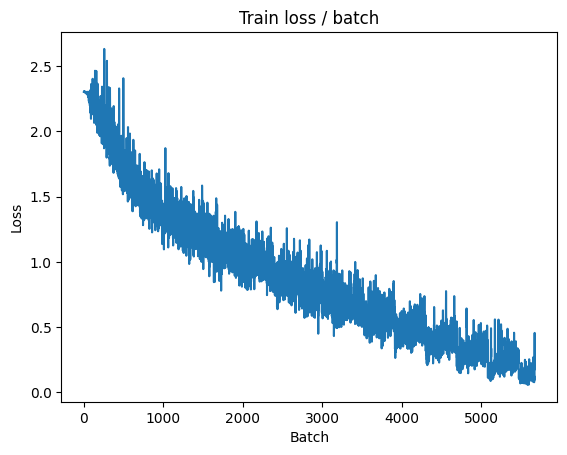


===============> Total time 7s	Avg loss 0.1672	Avg Prec@1 94.39 %	Avg Prec@5 99.96 %

[EVAL Batch 000/079]	Time 0.132s (0.132s)	Loss 1.5353 (1.5353)	Prec@1  68.8 ( 68.8)	Prec@5  94.5 ( 94.5)

===============> Total time 1s	Avg loss 1.4855	Avg Prec@1 67.31 %	Avg Prec@5 96.69 %



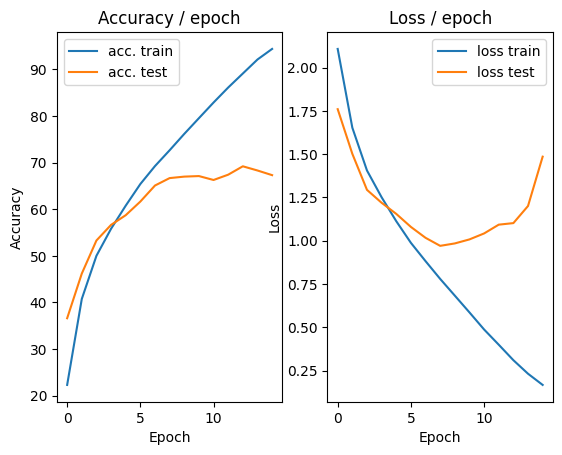

=== EPOCH 16 =====

[TRAIN Batch 000/391]	Time 0.156s (0.156s)	Loss 0.1193 (0.1193)	Prec@1  96.1 ( 96.1)	Prec@5 100.0 (100.0)


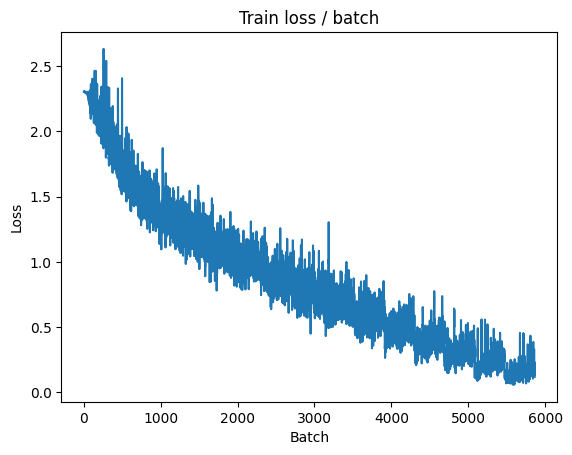

[TRAIN Batch 200/391]	Time 0.016s (0.020s)	Loss 0.1494 (0.0917)	Prec@1  92.2 ( 97.2)	Prec@5 100.0 (100.0)


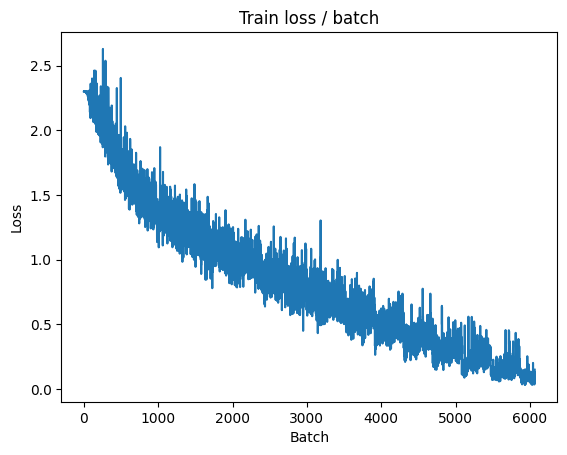


===============> Total time 7s	Avg loss 0.1193	Avg Prec@1 96.14 %	Avg Prec@5 99.99 %

[EVAL Batch 000/079]	Time 0.118s (0.118s)	Loss 1.7442 (1.7442)	Prec@1  68.0 ( 68.0)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.4499	Avg Prec@1 69.66 %	Avg Prec@5 96.89 %



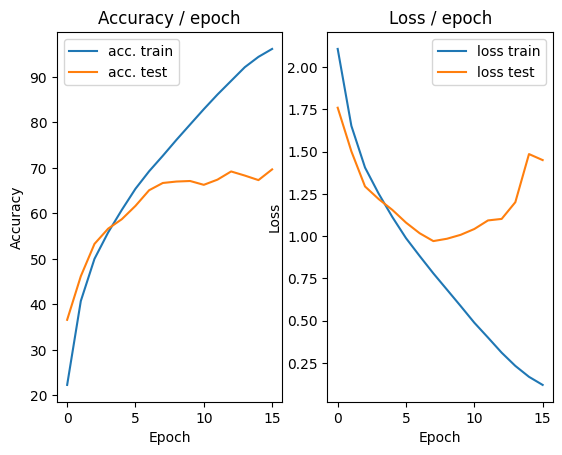

=== EPOCH 17 =====

[TRAIN Batch 000/391]	Time 0.205s (0.205s)	Loss 0.0669 (0.0669)	Prec@1  99.2 ( 99.2)	Prec@5 100.0 (100.0)


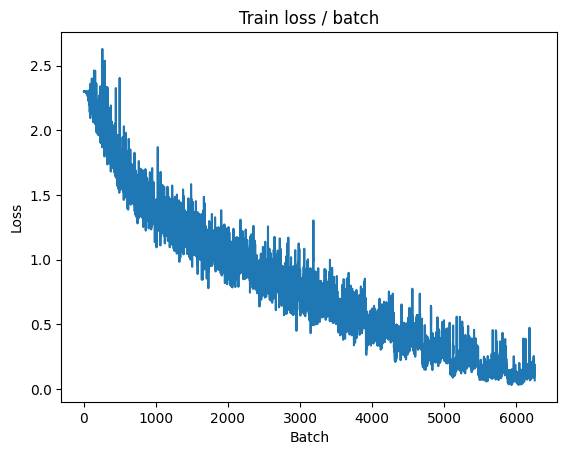

[TRAIN Batch 200/391]	Time 0.018s (0.026s)	Loss 0.0495 (0.0652)	Prec@1  99.2 ( 98.0)	Prec@5 100.0 (100.0)


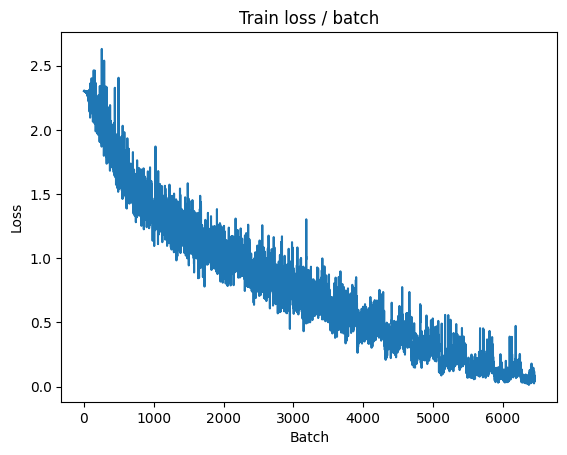


===============> Total time 8s	Avg loss 0.0905	Avg Prec@1 97.13 %	Avg Prec@5 99.99 %

[EVAL Batch 000/079]	Time 0.124s (0.124s)	Loss 1.5838 (1.5838)	Prec@1  68.8 ( 68.8)	Prec@5  96.9 ( 96.9)

===============> Total time 1s	Avg loss 1.4790	Avg Prec@1 69.27 %	Avg Prec@5 96.92 %



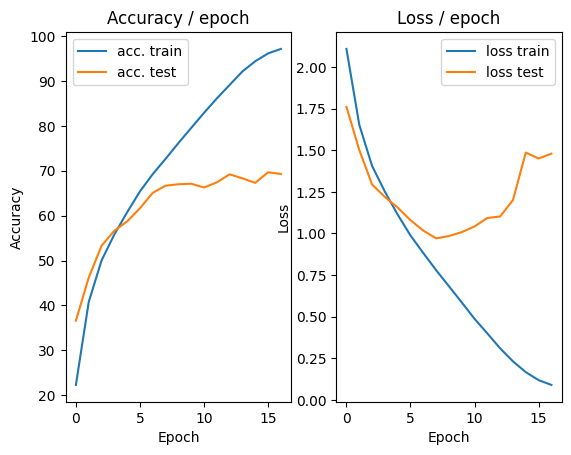

=== EPOCH 18 =====

[TRAIN Batch 000/391]	Time 0.161s (0.161s)	Loss 0.1266 (0.1266)	Prec@1  96.1 ( 96.1)	Prec@5 100.0 (100.0)


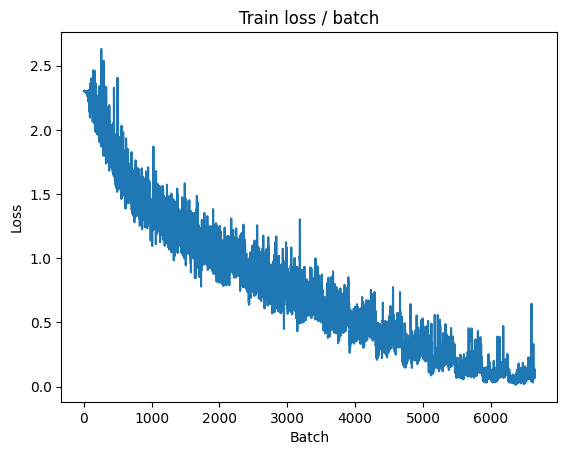

[TRAIN Batch 200/391]	Time 0.032s (0.021s)	Loss 0.0872 (0.0492)	Prec@1  96.1 ( 98.6)	Prec@5 100.0 (100.0)


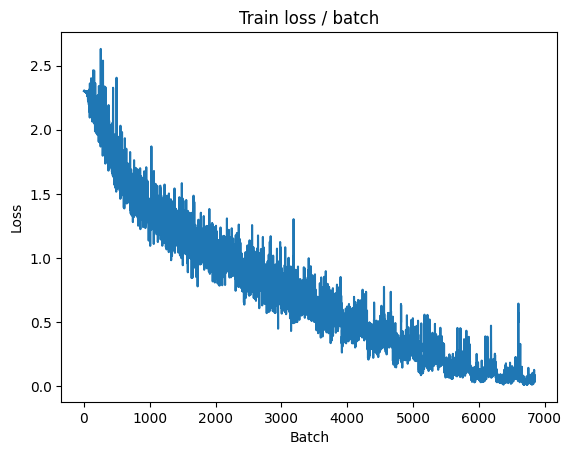


===============> Total time 8s	Avg loss 0.0613	Avg Prec@1 98.09 %	Avg Prec@5 100.00 %

[EVAL Batch 000/079]	Time 0.125s (0.125s)	Loss 1.6594 (1.6594)	Prec@1  68.0 ( 68.0)	Prec@5  96.1 ( 96.1)

===============> Total time 1s	Avg loss 1.6371	Avg Prec@1 69.46 %	Avg Prec@5 97.03 %



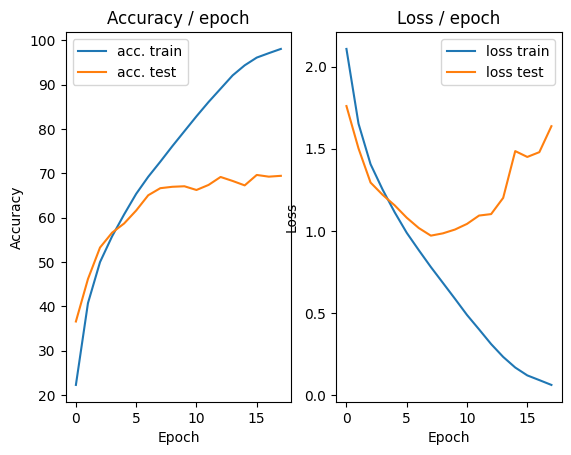

=== EPOCH 19 =====

[TRAIN Batch 000/391]	Time 0.179s (0.179s)	Loss 0.0442 (0.0442)	Prec@1  99.2 ( 99.2)	Prec@5 100.0 (100.0)


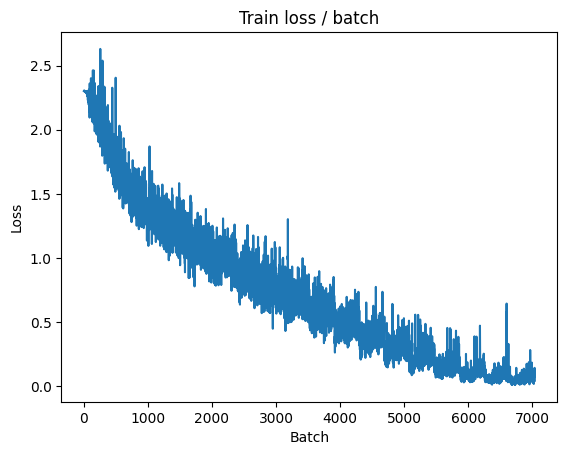

[TRAIN Batch 200/391]	Time 0.012s (0.019s)	Loss 0.0252 (0.0276)	Prec@1  99.2 ( 99.3)	Prec@5 100.0 (100.0)


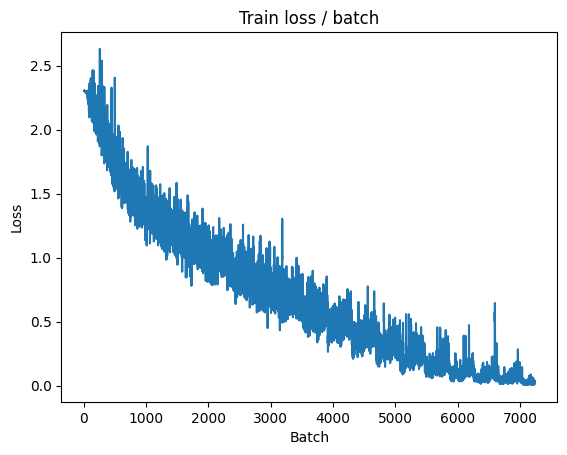


===============> Total time 7s	Avg loss 0.0295	Avg Prec@1 99.16 %	Avg Prec@5 100.00 %

[EVAL Batch 000/079]	Time 0.180s (0.180s)	Loss 1.7070 (1.7070)	Prec@1  74.2 ( 74.2)	Prec@5  97.7 ( 97.7)

===============> Total time 1s	Avg loss 1.8888	Avg Prec@1 70.28 %	Avg Prec@5 97.18 %



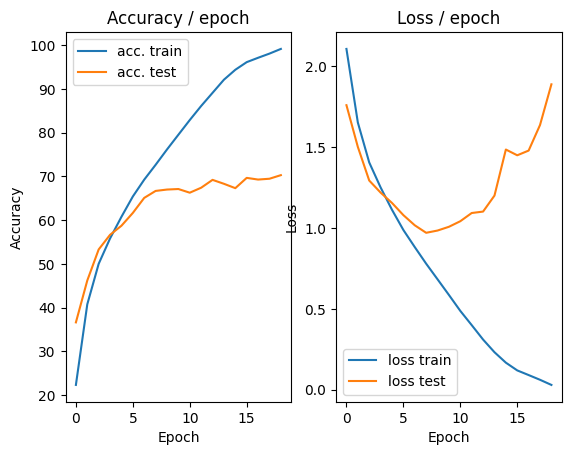

=== EPOCH 20 =====

[TRAIN Batch 000/391]	Time 0.154s (0.154s)	Loss 0.0183 (0.0183)	Prec@1  99.2 ( 99.2)	Prec@5 100.0 (100.0)


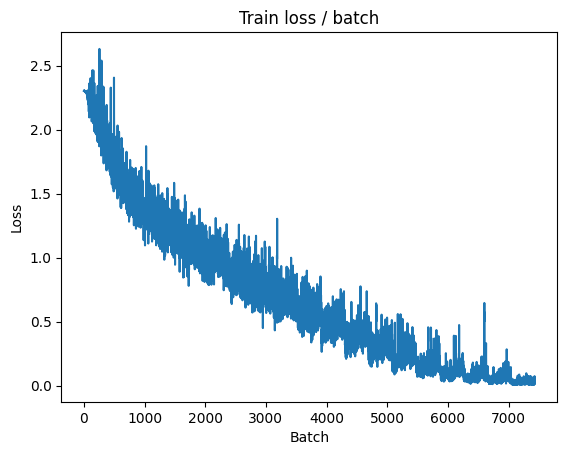

[TRAIN Batch 200/391]	Time 0.023s (0.019s)	Loss 0.0138 (0.0140)	Prec@1  99.2 ( 99.7)	Prec@5 100.0 (100.0)


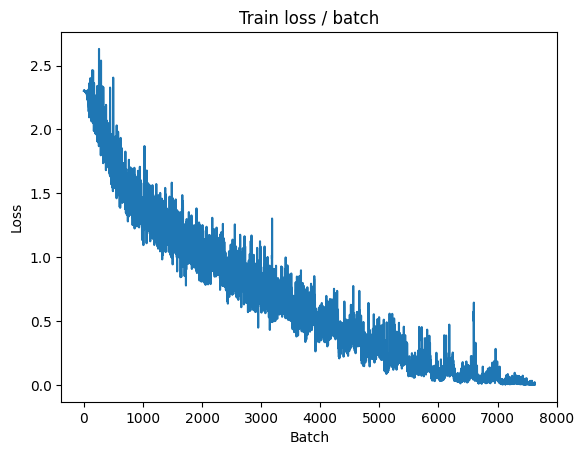


===============> Total time 7s	Avg loss 0.0351	Avg Prec@1 98.97 %	Avg Prec@5 100.00 %

[EVAL Batch 000/079]	Time 0.128s (0.128s)	Loss 1.6473 (1.6473)	Prec@1  68.0 ( 68.0)	Prec@5  96.1 ( 96.1)

===============> Total time 1s	Avg loss 1.6328	Avg Prec@1 68.81 %	Avg Prec@5 96.89 %



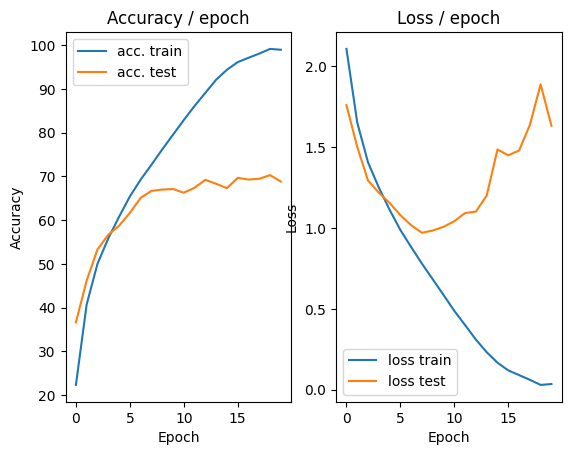

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.603s (0.603s)	Loss 2.3037 (2.3037)	Prec@1  12.5 ( 12.5)	Prec@5  56.2 ( 56.2)


<Figure size 640x480 with 0 Axes>

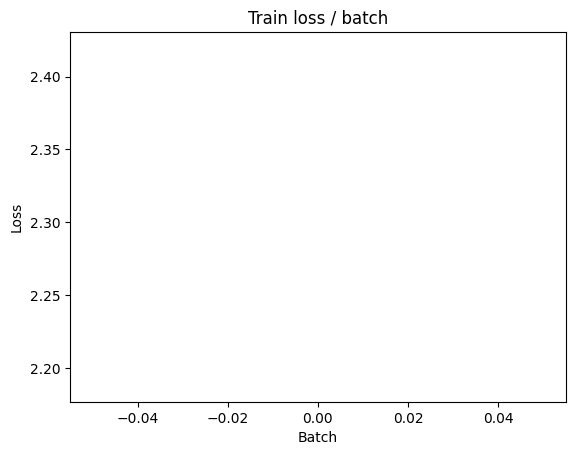

[TRAIN Batch 200/391]	Time 0.055s (0.043s)	Loss 1.6136 (1.9854)	Prec@1  43.0 ( 27.3)	Prec@5  89.1 ( 77.6)


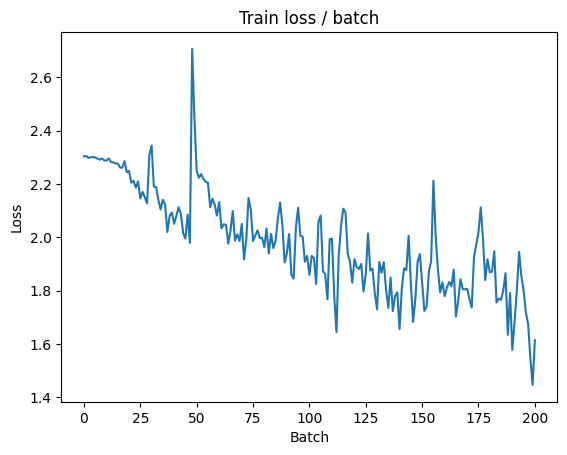


===============> Total time 16s	Avg loss 1.8143	Avg Prec@1 33.71 %	Avg Prec@5 83.34 %

[EVAL Batch 000/079]	Time 0.160s (0.160s)	Loss 1.4754 (1.4754)	Prec@1  47.7 ( 47.7)	Prec@5  91.4 ( 91.4)

===============> Total time 2s	Avg loss 1.4896	Avg Prec@1 44.64 %	Avg Prec@5 91.57 %



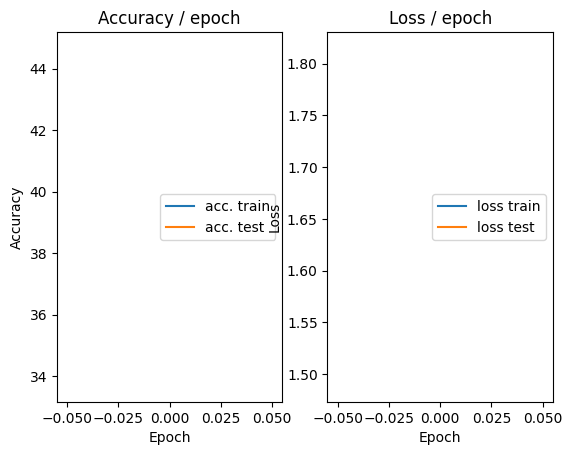

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.200s (0.200s)	Loss 1.5586 (1.5586)	Prec@1  39.1 ( 39.1)	Prec@5  88.3 ( 88.3)


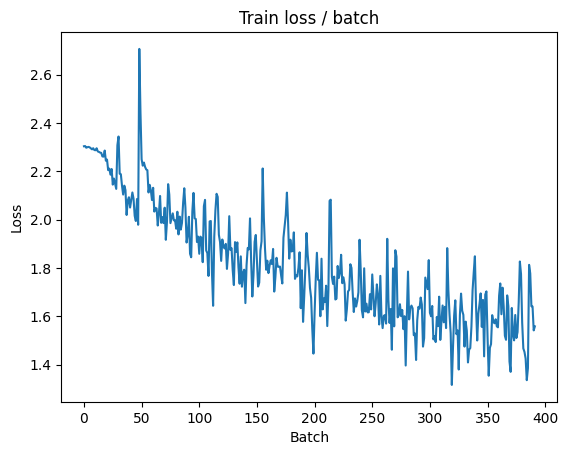

[TRAIN Batch 200/391]	Time 0.012s (0.040s)	Loss 1.3536 (1.4490)	Prec@1  50.8 ( 47.6)	Prec@5  95.3 ( 92.6)


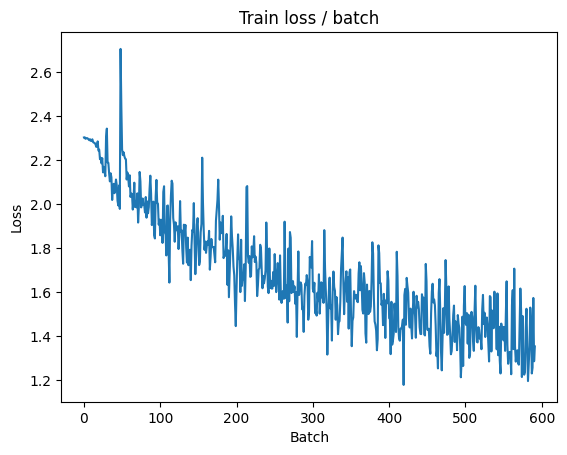


===============> Total time 15s	Avg loss 1.3895	Avg Prec@1 50.00 %	Avg Prec@5 93.40 %

[EVAL Batch 000/079]	Time 0.142s (0.142s)	Loss 1.3431 (1.3431)	Prec@1  50.0 ( 50.0)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 1.3256	Avg Prec@1 52.63 %	Avg Prec@5 94.08 %



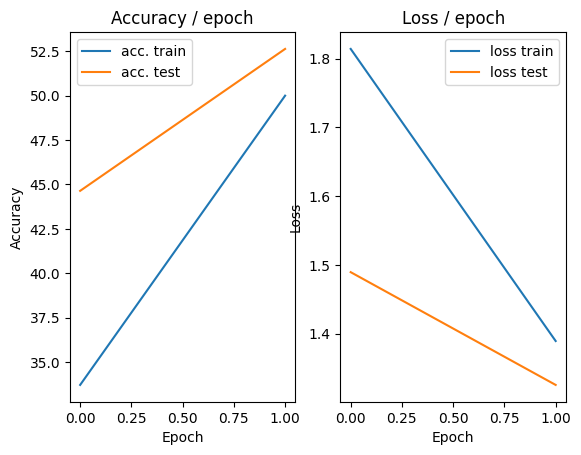

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.223s (0.223s)	Loss 1.5129 (1.5129)	Prec@1  47.7 ( 47.7)	Prec@5  92.2 ( 92.2)


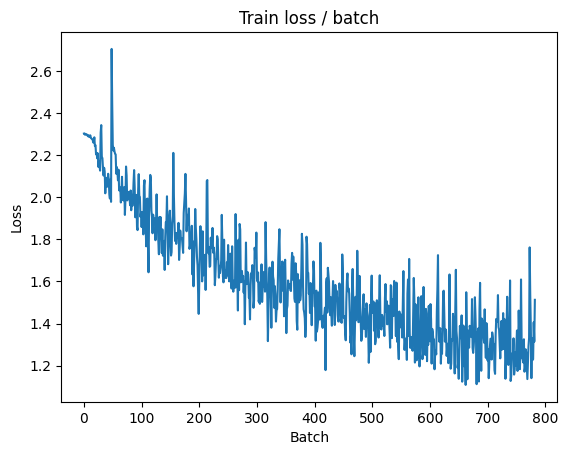

[TRAIN Batch 200/391]	Time 0.057s (0.043s)	Loss 1.0551 (1.2197)	Prec@1  64.8 ( 57.0)	Prec@5  94.5 ( 95.0)


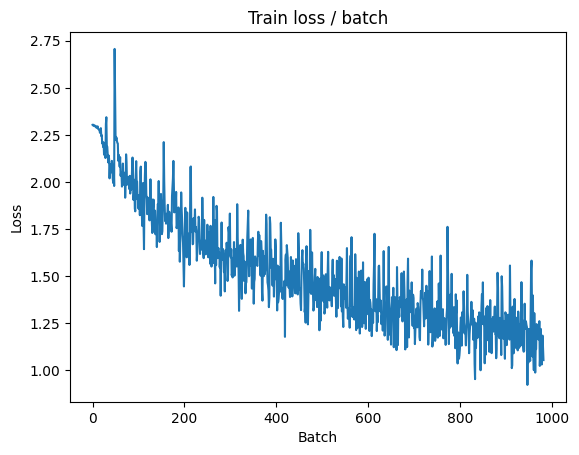


===============> Total time 15s	Avg loss 1.1788	Avg Prec@1 58.43 %	Avg Prec@5 95.35 %

[EVAL Batch 000/079]	Time 0.174s (0.174s)	Loss 1.0260 (1.0260)	Prec@1  64.8 ( 64.8)	Prec@5  97.7 ( 97.7)

===============> Total time 3s	Avg loss 1.0864	Avg Prec@1 61.64 %	Avg Prec@5 96.02 %



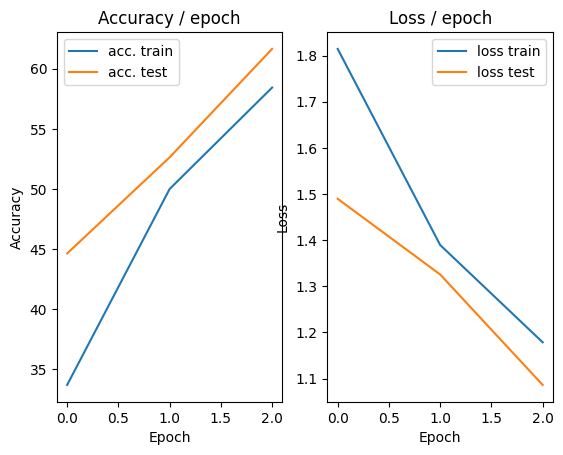

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.201s (0.201s)	Loss 1.1948 (1.1948)	Prec@1  56.2 ( 56.2)	Prec@5  96.1 ( 96.1)


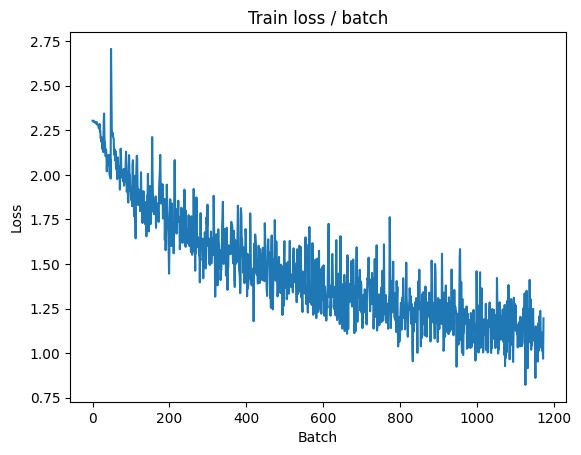

[TRAIN Batch 200/391]	Time 0.056s (0.037s)	Loss 1.3459 (1.0655)	Prec@1  57.0 ( 62.5)	Prec@5  93.8 ( 96.2)


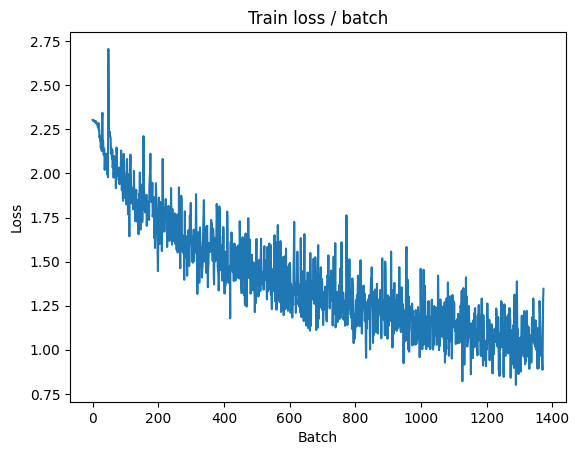


===============> Total time 15s	Avg loss 1.0295	Avg Prec@1 63.78 %	Avg Prec@5 96.49 %

[EVAL Batch 000/079]	Time 0.158s (0.158s)	Loss 1.0136 (1.0136)	Prec@1  68.0 ( 68.0)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.9886	Avg Prec@1 66.15 %	Avg Prec@5 96.82 %



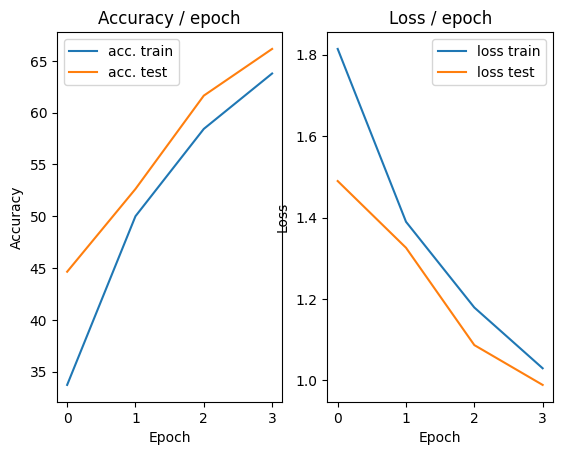

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.210s (0.210s)	Loss 1.0161 (1.0161)	Prec@1  65.6 ( 65.6)	Prec@5  97.7 ( 97.7)


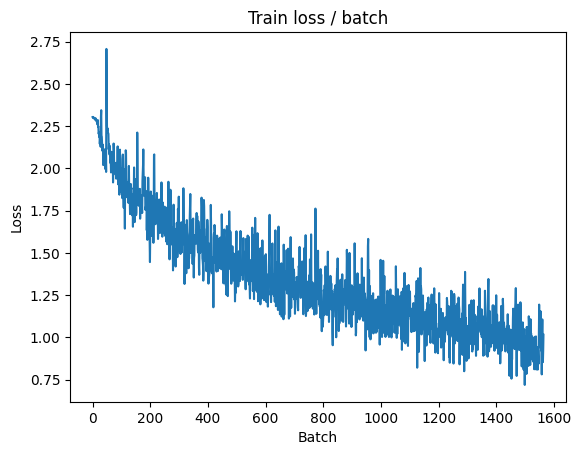

[TRAIN Batch 200/391]	Time 0.048s (0.044s)	Loss 0.8580 (0.9348)	Prec@1  71.1 ( 67.3)	Prec@5 100.0 ( 97.2)


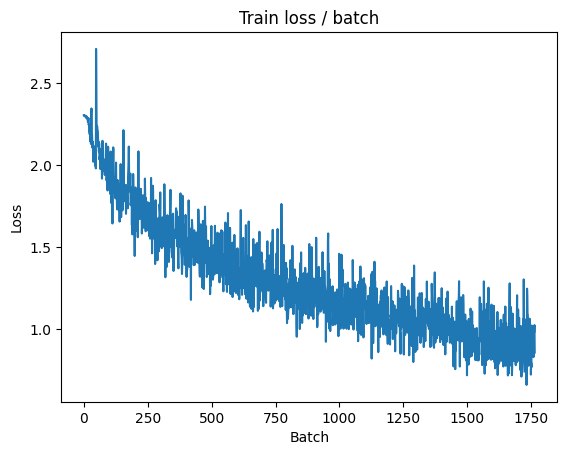


===============> Total time 15s	Avg loss 0.9162	Avg Prec@1 68.06 %	Avg Prec@5 97.21 %

[EVAL Batch 000/079]	Time 0.151s (0.151s)	Loss 1.0584 (1.0584)	Prec@1  66.4 ( 66.4)	Prec@5  93.8 ( 93.8)

===============> Total time 2s	Avg loss 1.0627	Avg Prec@1 64.68 %	Avg Prec@5 95.15 %



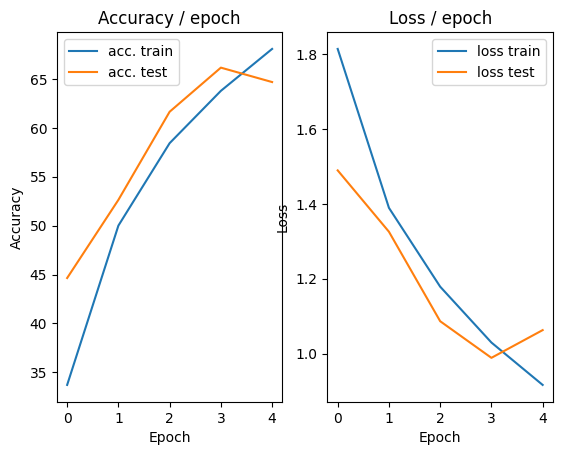

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.214s (0.214s)	Loss 1.0676 (1.0676)	Prec@1  65.6 ( 65.6)	Prec@5  93.8 ( 93.8)


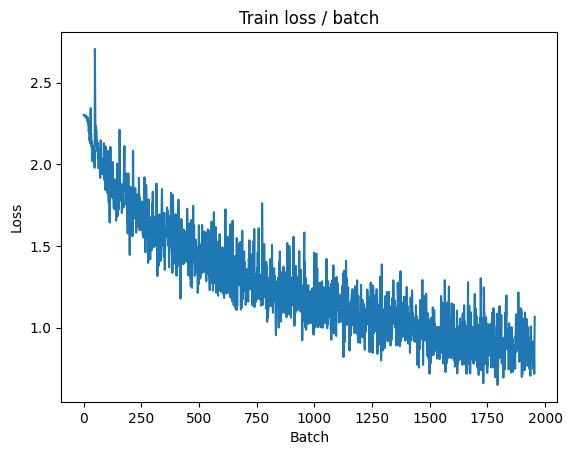

[TRAIN Batch 200/391]	Time 0.049s (0.043s)	Loss 0.8235 (0.8417)	Prec@1  75.0 ( 70.9)	Prec@5  99.2 ( 97.7)


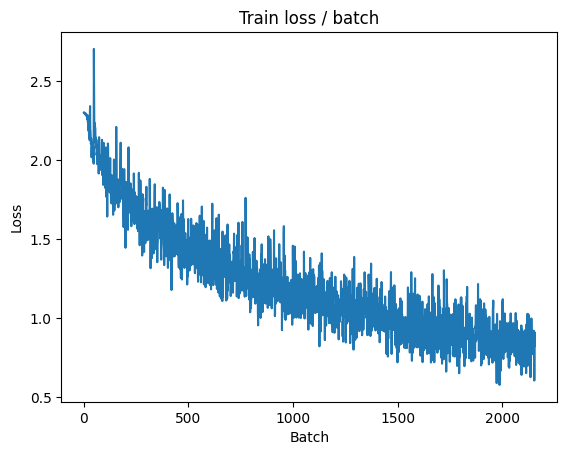


===============> Total time 16s	Avg loss 0.8311	Avg Prec@1 71.26 %	Avg Prec@5 97.72 %

[EVAL Batch 000/079]	Time 0.191s (0.191s)	Loss 0.8471 (0.8471)	Prec@1  70.3 ( 70.3)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.8351	Avg Prec@1 71.38 %	Avg Prec@5 97.33 %



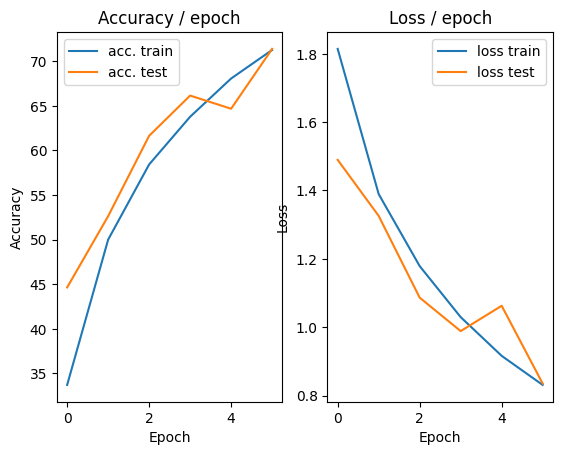

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.227s (0.227s)	Loss 0.7407 (0.7407)	Prec@1  75.0 ( 75.0)	Prec@5  99.2 ( 99.2)


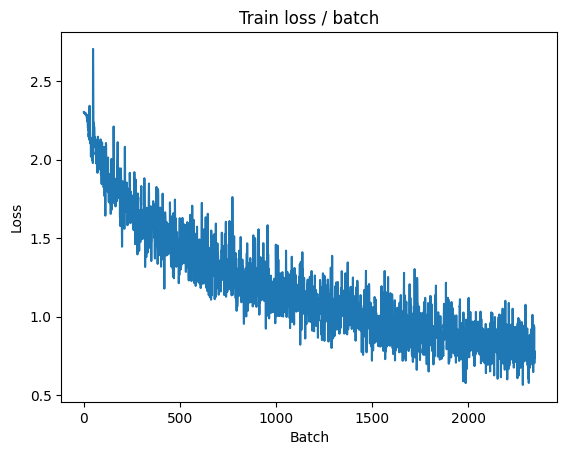

[TRAIN Batch 200/391]	Time 0.011s (0.037s)	Loss 0.6685 (0.7732)	Prec@1  76.6 ( 72.9)	Prec@5 100.0 ( 98.1)


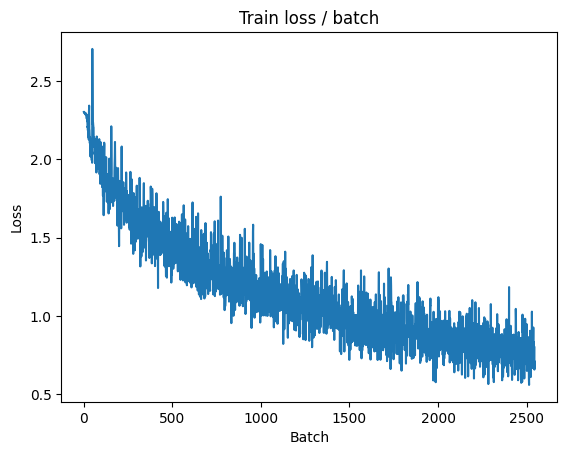


===============> Total time 15s	Avg loss 0.7686	Avg Prec@1 73.22 %	Avg Prec@5 98.05 %

[EVAL Batch 000/079]	Time 0.148s (0.148s)	Loss 0.7161 (0.7161)	Prec@1  74.2 ( 74.2)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.7778	Avg Prec@1 72.70 %	Avg Prec@5 97.86 %



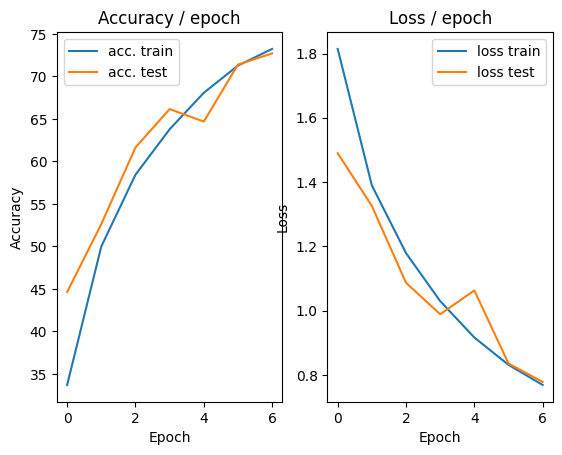

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.230s (0.230s)	Loss 0.7079 (0.7079)	Prec@1  72.7 ( 72.7)	Prec@5  98.4 ( 98.4)


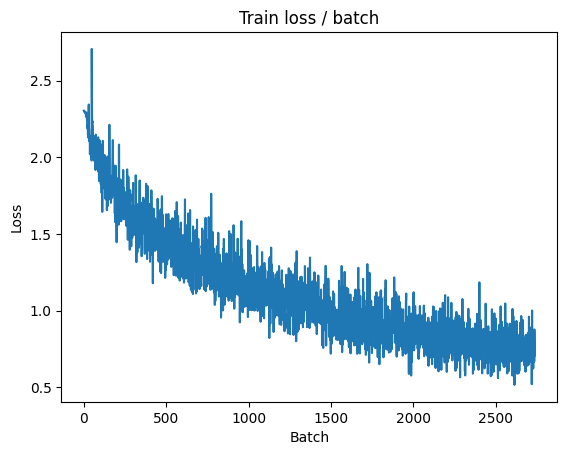

[TRAIN Batch 200/391]	Time 0.100s (0.044s)	Loss 0.6171 (0.7167)	Prec@1  80.5 ( 75.2)	Prec@5  99.2 ( 98.3)


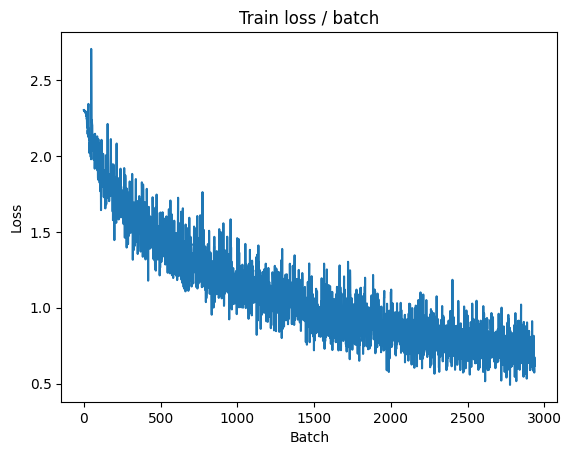


===============> Total time 15s	Avg loss 0.7107	Avg Prec@1 75.33 %	Avg Prec@5 98.42 %

[EVAL Batch 000/079]	Time 0.150s (0.150s)	Loss 0.7546 (0.7546)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.8260	Avg Prec@1 72.38 %	Avg Prec@5 97.70 %



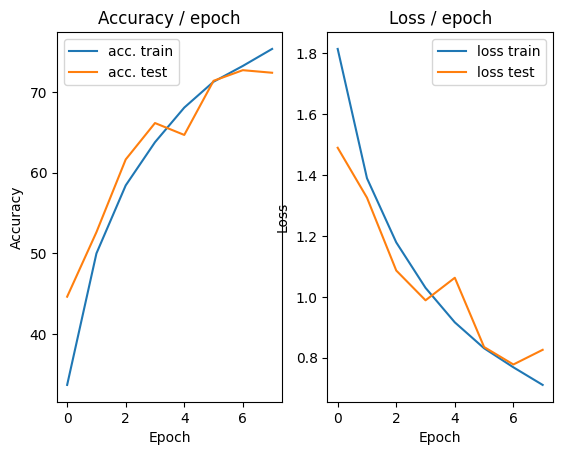

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.293s (0.293s)	Loss 0.6626 (0.6626)	Prec@1  71.9 ( 71.9)	Prec@5  98.4 ( 98.4)


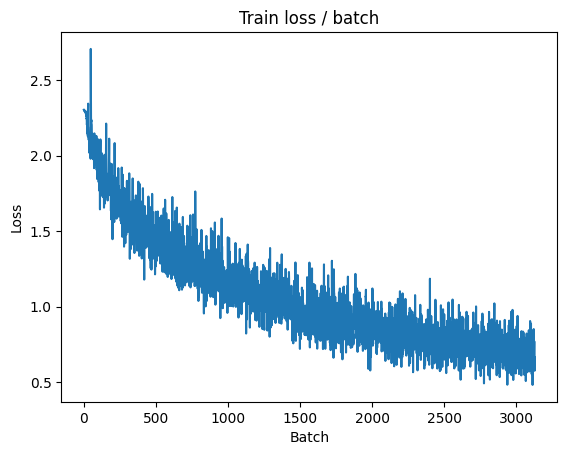

[TRAIN Batch 200/391]	Time 0.050s (0.039s)	Loss 0.7522 (0.6653)	Prec@1  70.3 ( 76.9)	Prec@5  97.7 ( 98.6)


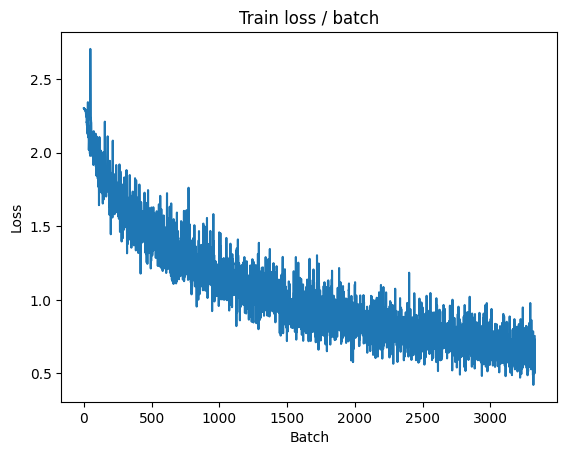


===============> Total time 16s	Avg loss 0.6675	Avg Prec@1 76.63 %	Avg Prec@5 98.60 %

[EVAL Batch 000/079]	Time 0.174s (0.174s)	Loss 0.8253 (0.8253)	Prec@1  74.2 ( 74.2)	Prec@5  96.1 ( 96.1)

===============> Total time 2s	Avg loss 0.7682	Avg Prec@1 74.41 %	Avg Prec@5 97.78 %



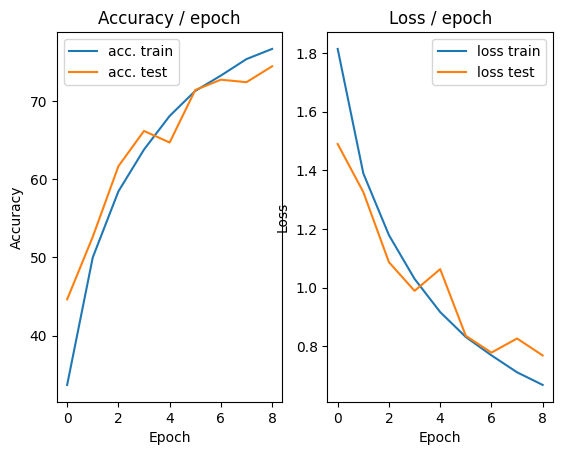

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.274s (0.274s)	Loss 0.7354 (0.7354)	Prec@1  74.2 ( 74.2)	Prec@5  99.2 ( 99.2)


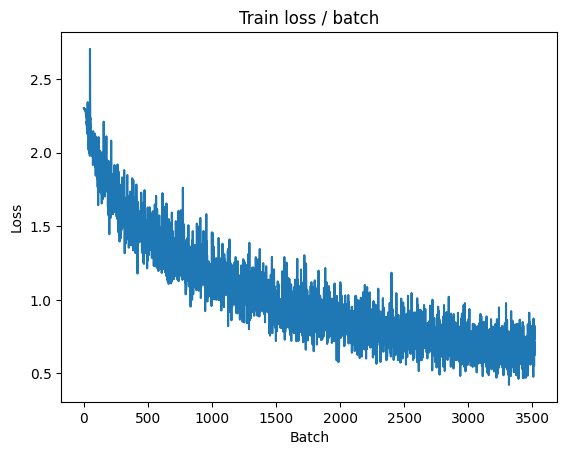

[TRAIN Batch 200/391]	Time 0.011s (0.041s)	Loss 0.6428 (0.6203)	Prec@1  76.6 ( 78.2)	Prec@5  99.2 ( 98.9)


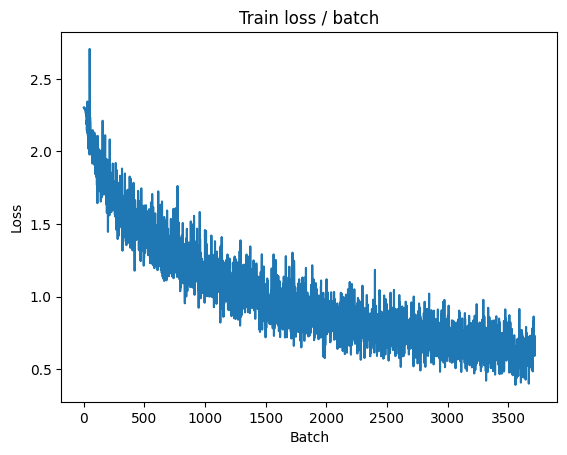


===============> Total time 15s	Avg loss 0.6269	Avg Prec@1 78.03 %	Avg Prec@5 98.85 %

[EVAL Batch 000/079]	Time 0.158s (0.158s)	Loss 0.6847 (0.6847)	Prec@1  78.1 ( 78.1)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7042	Avg Prec@1 76.14 %	Avg Prec@5 98.45 %



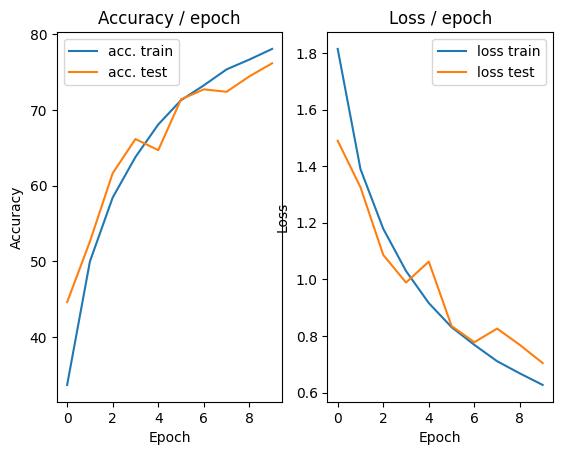

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.229s (0.229s)	Loss 0.5124 (0.5124)	Prec@1  82.0 ( 82.0)	Prec@5  99.2 ( 99.2)


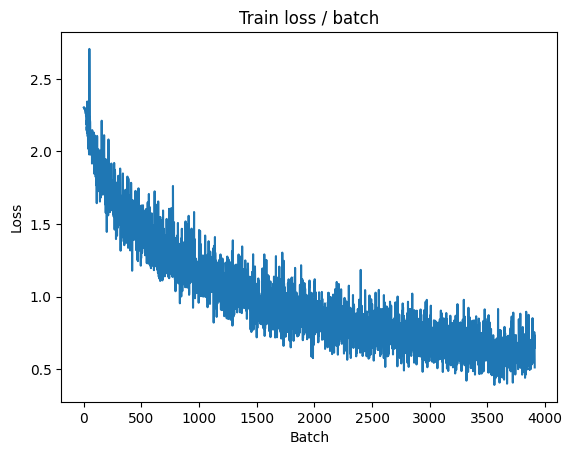

[TRAIN Batch 200/391]	Time 0.062s (0.044s)	Loss 0.6645 (0.5851)	Prec@1  74.2 ( 79.6)	Prec@5  97.7 ( 98.9)


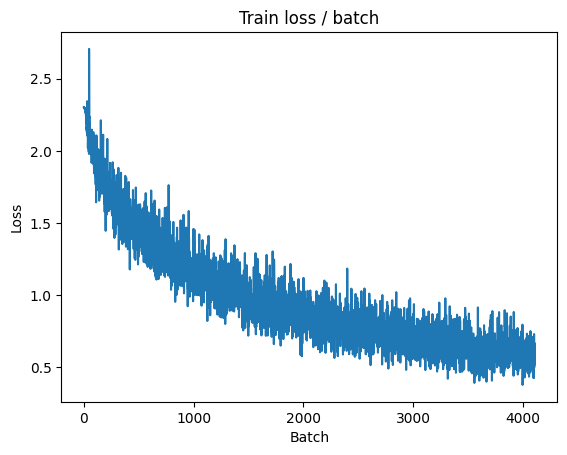


===============> Total time 16s	Avg loss 0.5918	Avg Prec@1 79.44 %	Avg Prec@5 98.96 %

[EVAL Batch 000/079]	Time 0.259s (0.259s)	Loss 0.6915 (0.6915)	Prec@1  78.1 ( 78.1)	Prec@5  98.4 ( 98.4)

===============> Total time 3s	Avg loss 0.6710	Avg Prec@1 77.10 %	Avg Prec@5 98.50 %



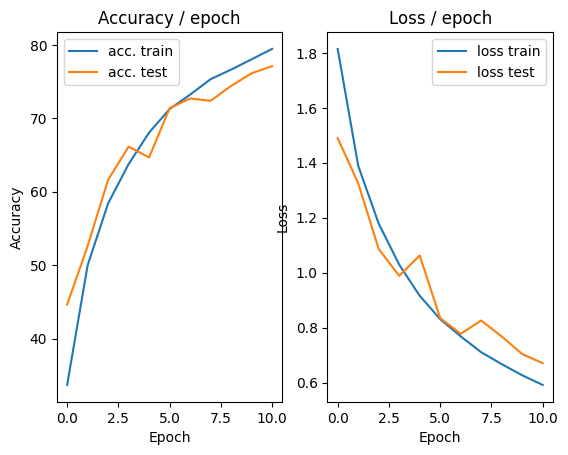

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.243s (0.243s)	Loss 0.4208 (0.4208)	Prec@1  85.9 ( 85.9)	Prec@5 100.0 (100.0)


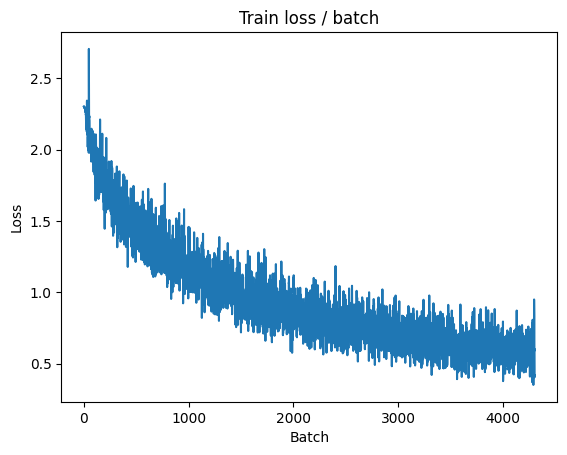

[TRAIN Batch 200/391]	Time 0.064s (0.039s)	Loss 0.4660 (0.5595)	Prec@1  82.0 ( 80.6)	Prec@5 100.0 ( 99.1)


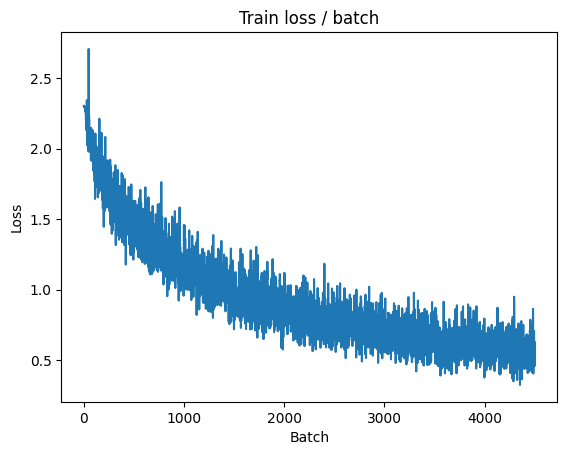


===============> Total time 16s	Avg loss 0.5569	Avg Prec@1 80.69 %	Avg Prec@5 99.01 %

[EVAL Batch 000/079]	Time 0.154s (0.154s)	Loss 0.6979 (0.6979)	Prec@1  76.6 ( 76.6)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.6745	Avg Prec@1 77.12 %	Avg Prec@5 98.42 %



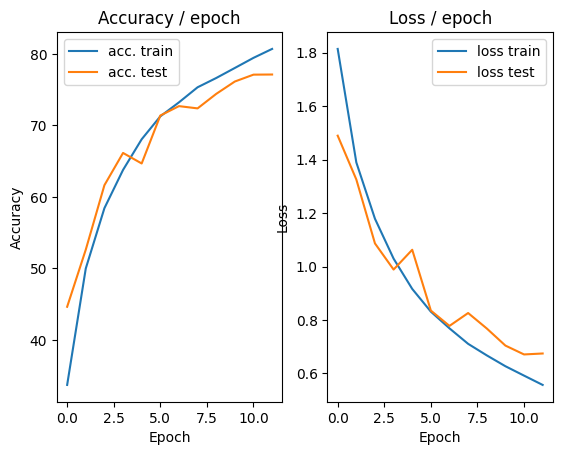

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.237s (0.237s)	Loss 0.4945 (0.4945)	Prec@1  83.6 ( 83.6)	Prec@5  99.2 ( 99.2)


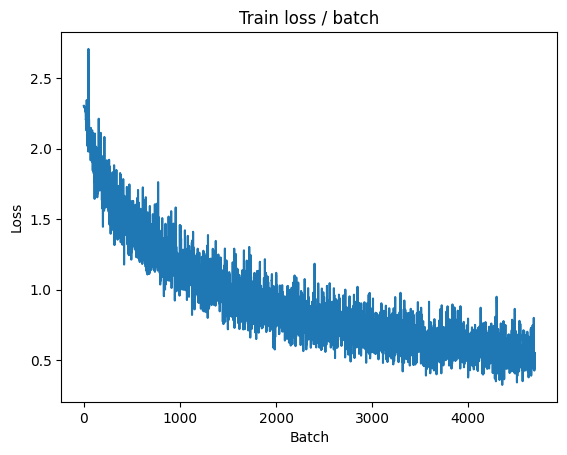

[TRAIN Batch 200/391]	Time 0.070s (0.046s)	Loss 0.6787 (0.5334)	Prec@1  77.3 ( 81.5)	Prec@5  98.4 ( 99.2)


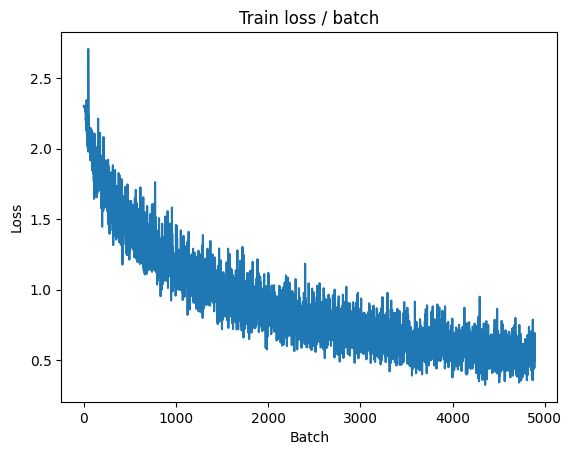


===============> Total time 16s	Avg loss 0.5349	Avg Prec@1 81.39 %	Avg Prec@5 99.15 %

[EVAL Batch 000/079]	Time 0.170s (0.170s)	Loss 0.6807 (0.6807)	Prec@1  78.9 ( 78.9)	Prec@5  97.7 ( 97.7)

===============> Total time 3s	Avg loss 0.6545	Avg Prec@1 78.10 %	Avg Prec@5 98.58 %



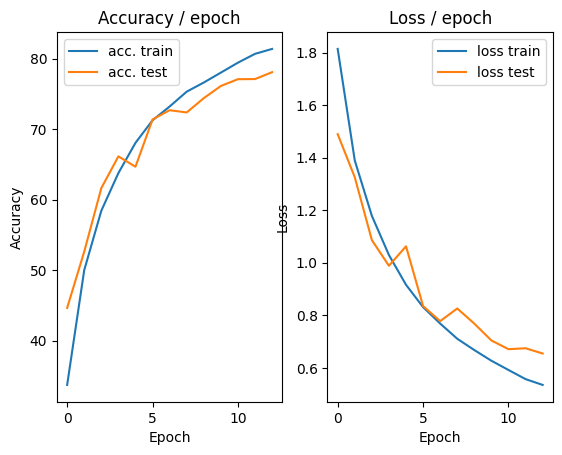

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.363s (0.363s)	Loss 0.5450 (0.5450)	Prec@1  82.0 ( 82.0)	Prec@5  99.2 ( 99.2)


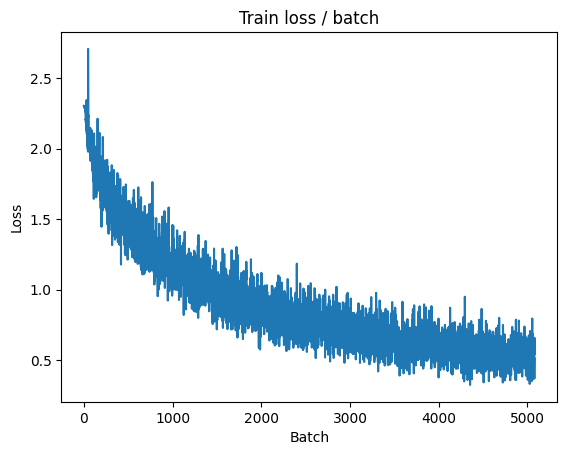

[TRAIN Batch 200/391]	Time 0.010s (0.039s)	Loss 0.3329 (0.5051)	Prec@1  88.3 ( 82.3)	Prec@5 100.0 ( 99.3)


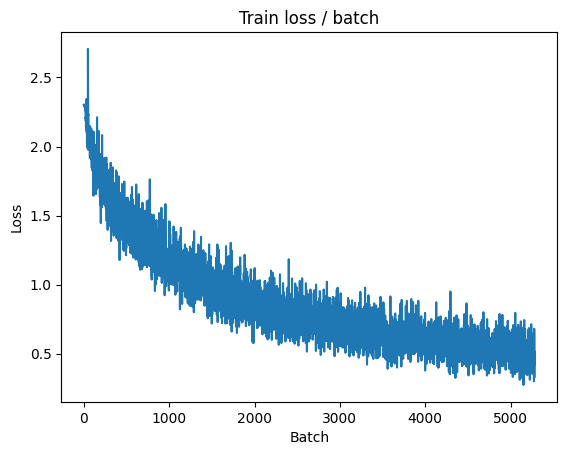


===============> Total time 16s	Avg loss 0.5076	Avg Prec@1 82.21 %	Avg Prec@5 99.26 %

[EVAL Batch 000/079]	Time 0.173s (0.173s)	Loss 0.6620 (0.6620)	Prec@1  80.5 ( 80.5)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.6345	Avg Prec@1 78.73 %	Avg Prec@5 98.50 %



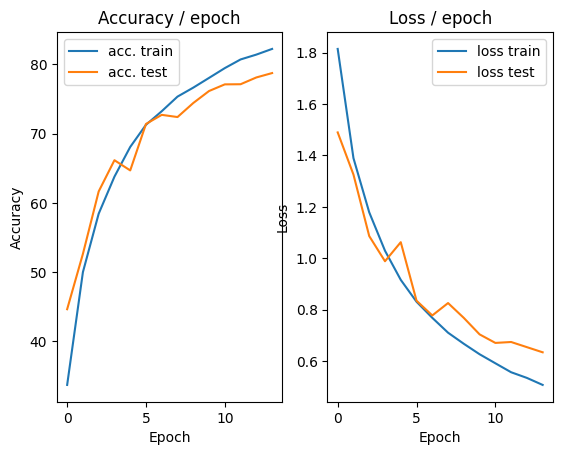

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.218s (0.218s)	Loss 0.6181 (0.6181)	Prec@1  74.2 ( 74.2)	Prec@5  98.4 ( 98.4)


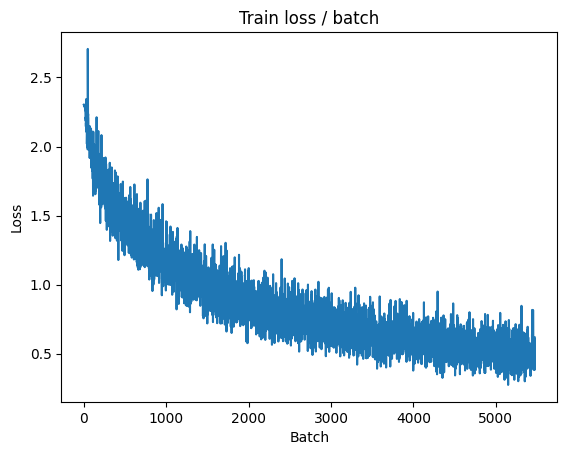

[TRAIN Batch 200/391]	Time 0.033s (0.044s)	Loss 0.5441 (0.4746)	Prec@1  82.8 ( 83.4)	Prec@5 100.0 ( 99.3)


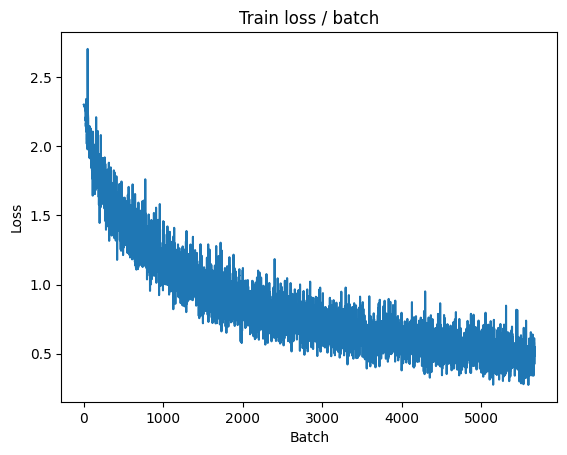


===============> Total time 16s	Avg loss 0.4811	Avg Prec@1 83.15 %	Avg Prec@5 99.32 %

[EVAL Batch 000/079]	Time 0.151s (0.151s)	Loss 0.7395 (0.7395)	Prec@1  78.1 ( 78.1)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.6254	Avg Prec@1 79.50 %	Avg Prec@5 98.76 %



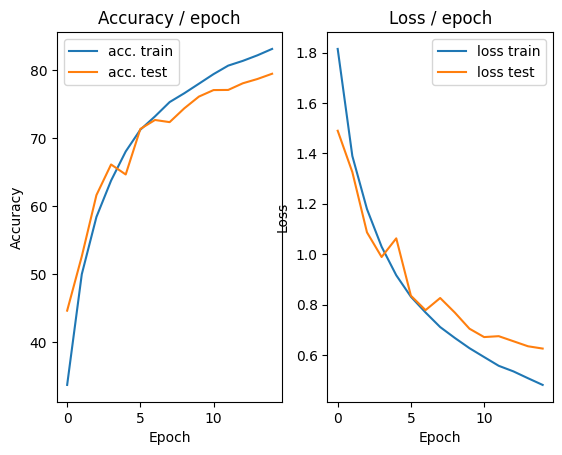

=== EPOCH 16 =====

[TRAIN Batch 000/391]	Time 0.311s (0.311s)	Loss 0.3620 (0.3620)	Prec@1  86.7 ( 86.7)	Prec@5 100.0 (100.0)


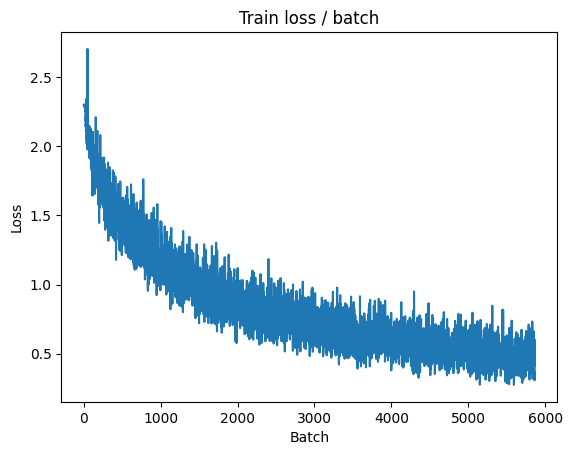

[TRAIN Batch 200/391]	Time 0.013s (0.044s)	Loss 0.3632 (0.4515)	Prec@1  89.1 ( 84.3)	Prec@5 100.0 ( 99.5)


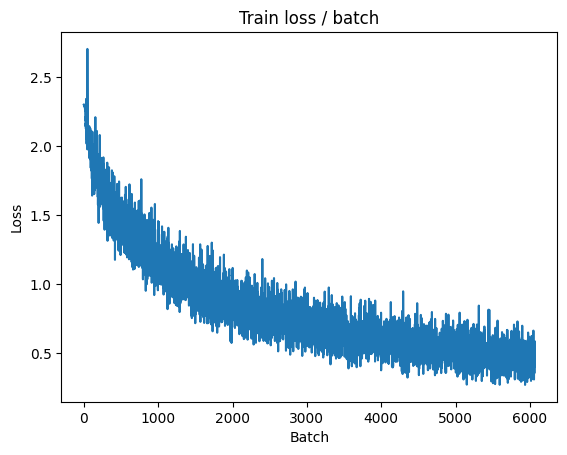


===============> Total time 17s	Avg loss 0.4564	Avg Prec@1 84.06 %	Avg Prec@5 99.46 %

[EVAL Batch 000/079]	Time 0.159s (0.159s)	Loss 0.8804 (0.8804)	Prec@1  74.2 ( 74.2)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.7146	Avg Prec@1 77.26 %	Avg Prec@5 98.61 %



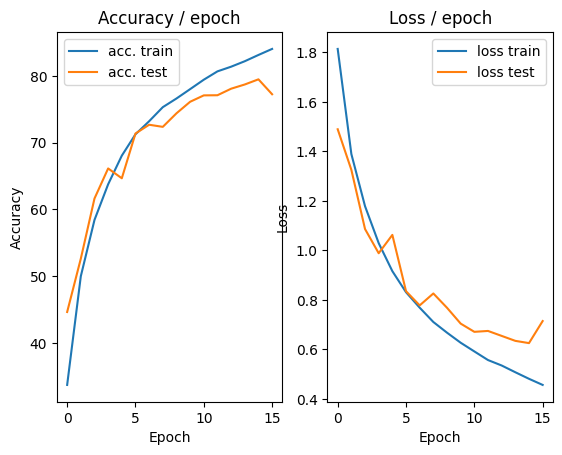

=== EPOCH 17 =====

[TRAIN Batch 000/391]	Time 0.229s (0.229s)	Loss 0.4092 (0.4092)	Prec@1  87.5 ( 87.5)	Prec@5  99.2 ( 99.2)


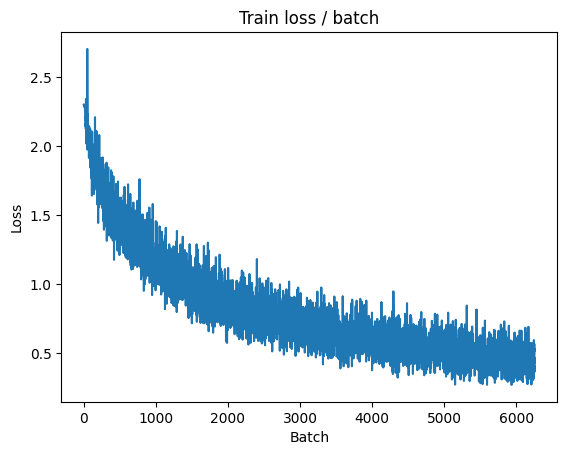

[TRAIN Batch 200/391]	Time 0.013s (0.040s)	Loss 0.4114 (0.4351)	Prec@1  85.9 ( 85.0)	Prec@5 100.0 ( 99.5)


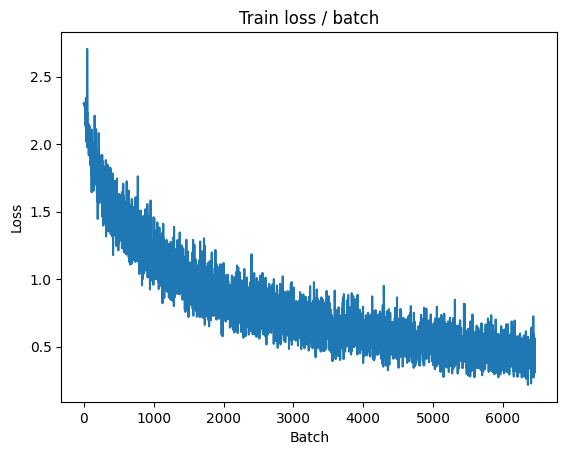


===============> Total time 16s	Avg loss 0.4394	Avg Prec@1 84.76 %	Avg Prec@5 99.46 %

[EVAL Batch 000/079]	Time 0.169s (0.169s)	Loss 0.7027 (0.7027)	Prec@1  77.3 ( 77.3)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.6908	Avg Prec@1 77.94 %	Avg Prec@5 98.67 %



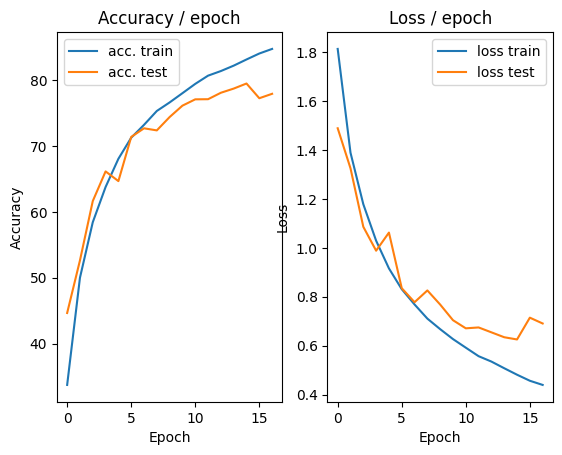

=== EPOCH 18 =====

[TRAIN Batch 000/391]	Time 0.256s (0.256s)	Loss 0.4127 (0.4127)	Prec@1  88.3 ( 88.3)	Prec@5  98.4 ( 98.4)


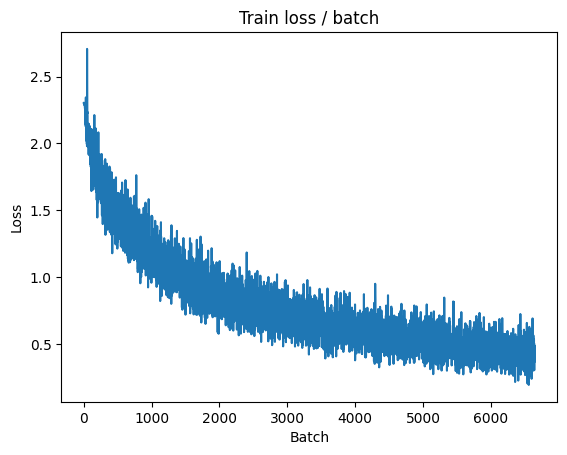

[TRAIN Batch 200/391]	Time 0.012s (0.043s)	Loss 0.2870 (0.4061)	Prec@1  89.1 ( 85.9)	Prec@5 100.0 ( 99.5)


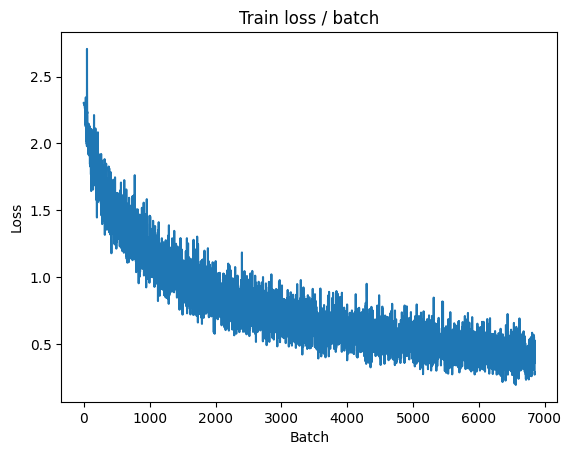


===============> Total time 15s	Avg loss 0.4190	Avg Prec@1 85.37 %	Avg Prec@5 99.53 %

[EVAL Batch 000/079]	Time 0.257s (0.257s)	Loss 0.7115 (0.7115)	Prec@1  82.0 ( 82.0)	Prec@5  98.4 ( 98.4)

===============> Total time 3s	Avg loss 0.6226	Avg Prec@1 79.41 %	Avg Prec@5 98.55 %



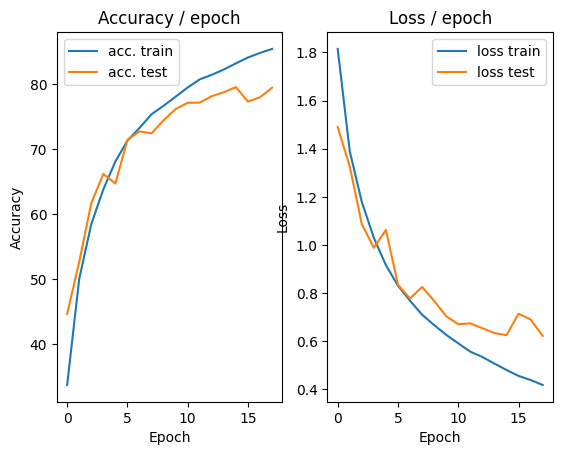

=== EPOCH 19 =====

[TRAIN Batch 000/391]	Time 0.229s (0.229s)	Loss 0.3480 (0.3480)	Prec@1  85.9 ( 85.9)	Prec@5  99.2 ( 99.2)


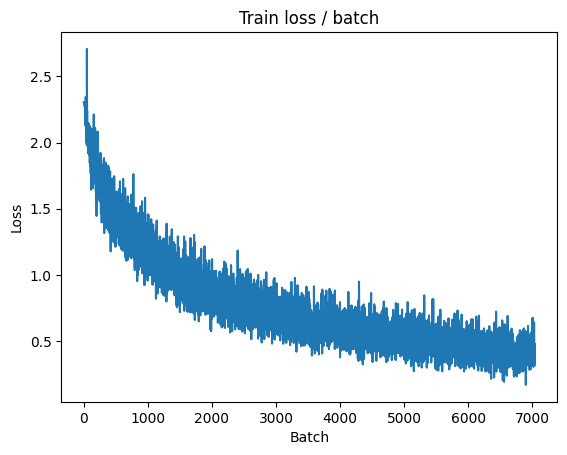

[TRAIN Batch 200/391]	Time 0.010s (0.038s)	Loss 0.3401 (0.3883)	Prec@1  88.3 ( 86.3)	Prec@5 100.0 ( 99.7)


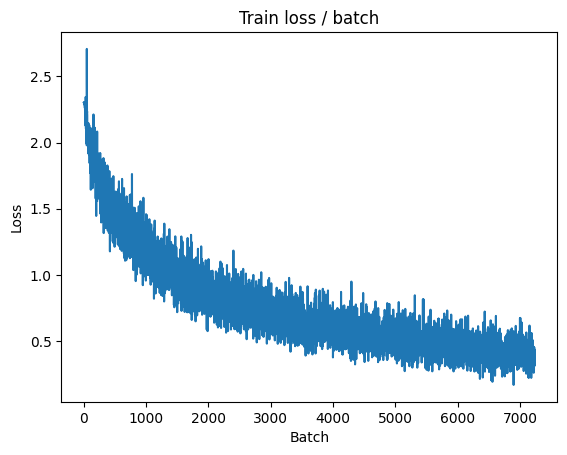


===============> Total time 15s	Avg loss 0.4003	Avg Prec@1 86.01 %	Avg Prec@5 99.60 %

[EVAL Batch 000/079]	Time 0.149s (0.149s)	Loss 0.6849 (0.6849)	Prec@1  78.1 ( 78.1)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6725	Avg Prec@1 78.16 %	Avg Prec@5 98.62 %



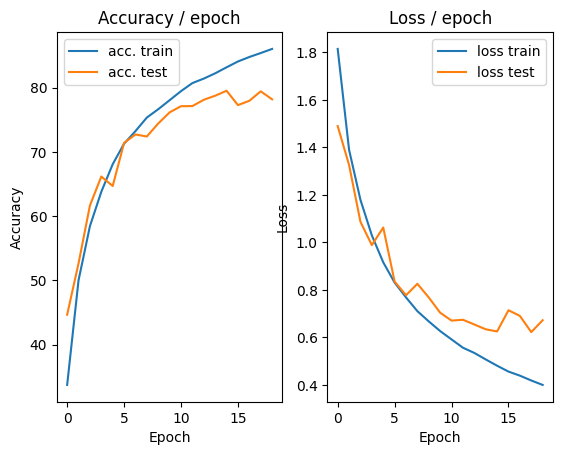

=== EPOCH 20 =====

[TRAIN Batch 000/391]	Time 0.266s (0.266s)	Loss 0.4442 (0.4442)	Prec@1  85.2 ( 85.2)	Prec@5  98.4 ( 98.4)


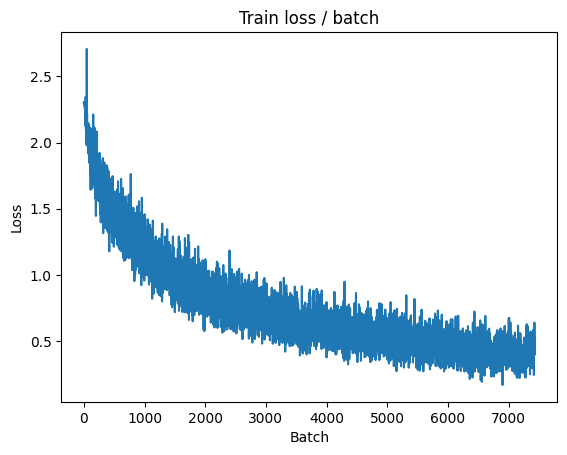

[TRAIN Batch 200/391]	Time 0.011s (0.044s)	Loss 0.5009 (0.3809)	Prec@1  84.4 ( 86.8)	Prec@5 100.0 ( 99.6)


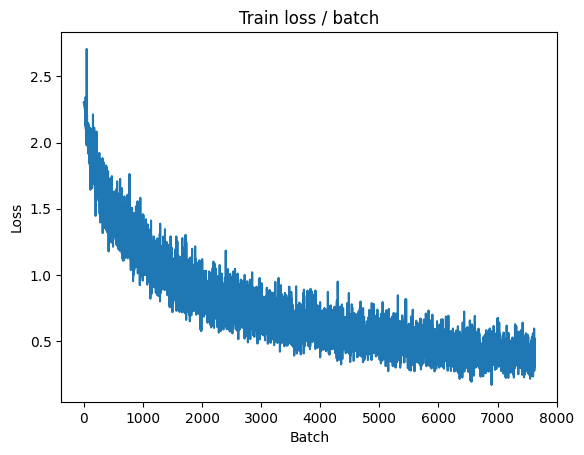


===============> Total time 16s	Avg loss 0.3842	Avg Prec@1 86.68 %	Avg Prec@5 99.60 %

[EVAL Batch 000/079]	Time 0.171s (0.171s)	Loss 0.6440 (0.6440)	Prec@1  76.6 ( 76.6)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.6451	Avg Prec@1 78.97 %	Avg Prec@5 98.88 %



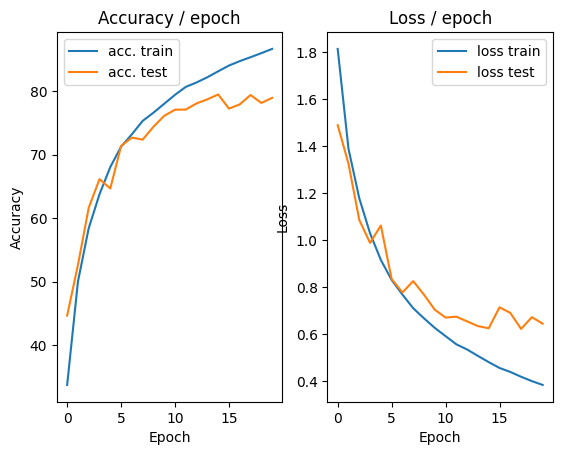

=== EPOCH 1 =====

[TRAIN Batch 000/391]	Time 0.368s (0.368s)	Loss 2.3354 (2.3354)	Prec@1  11.7 ( 11.7)	Prec@5  53.1 ( 53.1)


<Figure size 640x480 with 0 Axes>

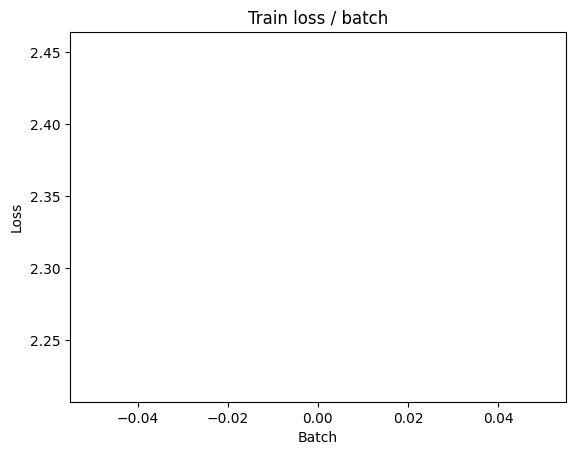

[TRAIN Batch 200/391]	Time 0.054s (0.039s)	Loss 1.5089 (1.6682)	Prec@1  49.2 ( 38.3)	Prec@5  90.6 ( 88.4)


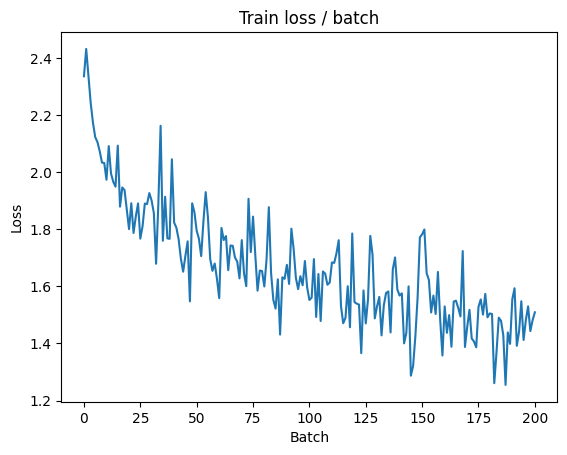


===============> Total time 16s	Avg loss 1.5171	Avg Prec@1 44.15 %	Avg Prec@5 90.95 %

[EVAL Batch 000/079]	Time 0.180s (0.180s)	Loss 1.4031 (1.4031)	Prec@1  52.3 ( 52.3)	Prec@5  92.2 ( 92.2)

===============> Total time 2s	Avg loss 1.4961	Avg Prec@1 46.73 %	Avg Prec@5 93.39 %



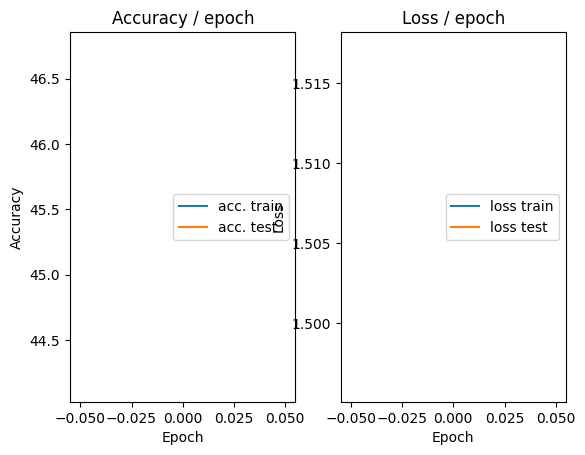

=== EPOCH 2 =====

[TRAIN Batch 000/391]	Time 0.284s (0.284s)	Loss 1.3445 (1.3445)	Prec@1  51.6 ( 51.6)	Prec@5  93.8 ( 93.8)


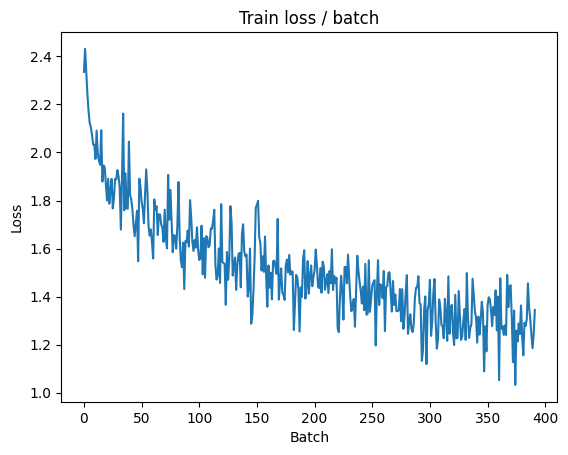

[TRAIN Batch 200/391]	Time 0.065s (0.046s)	Loss 1.0821 (1.1991)	Prec@1  61.7 ( 56.7)	Prec@5  95.3 ( 95.3)


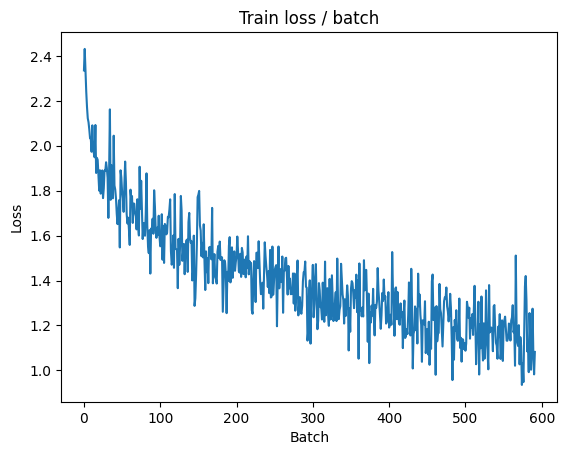


===============> Total time 16s	Avg loss 1.1492	Avg Prec@1 58.78 %	Avg Prec@5 95.68 %

[EVAL Batch 000/079]	Time 0.152s (0.152s)	Loss 1.0337 (1.0337)	Prec@1  70.3 ( 70.3)	Prec@5  94.5 ( 94.5)

===============> Total time 2s	Avg loss 1.0842	Avg Prec@1 62.36 %	Avg Prec@5 96.37 %



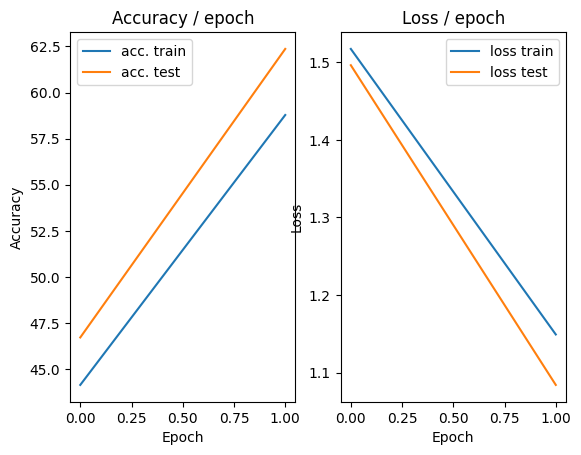

=== EPOCH 3 =====

[TRAIN Batch 000/391]	Time 0.222s (0.222s)	Loss 1.2871 (1.2871)	Prec@1  53.1 ( 53.1)	Prec@5  96.9 ( 96.9)


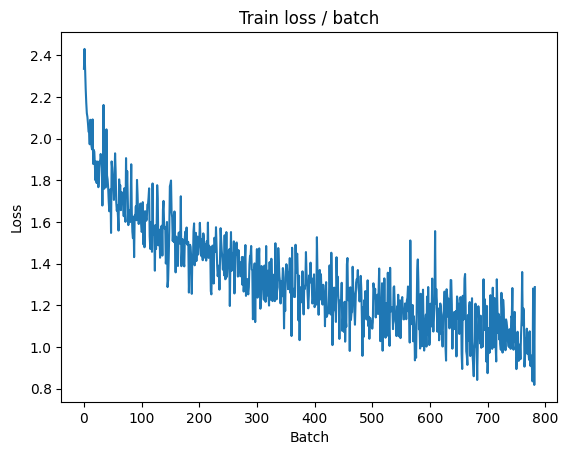

[TRAIN Batch 200/391]	Time 0.025s (0.043s)	Loss 0.8853 (1.0114)	Prec@1  68.8 ( 63.9)	Prec@5  96.9 ( 96.7)


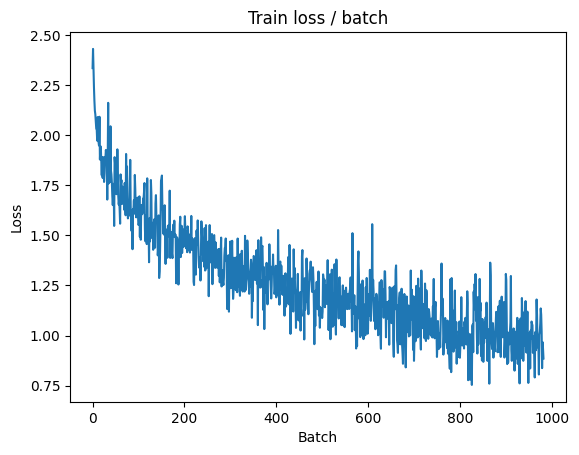


===============> Total time 17s	Avg loss 0.9866	Avg Prec@1 65.04 %	Avg Prec@5 96.92 %

[EVAL Batch 000/079]	Time 0.169s (0.169s)	Loss 0.8386 (0.8386)	Prec@1  72.7 ( 72.7)	Prec@5  96.9 ( 96.9)

===============> Total time 2s	Avg loss 0.9230	Avg Prec@1 67.97 %	Avg Prec@5 97.15 %



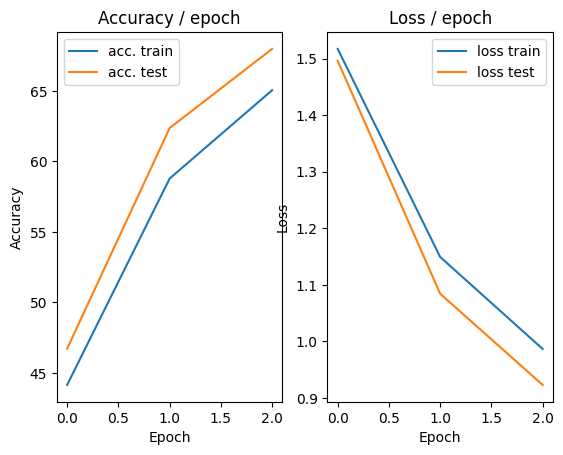

=== EPOCH 4 =====

[TRAIN Batch 000/391]	Time 0.237s (0.237s)	Loss 0.8581 (0.8581)	Prec@1  66.4 ( 66.4)	Prec@5  98.4 ( 98.4)


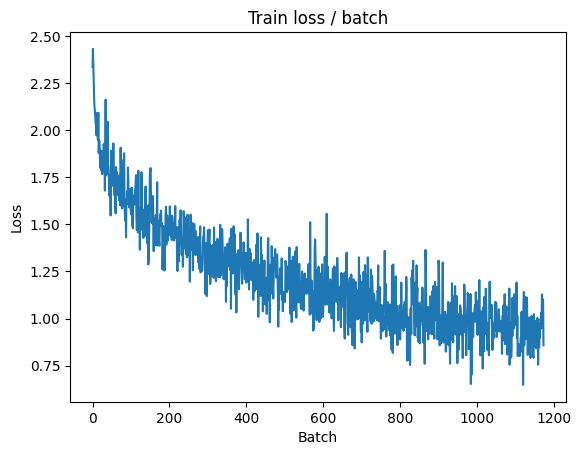

[TRAIN Batch 200/391]	Time 0.094s (0.041s)	Loss 0.8497 (0.8994)	Prec@1  72.7 ( 68.1)	Prec@5  93.8 ( 97.4)


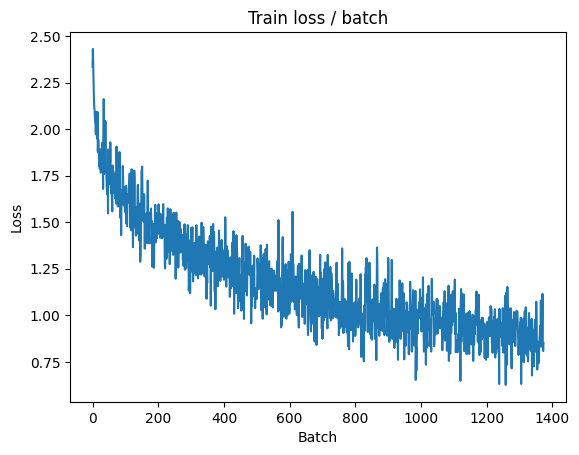


===============> Total time 16s	Avg loss 0.8784	Avg Prec@1 68.93 %	Avg Prec@5 97.58 %

[EVAL Batch 000/079]	Time 0.204s (0.204s)	Loss 0.8291 (0.8291)	Prec@1  68.0 ( 68.0)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.7903	Avg Prec@1 71.66 %	Avg Prec@5 98.13 %



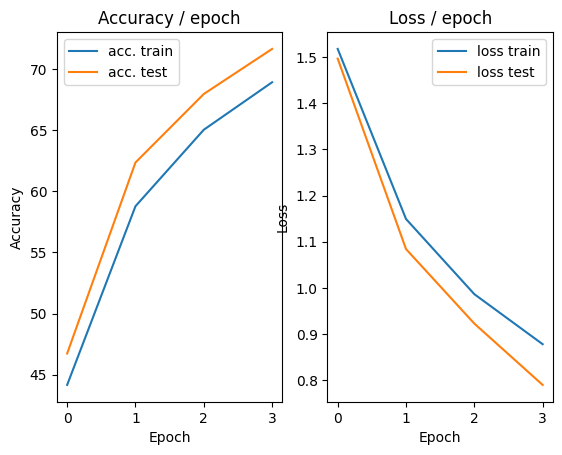

=== EPOCH 5 =====

[TRAIN Batch 000/391]	Time 0.262s (0.262s)	Loss 0.7379 (0.7379)	Prec@1  76.6 ( 76.6)	Prec@5  99.2 ( 99.2)


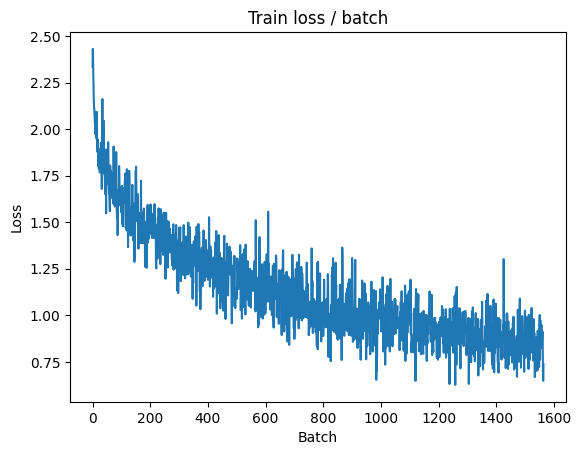

[TRAIN Batch 200/391]	Time 0.034s (0.045s)	Loss 0.7466 (0.8277)	Prec@1  70.3 ( 70.9)	Prec@5  98.4 ( 97.9)


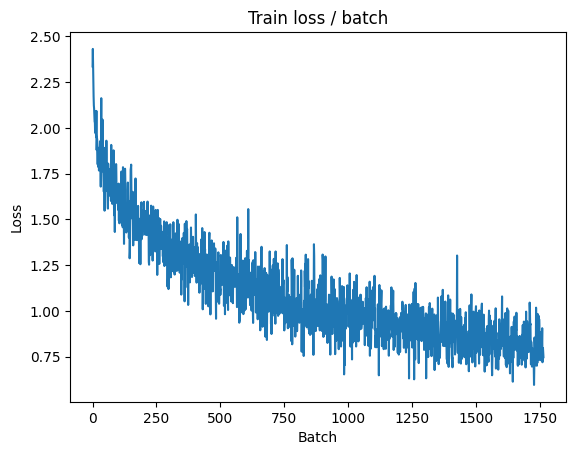


===============> Total time 16s	Avg loss 0.8088	Avg Prec@1 71.54 %	Avg Prec@5 98.00 %

[EVAL Batch 000/079]	Time 0.273s (0.273s)	Loss 0.8774 (0.8774)	Prec@1  70.3 ( 70.3)	Prec@5  96.1 ( 96.1)

===============> Total time 3s	Avg loss 0.8873	Avg Prec@1 69.50 %	Avg Prec@5 97.51 %



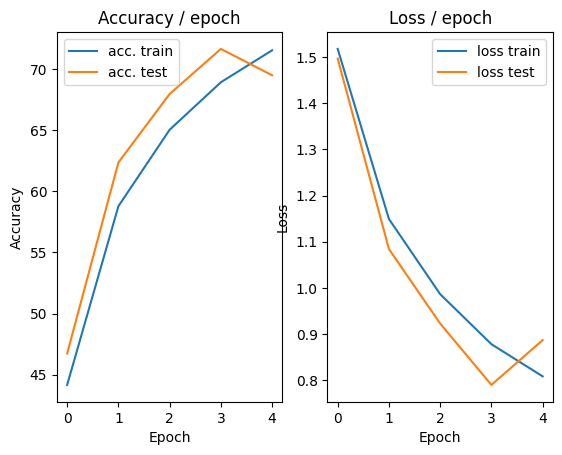

=== EPOCH 6 =====

[TRAIN Batch 000/391]	Time 0.268s (0.268s)	Loss 0.7578 (0.7578)	Prec@1  74.2 ( 74.2)	Prec@5  96.1 ( 96.1)


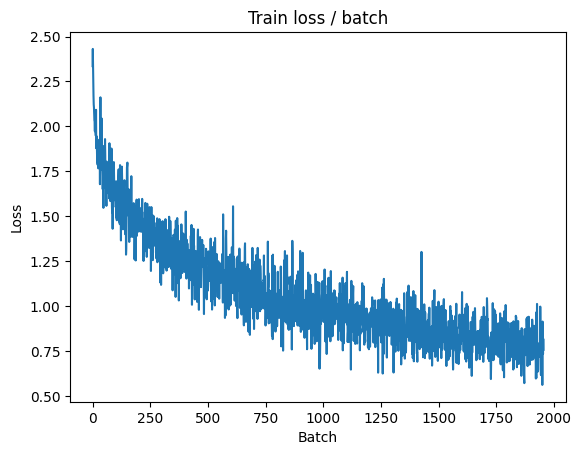

[TRAIN Batch 200/391]	Time 0.065s (0.039s)	Loss 0.7206 (0.7599)	Prec@1  73.4 ( 73.3)	Prec@5 100.0 ( 98.1)


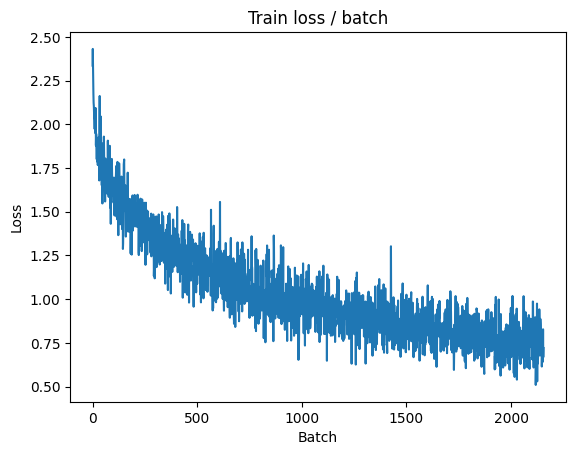


===============> Total time 16s	Avg loss 0.7525	Avg Prec@1 73.60 %	Avg Prec@5 98.12 %

[EVAL Batch 000/079]	Time 0.185s (0.185s)	Loss 0.7347 (0.7347)	Prec@1  75.8 ( 75.8)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.7640	Avg Prec@1 73.57 %	Avg Prec@5 97.84 %



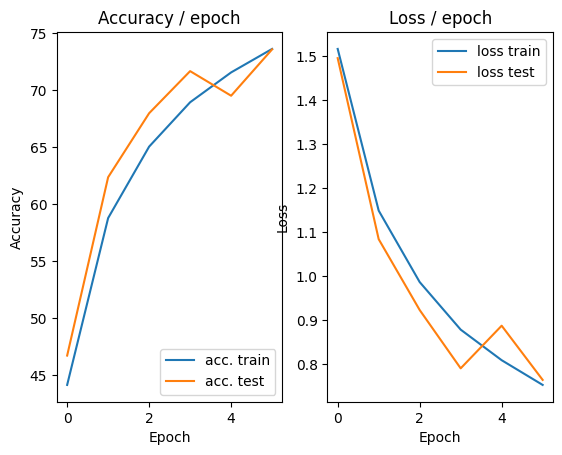

=== EPOCH 7 =====

[TRAIN Batch 000/391]	Time 0.301s (0.301s)	Loss 0.7646 (0.7646)	Prec@1  75.0 ( 75.0)	Prec@5  97.7 ( 97.7)


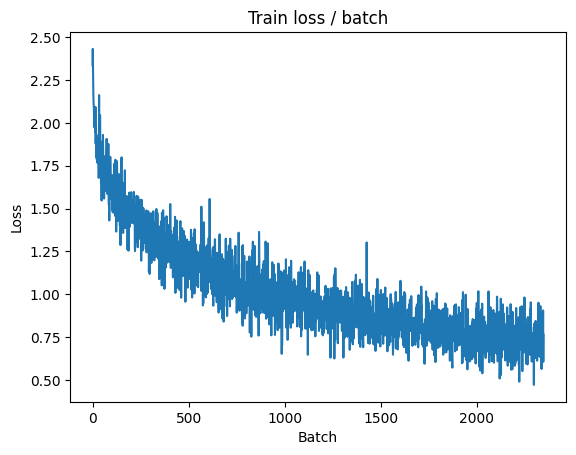

[TRAIN Batch 200/391]	Time 0.013s (0.044s)	Loss 0.8082 (0.7215)	Prec@1  73.4 ( 74.6)	Prec@5  99.2 ( 98.4)


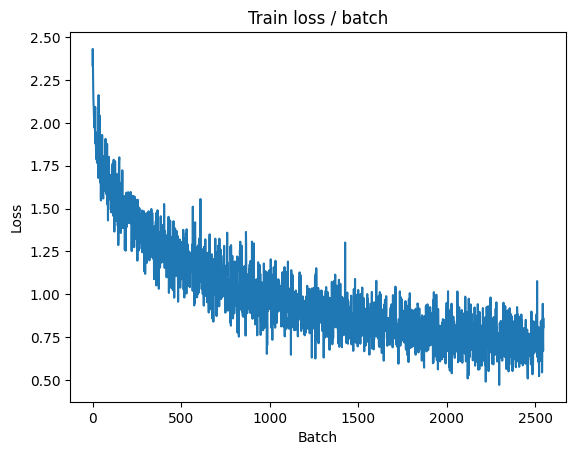


===============> Total time 16s	Avg loss 0.7125	Avg Prec@1 74.97 %	Avg Prec@5 98.39 %

[EVAL Batch 000/079]	Time 0.189s (0.189s)	Loss 0.5863 (0.5863)	Prec@1  80.5 ( 80.5)	Prec@5  98.4 ( 98.4)

===============> Total time 3s	Avg loss 0.6728	Avg Prec@1 76.34 %	Avg Prec@5 98.71 %



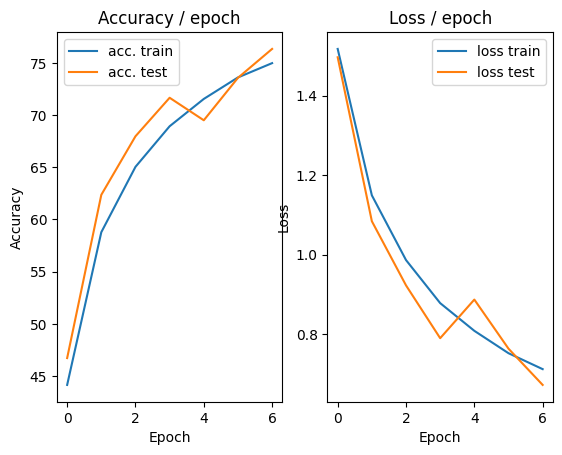

=== EPOCH 8 =====

[TRAIN Batch 000/391]	Time 0.282s (0.282s)	Loss 0.6633 (0.6633)	Prec@1  78.9 ( 78.9)	Prec@5  98.4 ( 98.4)


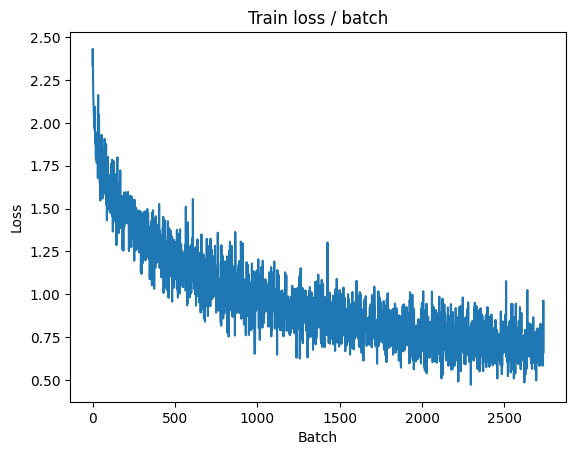

[TRAIN Batch 200/391]	Time 0.015s (0.038s)	Loss 0.6132 (0.6809)	Prec@1  76.6 ( 76.1)	Prec@5  98.4 ( 98.6)


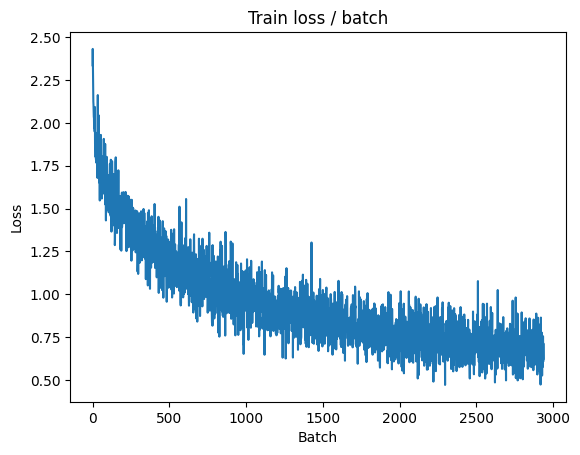


===============> Total time 16s	Avg loss 0.6781	Avg Prec@1 76.22 %	Avg Prec@5 98.56 %

[EVAL Batch 000/079]	Time 0.140s (0.140s)	Loss 0.7142 (0.7142)	Prec@1  76.6 ( 76.6)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6578	Avg Prec@1 76.82 %	Avg Prec@5 98.72 %



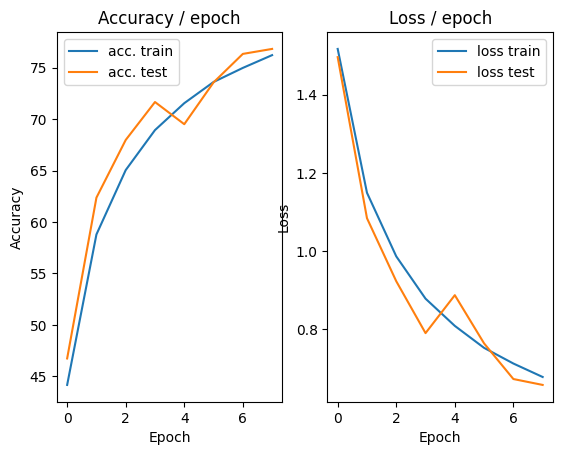

=== EPOCH 9 =====

[TRAIN Batch 000/391]	Time 0.194s (0.194s)	Loss 0.6064 (0.6064)	Prec@1  77.3 ( 77.3)	Prec@5  99.2 ( 99.2)


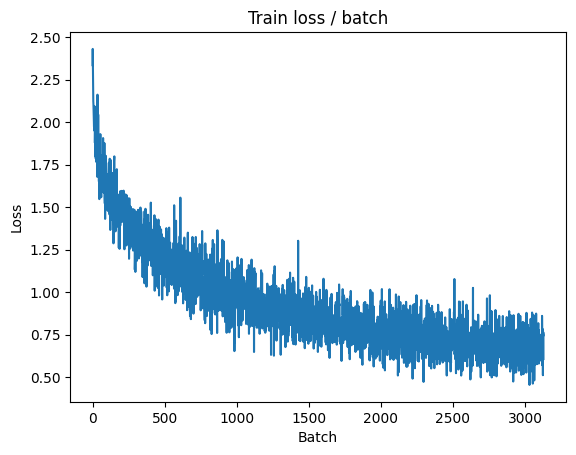

[TRAIN Batch 200/391]	Time 0.010s (0.045s)	Loss 0.6973 (0.6475)	Prec@1  77.3 ( 77.5)	Prec@5  98.4 ( 98.7)


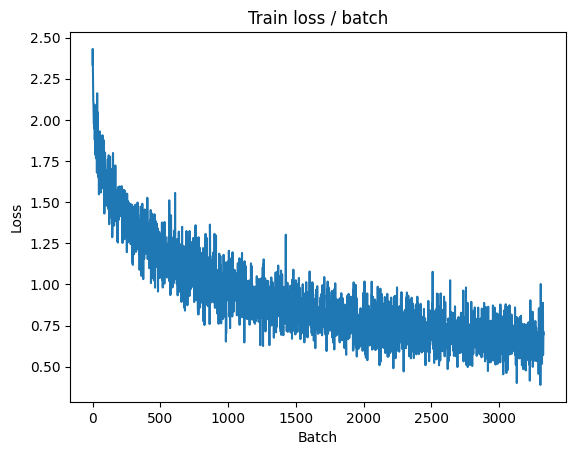


===============> Total time 16s	Avg loss 0.6424	Avg Prec@1 77.62 %	Avg Prec@5 98.70 %

[EVAL Batch 000/079]	Time 0.184s (0.184s)	Loss 0.8009 (0.8009)	Prec@1  71.9 ( 71.9)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.7672	Avg Prec@1 73.93 %	Avg Prec@5 98.52 %



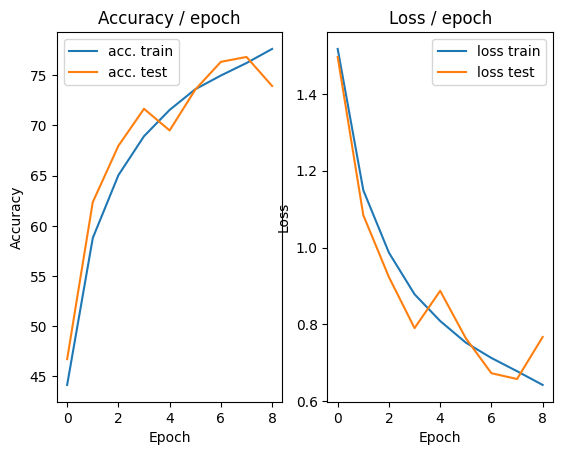

=== EPOCH 10 =====

[TRAIN Batch 000/391]	Time 0.206s (0.206s)	Loss 0.7919 (0.7919)	Prec@1  72.7 ( 72.7)	Prec@5  99.2 ( 99.2)


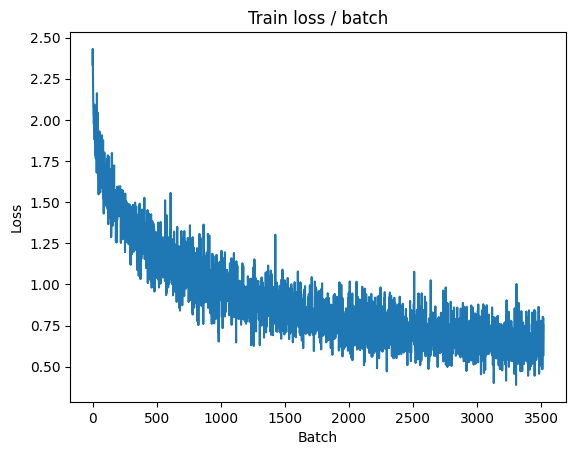

[TRAIN Batch 200/391]	Time 0.011s (0.043s)	Loss 0.6768 (0.6134)	Prec@1  74.2 ( 78.7)	Prec@5  98.4 ( 98.9)


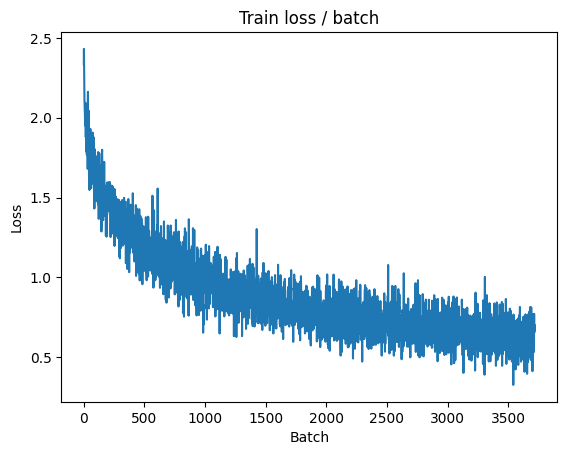


===============> Total time 16s	Avg loss 0.6159	Avg Prec@1 78.60 %	Avg Prec@5 98.80 %

[EVAL Batch 000/079]	Time 0.196s (0.196s)	Loss 0.8072 (0.8072)	Prec@1  72.7 ( 72.7)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.8304	Avg Prec@1 70.56 %	Avg Prec@5 98.45 %



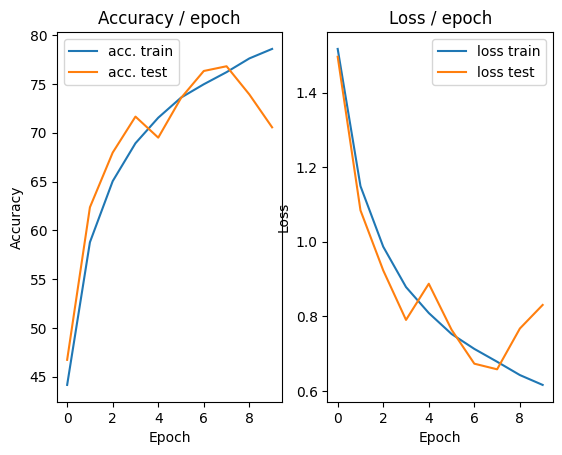

=== EPOCH 11 =====

[TRAIN Batch 000/391]	Time 0.286s (0.286s)	Loss 0.6712 (0.6712)	Prec@1  78.1 ( 78.1)	Prec@5  98.4 ( 98.4)


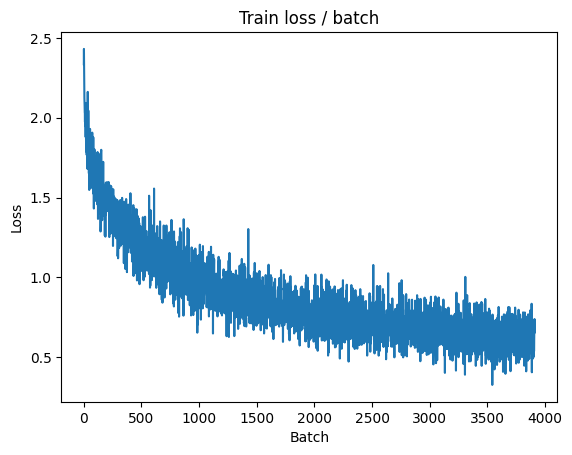

[TRAIN Batch 200/391]	Time 0.094s (0.042s)	Loss 0.6564 (0.5908)	Prec@1  78.9 ( 79.5)	Prec@5 100.0 ( 99.0)


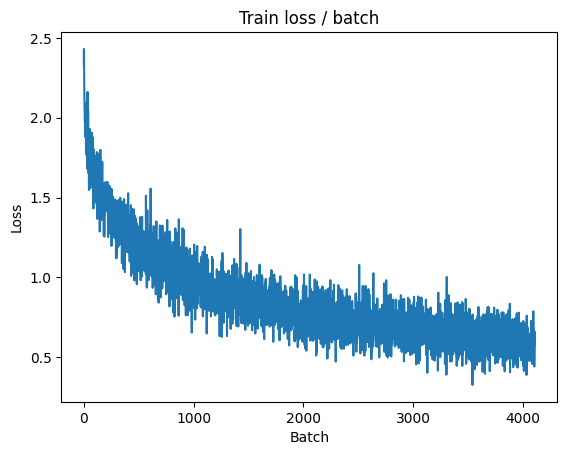


===============> Total time 16s	Avg loss 0.5899	Avg Prec@1 79.47 %	Avg Prec@5 98.88 %

[EVAL Batch 000/079]	Time 0.182s (0.182s)	Loss 0.5906 (0.5906)	Prec@1  83.6 ( 83.6)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.6032	Avg Prec@1 79.11 %	Avg Prec@5 98.80 %



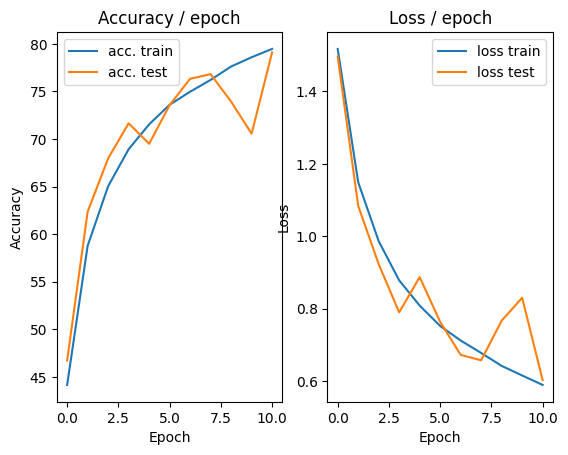

=== EPOCH 12 =====

[TRAIN Batch 000/391]	Time 0.247s (0.247s)	Loss 0.4988 (0.4988)	Prec@1  83.6 ( 83.6)	Prec@5 100.0 (100.0)


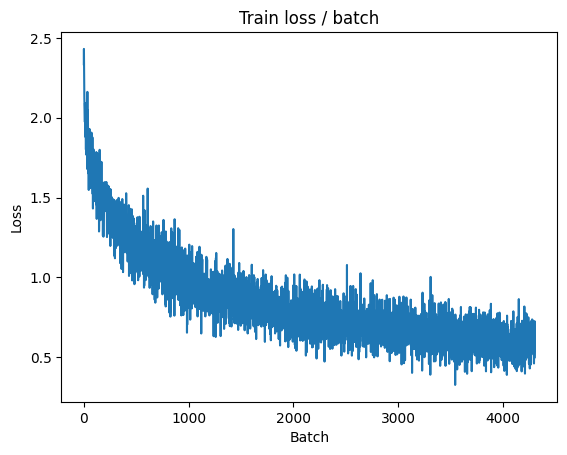

[TRAIN Batch 200/391]	Time 0.046s (0.044s)	Loss 0.5876 (0.5695)	Prec@1  82.8 ( 80.2)	Prec@5 100.0 ( 99.0)


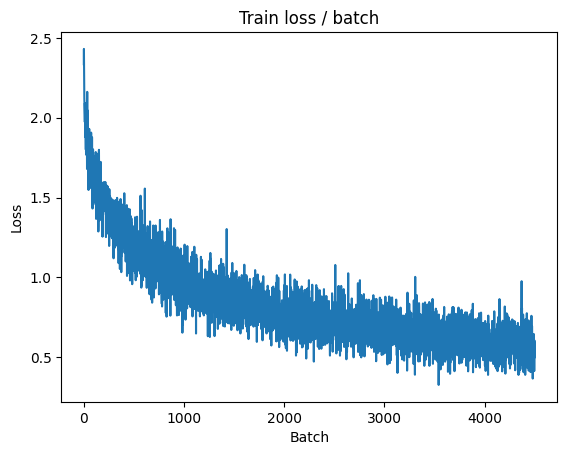


===============> Total time 16s	Avg loss 0.5692	Avg Prec@1 80.29 %	Avg Prec@5 98.97 %

[EVAL Batch 000/079]	Time 0.194s (0.194s)	Loss 0.6133 (0.6133)	Prec@1  82.8 ( 82.8)	Prec@5  98.4 ( 98.4)

===============> Total time 3s	Avg loss 0.6681	Avg Prec@1 77.41 %	Avg Prec@5 98.69 %



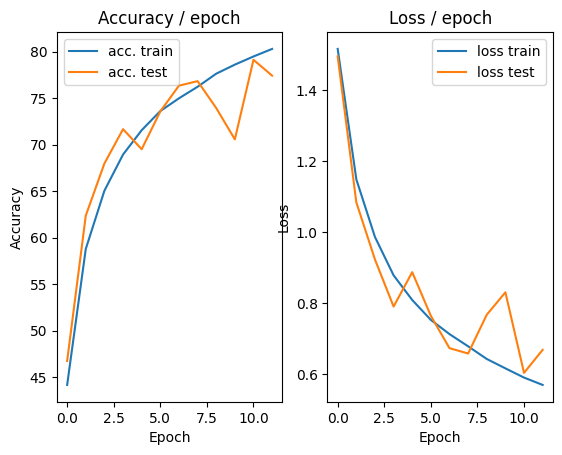

=== EPOCH 13 =====

[TRAIN Batch 000/391]	Time 0.245s (0.245s)	Loss 0.6773 (0.6773)	Prec@1  79.7 ( 79.7)	Prec@5  97.7 ( 97.7)


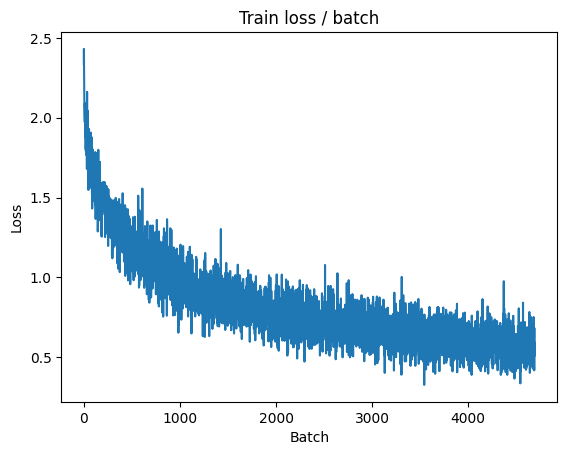

[TRAIN Batch 200/391]	Time 0.014s (0.039s)	Loss 0.5053 (0.5532)	Prec@1  82.8 ( 80.7)	Prec@5  99.2 ( 99.0)


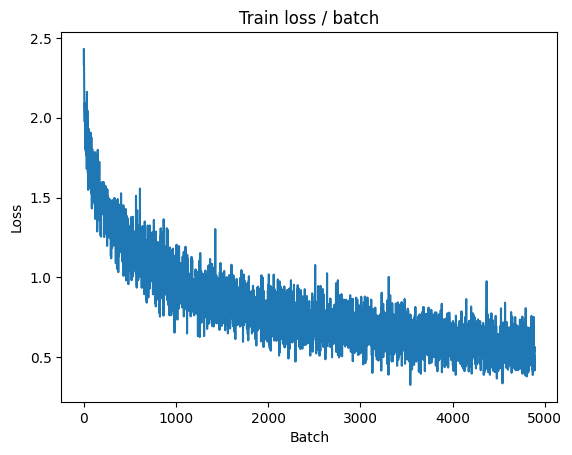


===============> Total time 16s	Avg loss 0.5524	Avg Prec@1 80.81 %	Avg Prec@5 99.02 %

[EVAL Batch 000/079]	Time 0.160s (0.160s)	Loss 0.7119 (0.7119)	Prec@1  75.0 ( 75.0)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.7151	Avg Prec@1 75.42 %	Avg Prec@5 98.64 %



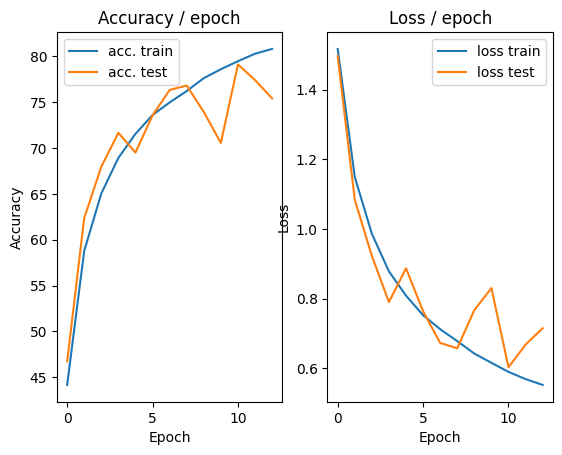

=== EPOCH 14 =====

[TRAIN Batch 000/391]	Time 0.243s (0.243s)	Loss 0.4438 (0.4438)	Prec@1  85.2 ( 85.2)	Prec@5 100.0 (100.0)


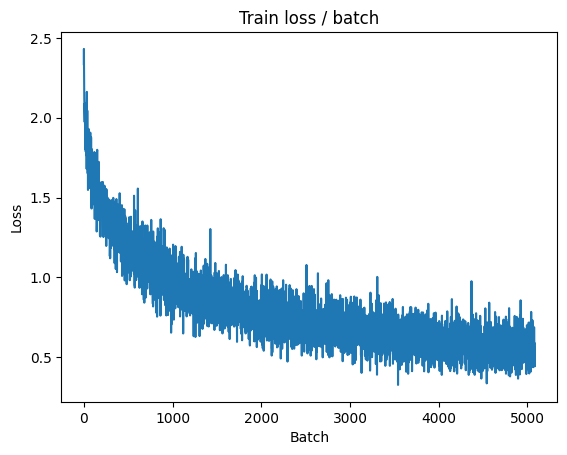

[TRAIN Batch 200/391]	Time 0.045s (0.045s)	Loss 0.6419 (0.5333)	Prec@1  79.7 ( 81.7)	Prec@5  97.7 ( 99.1)


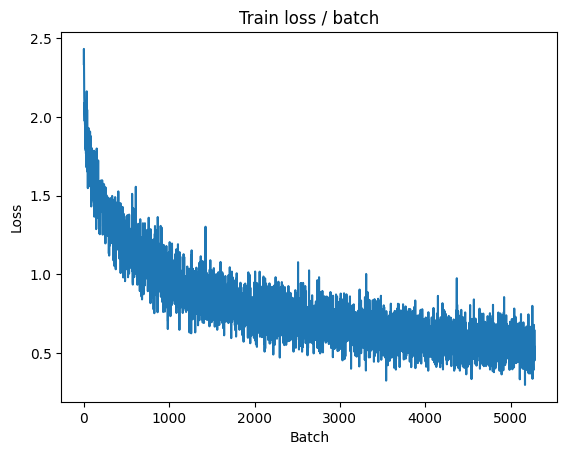


===============> Total time 16s	Avg loss 0.5332	Avg Prec@1 81.54 %	Avg Prec@5 99.12 %

[EVAL Batch 000/079]	Time 0.175s (0.175s)	Loss 0.5127 (0.5127)	Prec@1  83.6 ( 83.6)	Prec@5 100.0 (100.0)

===============> Total time 3s	Avg loss 0.5330	Avg Prec@1 81.83 %	Avg Prec@5 99.10 %



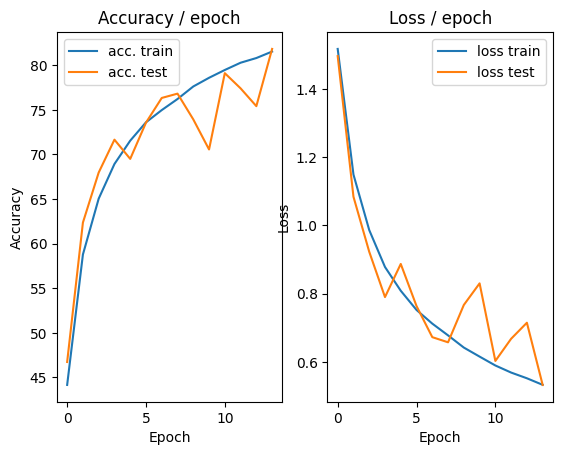

=== EPOCH 15 =====

[TRAIN Batch 000/391]	Time 0.360s (0.360s)	Loss 0.3564 (0.3564)	Prec@1  90.6 ( 90.6)	Prec@5 100.0 (100.0)


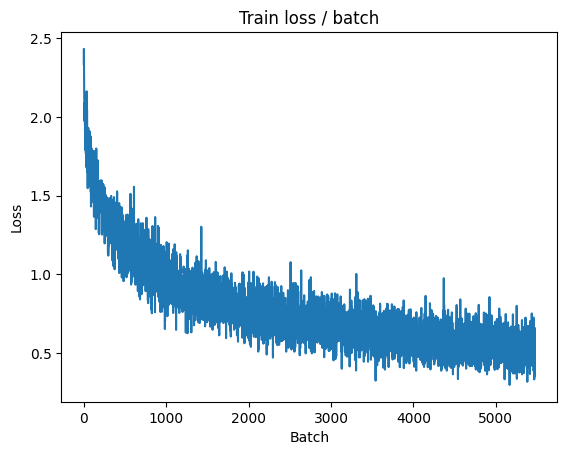

[TRAIN Batch 200/391]	Time 0.028s (0.039s)	Loss 0.4353 (0.5104)	Prec@1  83.6 ( 82.3)	Prec@5  99.2 ( 99.2)


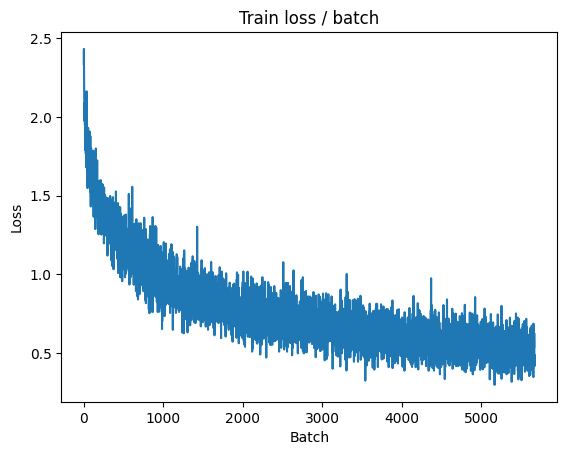


===============> Total time 15s	Avg loss 0.5160	Avg Prec@1 81.95 %	Avg Prec@5 99.15 %

[EVAL Batch 000/079]	Time 0.205s (0.205s)	Loss 0.5971 (0.5971)	Prec@1  79.7 ( 79.7)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.5466	Avg Prec@1 81.09 %	Avg Prec@5 98.93 %



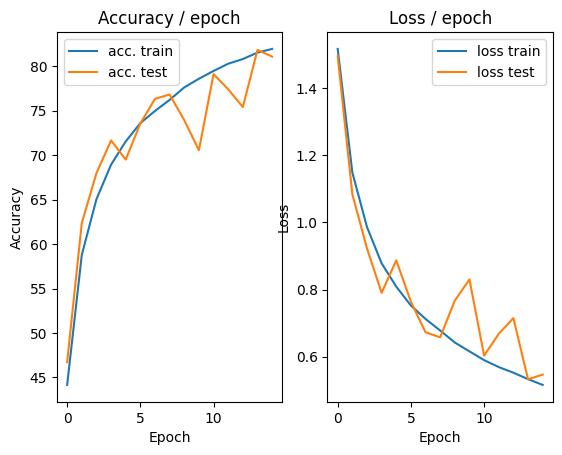

=== EPOCH 16 =====

[TRAIN Batch 000/391]	Time 0.280s (0.280s)	Loss 0.5238 (0.5238)	Prec@1  81.2 ( 81.2)	Prec@5  99.2 ( 99.2)


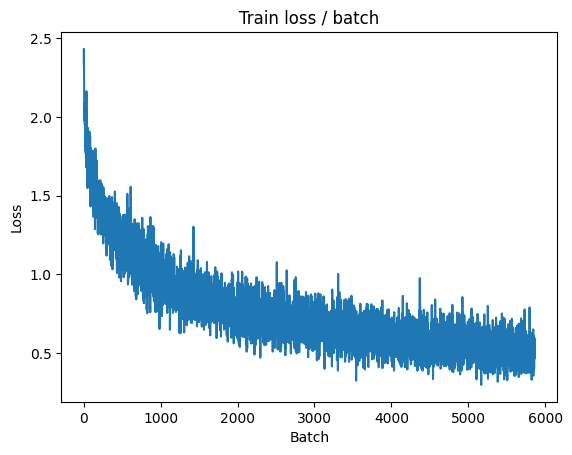

[TRAIN Batch 200/391]	Time 0.056s (0.046s)	Loss 0.5639 (0.4943)	Prec@1  82.8 ( 82.7)	Prec@5  99.2 ( 99.3)


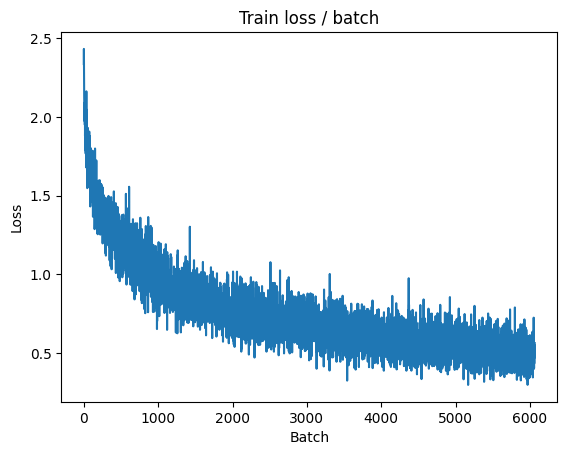


===============> Total time 16s	Avg loss 0.5031	Avg Prec@1 82.44 %	Avg Prec@5 99.26 %

[EVAL Batch 000/079]	Time 0.159s (0.159s)	Loss 0.6835 (0.6835)	Prec@1  75.8 ( 75.8)	Prec@5  97.7 ( 97.7)

===============> Total time 2s	Avg loss 0.5936	Avg Prec@1 79.88 %	Avg Prec@5 98.77 %



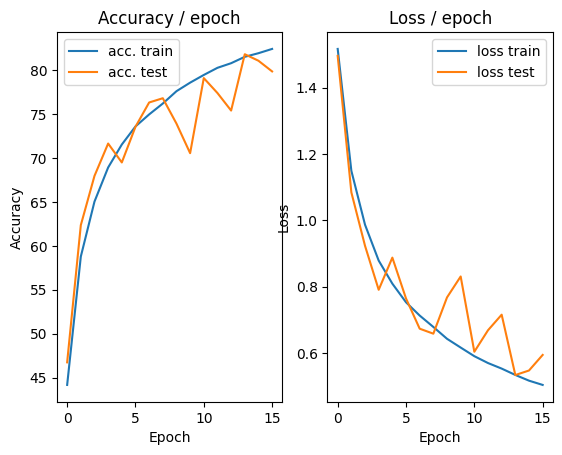

=== EPOCH 17 =====

[TRAIN Batch 000/391]	Time 0.344s (0.344s)	Loss 0.3322 (0.3322)	Prec@1  86.7 ( 86.7)	Prec@5 100.0 (100.0)


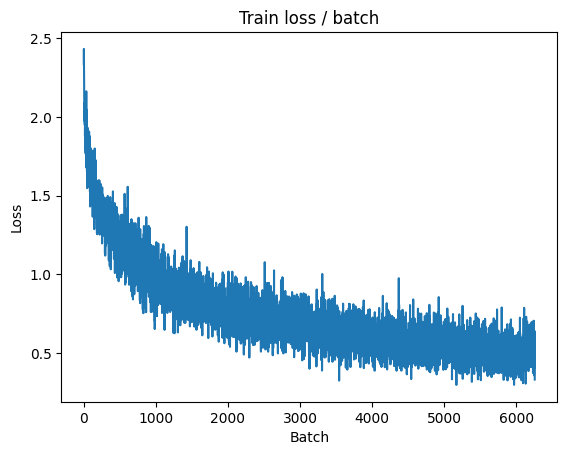

[TRAIN Batch 200/391]	Time 0.048s (0.044s)	Loss 0.4575 (0.4840)	Prec@1  85.2 ( 83.3)	Prec@5  98.4 ( 99.2)


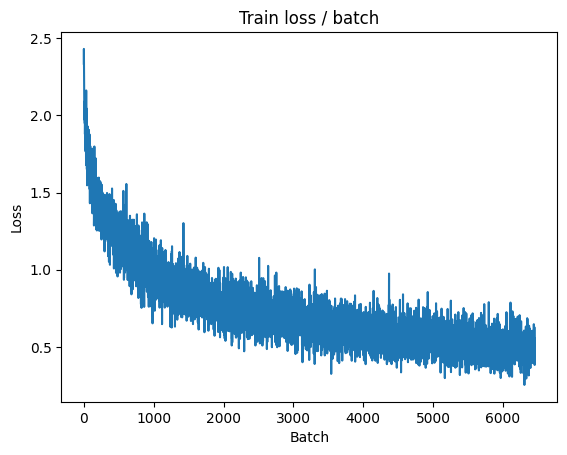


===============> Total time 17s	Avg loss 0.4843	Avg Prec@1 83.19 %	Avg Prec@5 99.26 %

[EVAL Batch 000/079]	Time 0.194s (0.194s)	Loss 0.6820 (0.6820)	Prec@1  75.0 ( 75.0)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.5932	Avg Prec@1 79.89 %	Avg Prec@5 99.01 %



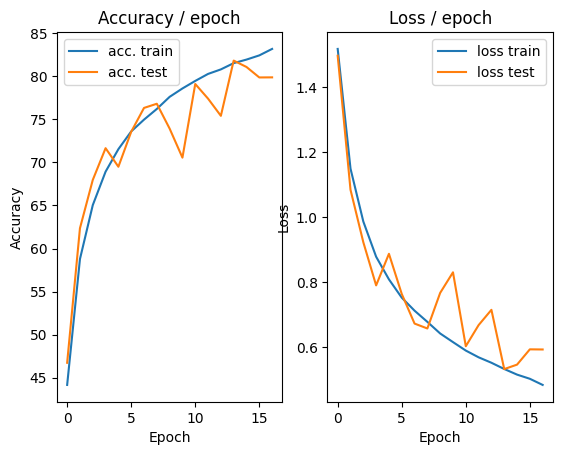

=== EPOCH 18 =====

[TRAIN Batch 000/391]	Time 0.304s (0.304s)	Loss 0.4887 (0.4887)	Prec@1  84.4 ( 84.4)	Prec@5 100.0 (100.0)


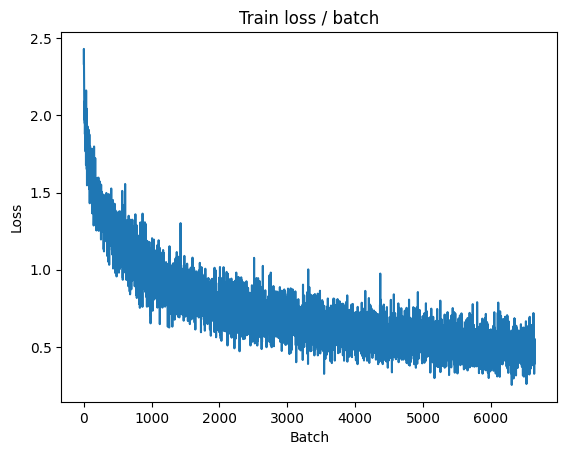

[TRAIN Batch 200/391]	Time 0.107s (0.041s)	Loss 0.7198 (0.4686)	Prec@1  77.3 ( 83.6)	Prec@5  97.7 ( 99.4)


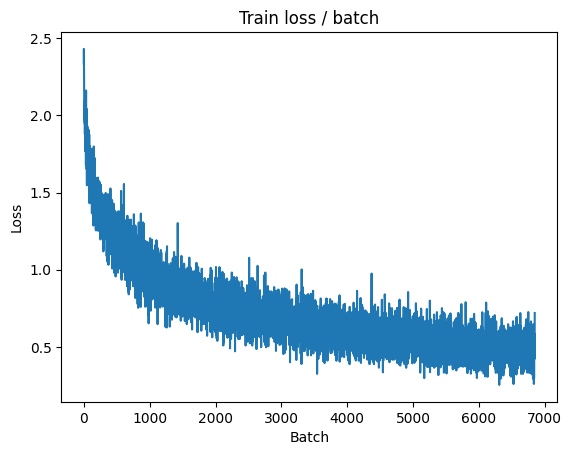


===============> Total time 15s	Avg loss 0.4663	Avg Prec@1 83.74 %	Avg Prec@5 99.34 %

[EVAL Batch 000/079]	Time 0.211s (0.211s)	Loss 0.6301 (0.6301)	Prec@1  82.0 ( 82.0)	Prec@5  99.2 ( 99.2)

===============> Total time 2s	Avg loss 0.5900	Avg Prec@1 79.72 %	Avg Prec@5 99.10 %



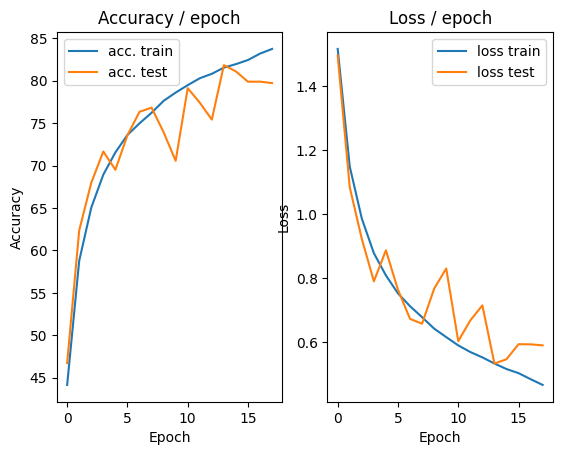

=== EPOCH 19 =====

[TRAIN Batch 000/391]	Time 0.230s (0.230s)	Loss 0.3608 (0.3608)	Prec@1  88.3 ( 88.3)	Prec@5 100.0 (100.0)


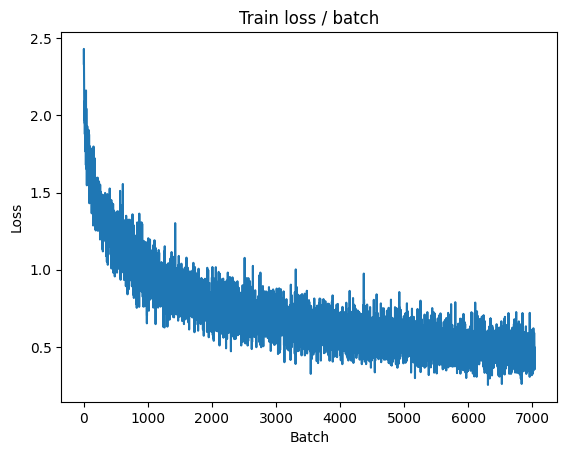

[TRAIN Batch 200/391]	Time 0.041s (0.044s)	Loss 0.3272 (0.4574)	Prec@1  89.1 ( 83.9)	Prec@5 100.0 ( 99.3)


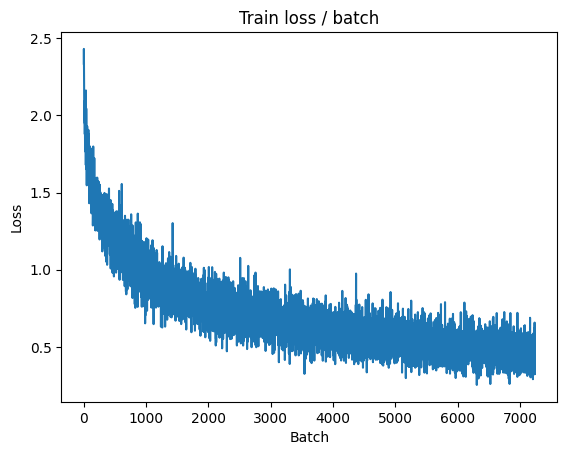


===============> Total time 16s	Avg loss 0.4555	Avg Prec@1 84.01 %	Avg Prec@5 99.33 %

[EVAL Batch 000/079]	Time 0.204s (0.204s)	Loss 0.5840 (0.5840)	Prec@1  83.6 ( 83.6)	Prec@5  96.1 ( 96.1)

===============> Total time 3s	Avg loss 0.5667	Avg Prec@1 80.52 %	Avg Prec@5 99.09 %



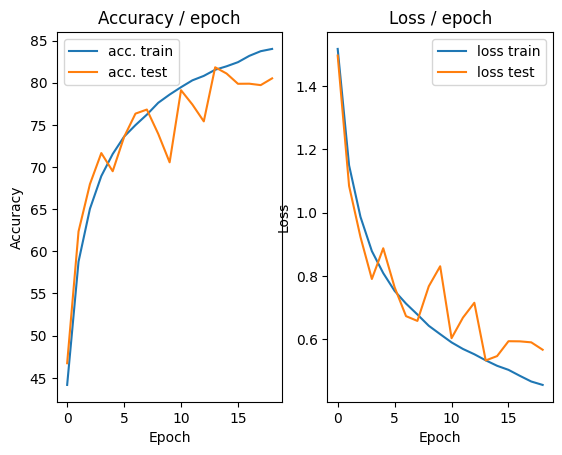

=== EPOCH 20 =====

[TRAIN Batch 000/391]	Time 1.123s (1.123s)	Loss 0.3108 (0.3108)	Prec@1  89.8 ( 89.8)	Prec@5  98.4 ( 98.4)


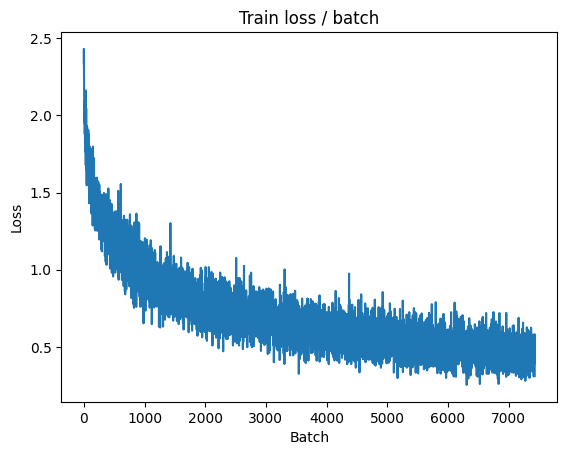

[TRAIN Batch 200/391]	Time 0.062s (0.043s)	Loss 0.5257 (0.4354)	Prec@1  81.2 ( 84.6)	Prec@5  99.2 ( 99.5)


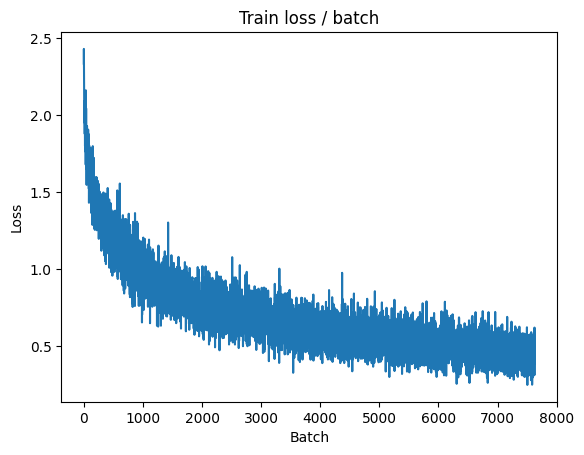


===============> Total time 17s	Avg loss 0.4411	Avg Prec@1 84.51 %	Avg Prec@5 99.42 %

[EVAL Batch 000/079]	Time 0.188s (0.188s)	Loss 0.5414 (0.5414)	Prec@1  81.2 ( 81.2)	Prec@5  98.4 ( 98.4)

===============> Total time 2s	Avg loss 0.5274	Avg Prec@1 81.78 %	Avg Prec@5 98.97 %



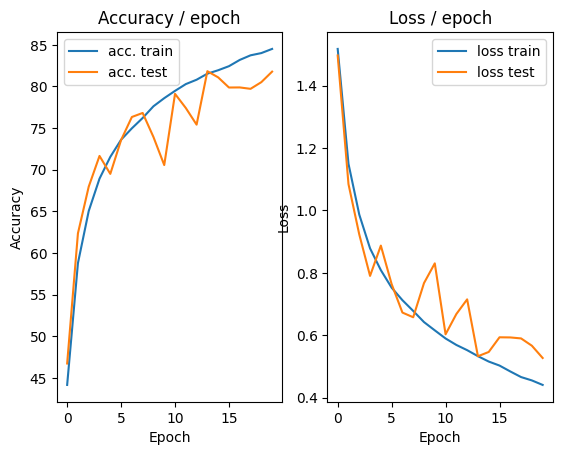

81.78401898734177

In [5]:
main(128, 0.1, cuda=True)
main_cifar(128, 0.1, epochs=20, cuda=True)
main_cifar(128, 0.1, epochs=20, cuda=True, normalize=True, augment=True)
main_cifar(128, 0.1, epochs=20, cuda=True, normalize=True, augment=True, batchnorm=True, dropout=0.5)